<img src="https://www.javeriana.edu.co/recursosdb/20125/5571273/escudo-circular.png" alt="Escudo" style="float:left;width:70px;">

<div align="center">

# Pontificia Universidad Javeriana

## Taller de Procesamiento de Lenguaje Natural

### TALLER-2 — Construcción de Ontología y Análisis Semántico con WordNet

**Integrantes**: Erika Valeria Rivera Jiménez — Julián Guillermo Carrillo Meneses — Carlos Andrés Garnica Salazar — Oscar Andrés Prieto Moreno

**Fuente de datos**: Tesauro de la Comisión de la Verdad (CEV) — 2022

---

</div>


# Sec00 — Setup del entorno, imports y constantes del proyecto

Este bloque concentra, al inicio del notebook:
1. Instalación de dependencias y descarga de corpus NLTK (solo primera vez).
2. **TODOS los imports** de librerías usadas en el notebook (una sola vez).
3. **TODAS las constantes** del proyecto (rutas, colores, umbrales, nombres).

Las constantes de dominio de los algoritmos (SLUG_RAIZ, EJE_POR_GRUPO,
umbrales IDF, STOPWORDS, TOKENS_GENERICOS) viven en la sección 00b junto a
las clases que las consumen (un solo lugar de definición por concepto).

**Cómo ejecutarlo**: localmente desde `TALLER-2/notebooks/` (rutas relativas);
en Google Colab, subiendo la carpeta `TALLER-2` completa.

In [1]:
"""Instalación de dependencias (solo necesario la primera vez en Colab)."""
import importlib.util
import subprocess
import sys


def instalar_si_falta(paquetes: list[str]) -> None:
    """Instala paquetes pip que no estén disponibles, en silencio.

    Args:
        paquetes: Lista de nombres de paquetes a verificar/instalar.
    """
    faltantes = [p for p in paquetes if importlib.util.find_spec(p) is None]
    if not faltantes:
        print("Dependencias ya instaladas:", ", ".join(paquetes))
        return
    print("Instalando:", ", ".join(faltantes))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *faltantes])


instalar_si_falta(
    ["owlready2", "rdflib", "nltk", "pandas", "matplotlib", "seaborn", "networkx"]
)

Dependencias ya instaladas: owlready2, rdflib, nltk, pandas, matplotlib, seaborn, networkx


In [2]:
"""Descarga de corpus NLTK (WordNet + Open Multilingual WordNet 1.4)."""
import nltk

for corpus in ("wordnet", "omw-1.4"):
    try:
        nltk.data.find(f"corpora/{corpus}")
        print(f"[OK] corpus '{corpus}' presente")
    except LookupError:
        print(f"Descargando corpus '{corpus}' ...")
        nltk.download(corpus)

Descargando corpus 'wordnet' ...
Descargando corpus 'omw-1.4' ...


[nltk_data] Downloading package wordnet to /home/carlos/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /home/carlos/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [3]:
"""TODOS los imports del proyecto (una sola vez; las secciones los reutilizan).

Se importa además el núcleo POO embebido a continuación (sec00_clases): sus
clases usan estas mismas librerías, ya cargadas en este punto.
"""
import json  # noqa: F401
import os
import re  # noqa: F401
import time  # noqa: F401
import types  # noqa: F401
import unicodedata  # noqa: F401
from abc import ABC, abstractmethod  # noqa: F401
from collections import Counter, defaultdict  # noqa: F401
from dataclasses import dataclass, field  # noqa: F401
from itertools import combinations  # noqa: F401
from pathlib import Path
from typing import Any, ClassVar  # noqa: F401

import matplotlib  # noqa: F401
import matplotlib.pyplot as plt
import networkx as nx  # noqa: F401
import numpy as np  # noqa: F401
import pandas as pd  # noqa: F401
import rdflib  # noqa: F401
import seaborn as sns
from IPython.display import display  # noqa: F401
from nltk.corpus import wordnet as wn  # noqa: F401
from owlready2 import (
    AnnotationProperty,  # noqa: F401
    ObjectProperty,  # noqa: F401
    Restriction,  # noqa: F401
    SymmetricProperty,  # noqa: F401
    Thing,  # noqa: F401
    get_ontology,  # noqa: F401
)

# Backend inline: las figuras (plt.show) quedan embebidas en el notebook.
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    pass  # ejecución como script: backend por defecto

In [4]:
"""TODAS las constantes del proyecto.

Rutas (relativas al notebook: la estructura del repositorio es TALLER-2 con
data/, imagenes/, ontologia/, notebooks/, notebook_cells/), colores por grupo,
nombres de los 5 grupos, tipos de relación WordNet e IRI de la ontología.
"""


def _ruta_base() -> Path:
    """Directorio raíz del proyecto TALLER-2 (portátil: cualquier máquina).

    Estrategia de resolución en orden:
    1. Modo script (notebook_cells/): el archivo sabe su ubicación.
    2. Modo notebook: el kernel corre en algún lugar dentro del proyecto;
       se busca la raíz probando candidatos: el directorio actual, su padre
       y el padre del padre, eligiendo el primero que contenga `data/`
       con el Excel del tesauro. Esto permite abrir el notebook desde
       `notebooks/`, desde la raíz o desde cualquier subcarpeta, tanto en
       Colab (carpeta subida) como en una máquina local con el ZIP
       descomprimido en cualquier ubicación.
    """
    try:
        return Path(__file__).resolve().parent.parent
    except NameError:
        cwd = Path(os.getcwd()).resolve()
        candidatos = [cwd, cwd.parent, cwd.parent.parent, cwd / "notebooks"]
        for candidato in candidatos:
            if (candidato / "data" / "tesauro_orginal_cev.xlsx").exists():
                return candidato
        return cwd.parent  # último recurso (comportamiento previo)


RUTA_BASE = _ruta_base()
RUTA_DATOS = RUTA_BASE / "data"
RUTA_IMAGENES = RUTA_BASE / "imagenes"
RUTA_ONTOLOGIA_DIR = RUTA_BASE / "ontologia"
RUTA_NOTEBOOKS = RUTA_BASE / "notebooks"
RUTA_CELDAS = RUTA_BASE / "notebook_cells"

# Archivos de datos y resultados
RUTA_EXCEL = RUTA_DATOS / "tesauro_orginal_cev.xlsx"
RUTA_JSON_GRUPOS = RUTA_DATOS / "grupos_seleccionados.json"
RUTA_CSV_COBERTURA = RUTA_DATOS / "cobertura_wordnet_grupos.csv"
RUTA_CSV_WORDNET = RUTA_DATOS / "wordnet_relaciones.csv"
RUTA_CSV_GRAFO = RUTA_DATOS / "grafo_relaciones_edges.csv"

# Ontología
IRI_BASE = "http://www.semanticweb.org/cev/tesauro#"
RUTA_ONTOLOGIA = RUTA_ONTOLOGIA_DIR / "tesauro_cev.owl"
RUTA_TRAZABILIDAD = RUTA_ONTOLOGIA_DIR / "relaciones_afines.txt"

# Figuras (imagenes/)
FIGURAS = {
    "top_grupos": RUTA_IMAGENES / "barras_top_grupos.png",
    "profundidad": RUTA_IMAGENES / "profundidad_grupos.png",
    "tipos_termino": RUTA_IMAGENES / "distribucion_tipos_termino.png",
    "heatmap_nivel": RUTA_IMAGENES / "heatmap_terminos_grupos_nivel.png",
    "arbol_grupo": RUTA_IMAGENES / "arbol_jerarquico_armas.png",
    "cobertura_grupos": RUTA_IMAGENES / "cobertura_wordnet_grupos.png",
    "arbol_ontologia": RUTA_IMAGENES / "arbol_ontologia.png",
    "grafo_completo": RUTA_IMAGENES / "grafo_ontologia_completo.png",
    "grafo_grupos": RUTA_IMAGENES / "grafo_ontologia_grupos.png",
    "cobertura_conceptos": RUTA_IMAGENES / "cobertura_wordnet_conceptos.png",
    "heatmap_relaciones": RUTA_IMAGENES / "heatmap_relaciones_grupos.png",
    "top_conceptos": RUTA_IMAGENES / "top_relaciones_conceptos.png",
    "grafo_relaciones": RUTA_IMAGENES / "grafo_relaciones_conceptos.png",
    "profundidad_cobertura": RUTA_IMAGENES / "profundidad_versus_cobertura.png",
}

# Los 5 grupos seleccionados (sección 02) y sus ejes conceptuales
GRUPOS_SELECCIONADOS: tuple[str, ...] = (
    "Actores armados y otros participantes en las dinámicas de la guerra",
    "Impactos",
    "Armas",
    "Poblaciones",
    "Hechos victimizantes",
    "Afrontamientos y resistencias no violentas - cotidianas",
)
EJES_POR_GRUPO: dict[str, str] = {
    "Actores armados y otros participantes en las dinámicas de la guerra": "agentes",
    "Impactos": "estados_efectos",
    "Armas": "instrumentos",
    "Poblaciones": "poblaciones",
    "Hechos victimizantes": "eventos",
    "Afrontamientos y resistencias no violentas - cotidianas": "afrontamientos_resistencias",
}

# Colores por grupo (figuras)
COLORES_GRUPO: dict[str, str] = {
    "Actores armados y otros participantes en las dinámicas de la guerra": "#d62728",
    "Impactos": "#1f77b4",
    "Armas": "#2ca02c",
    "Poblaciones": "#ff7f0e",
    "Hechos victimizantes": "#9467bd",
    "Afrontamientos y resistencias no violentas - cotidianas": "#8c564b",
}
COLOR_SUPERCLASE = "#999999"

# Tipos de relación WordNet (las 9 mínimas exigidas por el taller)
TIPOS_RELACION: tuple[str, ...] = (
    "sinonimia",
    "antonimia",
    "hiponimia",
    "hiperonimia",
    "meronimia",
    "holonimia",
    "troponimia",
    "coordinados",
    "derivacion",
)

# Umbrales de EDA y selección (secciones 01-02)
UMBRAL_COBERTURA = 80          # grupos con >= 80 términos: candidatos a cobertura
UMBRAL_MIN_COBERTURA = 1.0     # cobertura WordNet mínima (%) para seleccionar
RANGO_TAMANO_SELECCION = (50, 450)  # tamaño aceptable para la ontología
TOP_GRUPOS_FIGURA = 15         # top de grupos en las figuras de barras
NUM_GRUPOS_SELECCION = 5       # grupos del criterio greedy (seccion 02)
GRUPOS_ADICIONALES: tuple[str, ...] = (
    "Afrontamientos y resistencias no violentas - cotidianas",
)  # union con el taller resuelto ajeno (ciclo del conflicto)

# Configuración gráfica global
plt.rcParams.update({
    "figure.dpi": 150,
    "font.size": 9,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
})
sns.set_theme(style="whitegrid")

print(f"RUTA_BASE: {RUTA_BASE}")
print("Constantes del proyecto cargadas:", len(FIGURAS), "rutas de figuras,", len(GRUPOS_SELECCIONADOS), "grupos")

RUTA_BASE: /home/carlos/Git/PLN/TALLER-2
Constantes del proyecto cargadas: 14 rutas de figuras, 6 grupos


# Sec00 — Núcleo POO: patrones de diseño, SOLID y clean code

Esta sección define las clases reutilizables que usan todas las secciones
posteriores del notebook. Aplica patrones de diseño clásicos:

| Patrón | Clase | Responsabilidad |
|---|---|---|
| **Repository** | `TesauroRepositorio` | Acceso único y cacheado a las fuentes de datos (Excel, JSON) |
| **Singleton + Facade** | `ServicioOntologia` | Una sola instancia por ontología; construye, guarda, carga, valida y consulta la OWL |
| **Abstract Factory + Registry** | `FabricaExtractores` | Crea el extractor de WordNet según el tipo de relación; añadir un tipo nuevo no modifica código existente (Open/Closed) |
| **Strategy** | `ExtractorRelacion` + 9 implementaciones | Una clase por tipo de relación semántica, intercambiables |
| **Strategy** | `NormalizadorTermino` + variantes | Normalización de términos con variantes (base, plural, sin acentos) |
| **Facade** | `MotorRelacionesWordNet`, `SparqlServicio`, `GrafoOntologia` | APIs simples que orquestan NLTK, rdflib y networkx |

SOLID: cada clase tiene una única responsabilidad (S); el registro de
extractores permite extender sin modificar (O); las clases comparten
interfaces abstractas y son sustituibles (L, I); las dependencias se
inyectan por constructor (D).

El módulo es **importable de forma independiente** (los tests de `tests/`
lo importan directamente); por eso repite los imports de sec00, que en el
notebook son operaciones sin coste (Python cachea los módulos ya cargados).

In [5]:
"""Imports del núcleo POO (idempotentes; ver explicación en el markdown anterior)."""
import json
import re
import types
import unicodedata
from abc import ABC, abstractmethod
from collections import Counter, defaultdict
from dataclasses import dataclass, field
from pathlib import Path
from typing import Any, ClassVar

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import rdflib
from nltk.corpus import wordnet as wn
from owlready2 import (
    AnnotationProperty,
    ObjectProperty,
    Restriction,
    SymmetricProperty,
    Thing,
    get_ontology,
)

# =====================================================================
# Constantes del dominio (parámetros de los algoritmos de construcción
# y extracción). Las constantes del PROYECTO (rutas, colores, umbrales de
# EDA/selección, nombres de grupos) viven en sec00_setup.
# =====================================================================

IRI_BASE = "http://www.semanticweb.org/cev/tesauro#"

SLUG_RAIZ: dict[str, str] = {
    "Actores armados y otros participantes en las dinámicas de la guerra": "Actores_armados",
    "Impactos": "Impactos",
    "Armas": "Armas",
    "Poblaciones": "Poblaciones",
    "Hechos victimizantes": "Hechos_victimizantes",
    "Afrontamientos y resistencias no violentas - cotidianas": "Afrontamientos_resistencias_no_violentas",
}

EJE_POR_GRUPO: dict[str, str] = {
    "Actores armados y otros participantes en las dinámicas de la guerra": "agentes",
    "Impactos": "estados_efectos",
    "Armas": "instrumentos",
    "Poblaciones": "poblaciones",
    "Hechos victimizantes": "eventos",
    "Afrontamientos y resistencias no violentas - cotidianas": "afrontamientos_resistencias",
}

MAX_RELACIONES_AFINES = 45
MAX_PERPETRADOR = 15

# Modelo semántico (Fase 6): relaciones de dominio entre grupos y clases
# definidas con restricciones. Pares (grupo_origen, propiedad, grupo_destino).
RELACIONES_ENTRE_GRUPOS: tuple[tuple[str, str, str], ...] = (
    ("Hechos victimizantes", "perpetradoPor", "Actores armados y otros participantes en las dinámicas de la guerra"),
    ("Hechos victimizantes", "afectaA", "Poblaciones"),
    ("Hechos victimizantes", "generaImpacto", "Impactos"),
    ("Poblaciones", "experimentaImpacto", "Impactos"),
    ("Poblaciones", "desarrollaAfrontamiento", "Afrontamientos y resistencias no violentas - cotidianas"),
    ("Afrontamientos y resistencias no violentas - cotidianas", "respondeA", "Hechos victimizantes"),
    ("Actores armados y otros participantes en las dinámicas de la guerra", "empleaArma", "Armas"),
)

# Clases definidas: (nombre, clase_base, propiedad, clase_destino)
CLASES_DEFINIDAS: tuple[tuple[str, str, str, str], ...] = (
    ("HechoPerpetradoPorActor", "Hechos_victimizantes", "perpetradoPor", "Actores_armados"),
    ("PoblacionAfectadaPorHechos", "Poblaciones", "esAfectadaPor", "Hechos_victimizantes"),
    ("PoblacionConImpacto", "Poblaciones", "experimentaImpacto", "Impactos"),
    ("PoblacionConAfrontamiento", "Poblaciones", "desarrollaAfrontamiento", "Afrontamientos_resistencias_no_violentas"),
    ("HechoQueGeneraImpacto", "Hechos_victimizantes", "generaImpacto", "Impactos"),
    ("AfrontamientoAsociadoAHecho", "Afrontamientos_resistencias_no_violentas", "respondeA", "Hechos_victimizantes"),
)
UMBRAL_DF_AFINES = 10
UMBRAL_DF_PERPETRADOR = 8

TIPOS_RELACION: tuple[str, ...] = (
    "sinonimia",
    "antonimia",
    "hiponimia",
    "hiperonimia",
    "meronimia",
    "holonimia",
    "troponimia",
    "coordinados",
    "derivacion",
)

STOPWORDS: frozenset[str] = frozenset({
    "a", "ante", "bajo", "cabe", "con", "contra", "de", "desde", "durante",
    "en", "entre", "hacia", "hasta", "mediante", "para", "por", "segun",
    "sin", "so", "sobre", "tras", "el", "la", "los", "las", "un", "una",
    "unos", "unas", "y", "o", "e", "u", "al", "del", "lo", "su", "sus",
})

TOKENS_GENERICOS: frozenset[str] = frozenset({
    "actores", "armados", "grupos", "conflicto", "armado", "territorio",
    "civiles", "formas", "revictimizacion", "asociadas", "parte", "nuevos",
    "cambios", "organizacion", "dinamicas", "espaciales", "percepciones",
    "ideas", "mismos", "aliados", "enemigos", "reincidencia", "control",
    "orden", "poblacion", "civil", "regulacion", "comunitaria", "contexto",
    "previo", "vinculacion", "combatientes", "experiencia",
    "posdesmovilizacion", "intrafilas", "cotidiano", "interior",
    "individual", "responsabilidad", "procesos", "formacion",
    "entrenamiento", "servicios", "salud", "acceso", "limitado",
    "condiciones", "sana", "otros", "vida", "familiar", "comunitario",
    "excombatientes", "sociales",
})

In [6]:
# =====================================================================
# Dominio: estructuras de datos del tesauro
# =====================================================================


@dataclass(frozen=True)
class Termino:
    """Descriptor del tesauro con su jerarquía ya parseada.

    Attributes:
        grupo: Grupo raíz (núcleo/dominio/directorio) al que pertenece.
        termino: Path completo original, p. ej. "Armas - Instrumentos - Daga".
        segmentos: Tupla de segmentos del path.
        es_hoja: True si ningún otro término del grupo extiende este path.
    """

    grupo: str
    termino: str
    segmentos: tuple[str, ...]
    es_hoja: bool = True

    @property
    def niveles(self) -> int:
        """Número de niveles jerárquicos del path."""
        return len(self.segmentos)

    @property
    def concepto(self) -> str:
        """Segmento final (el concepto en sí, sin la jerarquía)."""
        return self.segmentos[-1] if self.segmentos else ""


@dataclass
class ResultadoRelaciones:
    """Resultado de la extracción de relaciones WordNet para un concepto.

    Attributes:
        concepto: Concepto consultado (segmento final normalizado).
        encontrado: True si se hallaron synsets en español (omw-1.4).
        variante_usada: Variante del término que produjo los synsets.
        relaciones: Dict tipo de relación -> lista de nombres relacionados.
        synsets_consulta: Nombres de los synsets consultados.
    """

    concepto: str
    encontrado: bool
    variante_usada: str
    relaciones: dict[str, list[str]] = field(default_factory=dict)
    synsets_consulta: list[str] = field(default_factory=list)

    def conteos(self) -> dict[str, int]:
        """Conteo de relaciones por tipo (0 para los tipos ausentes)."""
        return {tipo: len(self.relaciones.get(tipo, [])) for tipo in TIPOS_RELACION}

    def total(self) -> int:
        """Número total de relaciones encontradas."""
        return sum(self.conteos().values())

    def a_json(self) -> dict[str, Any]:
        """Serialización compacta para CSV/JSON de trazabilidad."""
        return {
            "concepto": self.concepto,
            "encontrado": self.encontrado,
            "variante_usada": self.variante_usada,
            "conteos": self.conteos(),
            "ejemplos": {
                tipo: lista[:3] for tipo, lista in self.relaciones.items() if lista
            },
        }

In [7]:
# =====================================================================
# Strategy: normalización de términos
# =====================================================================


def _quitar_acentos(texto: str) -> str:
    """Elimina los diacríticos (acentos y virgulilla) de un texto."""
    descompuesto = unicodedata.normalize("NFD", texto)
    return "".join(c for c in descompuesto if unicodedata.category(c) != "Mn")


class NormalizadorTermino(ABC):
    """Strategy: normaliza un término del tesauro para consultarlo en WordNet."""

    @abstractmethod
    def normalizar(self, termino: str) -> str:
        """Retorna la variante normalizada del término."""


class NormalizadorBase(NormalizadorTermino):
    """Normalización base: último segmento del path, minúsculas, sin paréntesis."""

    def normalizar(self, termino: str) -> str:
        if not isinstance(termino, str) or not termino.strip():
            return ""
        base = termino.split(" - ")[-1].strip().lower()
        base = re.sub(r"\([^)]*\)", " ", base)
        base = re.sub(r"[^a-z0-9\u00e1\u00e9\u00ed\u00f3\u00fa\u00fc\u00f1\s-]+", " ", base)
        return re.sub(r"\s+", " ", base).strip()


class NormalizadorPlural(NormalizadorBase):
    """Variante singular/plural (heurística simple del español)."""

    @staticmethod
    def _singular(termino: str) -> str:
        if termino.endswith("es") and len(termino) > 3:
            return termino[:-2]
        if termino.endswith("s") and len(termino) > 2:
            return termino[:-1]
        return termino

    @staticmethod
    def _plural(termino: str) -> str:
        if termino.endswith("s") or not termino:
            return termino
        if termino[-1] in "aeiou" and termino[-1] not in "\u00e1\u00e9\u00ed\u00f3\u00fa":
            return termino + "s"
        return termino + "es"

    def normalizar(self, termino: str) -> str:
        base = super().normalizar(termino)
        if base.endswith("s"):
            return self._singular(base)
        return self._plural(base)


class NormalizadorAcentos(NormalizadorBase):
    """Variante sin acentos (fallback cuando la forma acentuada no existe)."""

    def normalizar(self, termino: str) -> str:
        return _quitar_acentos(super().normalizar(termino))


class CadenaNormalizadores:
    """Genera la lista ordenada de variantes de búsqueda para un término.

    Cada normalizador produce una variante; se deduplican conservando el
    orden. Añade además las variantes multiword con guiones bajos y los
    tokens extremos de los compuestos (núcleos léxicos del tesauro).
    """

    def __init__(self, normalizadores: list[NormalizadorTermino] | None = None) -> None:
        self._normalizadores = normalizadores or [
            NormalizadorBase(),
            NormalizadorPlural(),
            NormalizadorAcentos(),
        ]

    def candidatos(self, termino: str) -> list[str]:
        """Lista de variantes únicas, en orden de prioridad."""
        base = self._normalizadores[0].normalizar(termino)
        if not base:
            return []
        candidatos = [normalizador.normalizar(termino) for normalizador in self._normalizadores]
        candidatos.append(base.replace(" ", "_"))
        tokens = base.split()
        if len(tokens) > 1:
            candidatos.extend([tokens[-1], tokens[0]])
        vistos: set[str] = set()
        unicos: list[str] = []
        for candidato in candidatos:
            if candidato and candidato not in vistos:
                vistos.add(candidato)
                unicos.append(candidato)
        return unicos

In [8]:
# =====================================================================
# Repository: acceso a los datos del tesauro
# =====================================================================


class TesauroRepositorio:
    """Repository: acceso único y cacheado a las fuentes del tesauro.

    Encapsula la lectura del Excel (hojas "Tesauro" y "Listas") y del JSON
    de grupos seleccionados, de modo que ninguna otra sección conozca los
    detalles de formato. Los DataFrames se cachean (DRY y rendimiento).

    Attributes:
        ruta_excel: Ruta al archivo tesauro_orginal_cev.xlsx.
        ruta_json: Ruta a grupos_seleccionados.json (opcional).
    """

    COLUMNA_GRUPO = 1
    COLUMNA_TERMINO = 2

    def __init__(self, ruta_excel: Path, ruta_json: Path | None = None) -> None:
        self.ruta_excel = Path(ruta_excel)
        self.ruta_json = Path(ruta_json) if ruta_json else None
        self._cache_tesauro: pd.DataFrame | None = None
        self._cache_listas: pd.DataFrame | None = None
        self._cache_grupos: dict[str, Any] | None = None

    def cargar_tesauro(self) -> pd.DataFrame:
        """Carga la hoja "Tesauro" (12.341 términos) limpia y cacheada.

        La hoja no tiene encabezados: col1 = grupo, col2 = término con la
        jerarquía en el propio texto (separador " - ").

        Returns:
            DataFrame con columnas `grupo` y `termino`.

        Raises:
            FileNotFoundError: Si el Excel no existe.
        """
        if self._cache_tesauro is not None:
            return self._cache_tesauro
        if not self.ruta_excel.exists():
            raise FileNotFoundError(f"Excel no encontrado: {self.ruta_excel}")
        df = pd.read_excel(
            self.ruta_excel,
            sheet_name="Tesauro",
            header=None,
            skiprows=2,
            usecols=[self.COLUMNA_GRUPO, self.COLUMNA_TERMINO],
        )
        df.columns = ["grupo", "termino"]
        df["grupo"] = df["grupo"].astype(str).str.strip()
        df["termino"] = df["termino"].astype(str).str.strip()
        self._cache_tesauro = df.dropna(subset=["grupo", "termino"]).reset_index(drop=True)
        return self._cache_tesauro

    def cargar_listas(self) -> pd.DataFrame:
        """Carga la hoja "Listas" (6.880 términos por núcleo) cacheada."""
        if self._cache_listas is not None:
            return self._cache_listas
        if not self.ruta_excel.exists():
            raise FileNotFoundError(f"Excel no encontrado: {self.ruta_excel}")
        df = pd.read_excel(
            self.ruta_excel, sheet_name="Listas", header=None, skiprows=2, usecols=[0, 1]
        )
        df.columns = ["agrupacion", "termino"]
        df = df.dropna().reset_index(drop=True)
        df["termino"] = df["termino"].astype(str).str.strip()
        self._cache_listas = df
        return self._cache_listas

    def grupos_seleccionados(self) -> dict[str, Any]:
        """Carga (y cachea) el JSON con los 5 grupos seleccionados de sec02.

        Returns:
            Dict completo del JSON (grupos, justificaciones, términos).

        Raises:
            FileNotFoundError: Si el JSON no existe.
        """
        if self._cache_grupos is not None:
            return self._cache_grupos
        if self.ruta_json is None or not self.ruta_json.exists():
            raise FileNotFoundError(f"JSON no encontrado: {self.ruta_json}")
        with open(self.ruta_json, encoding="utf-8") as archivo:
            self._cache_grupos = json.load(archivo)
        return self._cache_grupos

    def terminos_por_grupo(self) -> dict[str, list[str]]:
        """Paths completos de los 5 grupos seleccionados (para la ontología)."""
        return self.grupos_seleccionados()["terminos_por_grupo"]

    @staticmethod
    def con_estructura(df: pd.DataFrame) -> pd.DataFrame:
        """Añade columnas derivadas del path: segmentos, niveles y hoja."""
        df = df.copy()
        df["segmentos"] = df["termino"].str.split(" - ")
        df["niveles"] = df["segmentos"].str.len()
        df["hoja"] = df["segmentos"].str[-1].str.strip()
        return df

    @staticmethod
    def marcar_hojas(df: pd.DataFrame) -> pd.DataFrame:
        """Marca nodos hoja: un nodo es hoja si su path no es prefijo de otro."""
        df = df.copy()
        df["es_hoja"] = ~df["termino"].apply(
            lambda t: bool((df["termino"].str.startswith(t + " - ")).sum() > 0)
        )
        return df

    @staticmethod
    def detectar_anomalias(df: pd.DataFrame) -> pd.DataFrame:
        """Detecta patrones anómalos por grupo (duplicados, vacíos, notas)."""
        t = df["termino"]
        anomalias = pd.DataFrame({
            "duplicados": t.duplicated(keep=False),
            "vacios": t.str.len() == 0,
            "separador_final": t.str.endswith(" - ") | t.str.endswith("-"),
            "con_parentesis": t.str.contains(r"\(|\)", regex=True),
            "con_comillas": t.str.contains(r'["\u201c\u201d]', regex=True),
            "acronimo": t.str.contains(
                r"^(?=.*[A-Z])[A-Z\u00c1\u00c9\u00cd\u00d3\u00da\u00d1 ]{3,}$", regex=True
            ),
        })
        anomalias["grupo"] = df["grupo"]
        return anomalias.groupby("grupo").sum()

In [9]:
# =====================================================================
# Strategy: extractores de relaciones WordNet
# =====================================================================


def _nombre_espanol_synset(synset) -> str:
    """Nombre en español de un synset (omw-1.4), con fallback PWN marcado.

    Args:
        synset: Synset de NLTK WordNet.

    Returns:
        Primer lemma en español; si no existe, nombre PWN con marca "(en)".
    """
    lemmas_spa = synset.lemma_names("spa")
    return lemmas_spa[0] if lemmas_spa else f"{synset.name()} (en)"


class ExtractorRelacion(ABC):
    """Strategy: extrae un tipo de relación semántica de un synset WordNet."""

    nombre: ClassVar[str] = ""

    @abstractmethod
    def extraer(self, synset, profundidad: int = 1) -> list[tuple[str, str]]:
        """Extrae las entidades relacionadas con el synset.

        Args:
            synset: Synset de referencia.
            profundidad: Niveles de recursión (hiponimia/hiperonimia).

        Returns:
            Lista de tuplas (nombre_legible, synset_destino).
        """


class SinonimiaExtractor(ExtractorRelacion):
    """Sinónimos: lemmas en español del propio synset."""

    nombre = "sinonimia"

    def extraer(self, synset, profundidad: int = 1) -> list[tuple[str, str]]:
        return [
            (lemma, synset.name()) for lemma in synset.lemma_names("spa") if lemma
        ]


class AntonimiaExtractor(ExtractorRelacion):
    """Antónimos: enlaces de antonimia de los lemmas ingleses (PWN), retraducidos."""

    nombre = "antonimia"

    def extraer(self, synset, profundidad: int = 1) -> list[tuple[str, str]]:
        resultados = []
        for lemma in synset.lemmas():
            for antonimo in lemma.antonyms():
                resultados.append(
                    (_nombre_espanol_synset(antonimo.synset()), antonimo.synset().name())
                )
        return resultados


class DerivacionExtractor(ExtractorRelacion):
    """Formas derivadas morfológicamente (lemmas ingleses, retraducidas)."""

    nombre = "derivacion"

    def extraer(self, synset, profundidad: int = 1) -> list[tuple[str, str]]:
        resultados = []
        for lemma in synset.lemmas():
            for derivado in lemma.derivationally_related_forms():
                resultados.append(
                    (_nombre_espanol_synset(derivado.synset()), derivado.synset().name())
                )
        return resultados


class HiponimiaExtractor(ExtractorRelacion):
    """Hipónimos: synsets más específicos, con recursión de profundidad."""

    nombre = "hiponimia"

    def extraer(self, synset, profundidad: int = 1) -> list[tuple[str, str]]:
        resultados: list[tuple[str, str]] = []
        visitados: set[str] = set()

        def explorar(synset_actual, nivel: int) -> None:
            if nivel < 0 or synset_actual.name() in visitados:
                return
            visitados.add(synset_actual.name())
            for hijo in synset_actual.hyponyms():
                resultados.append((_nombre_espanol_synset(hijo), hijo.name()))
                explorar(hijo, nivel - 1)

        explorar(synset, profundidad)
        return resultados


class HiperonimiaExtractor(ExtractorRelacion):
    """Hiperónimos: synsets más generales, con recursión de profundidad."""

    nombre = "hiperonimia"

    def extraer(self, synset, profundidad: int = 1) -> list[tuple[str, str]]:
        resultados: list[tuple[str, str]] = []
        visitados: set[str] = set()

        def explorar(synset_actual, nivel: int) -> None:
            if nivel < 0 or synset_actual.name() in visitados:
                return
            visitados.add(synset_actual.name())
            for padre in synset_actual.hypernyms():
                resultados.append((_nombre_espanol_synset(padre), padre.name()))
                explorar(padre, nivel - 1)

        explorar(synset, profundidad)
        return resultados


class MeronimiaExtractor(ExtractorRelacion):
    """Merónimos: partes/sustancias/miembros del concepto."""

    nombre = "meronimia"

    def extraer(self, synset, profundidad: int = 1) -> list[tuple[str, str]]:
        meronimos = (
            synset.part_meronyms()
            + synset.substance_meronyms()
            + synset.member_meronyms()
        )
        return [(_nombre_espanol_synset(m), m.name()) for m in meronimos]


class HolonimiaExtractor(ExtractorRelacion):
    """Holónimos: conceptos de los que el synset es parte/sustancia/miembro."""

    nombre = "holonimia"

    def extraer(self, synset, profundidad: int = 1) -> list[tuple[str, str]]:
        holonimos = (
            synset.part_holonyms()
            + synset.substance_holonyms()
            + synset.member_holonyms()
        )
        return [(_nombre_espanol_synset(h), h.name()) for h in holonimos]


class TroponimiaExtractor(ExtractorRelacion):
    """Tropónimos: hipónimos de un verbo (maneras específicas de hacer).

    NLTK 3.9 no expone `Synset.troponyms()`; en el PWN los tropónimos son
    los hipónimos de un synset verbal.
    """

    nombre = "troponimia"

    def extraer(self, synset, profundidad: int = 1) -> list[tuple[str, str]]:
        if synset.pos() != "v":
            return []
        return [(_nombre_espanol_synset(t), t.name()) for t in synset.hyponyms()]


class CoordinadosExtractor(ExtractorRelacion):
    """Términos coordinados: hermanos bajo el mismo hiperónimo directo."""

    nombre = "coordinados"

    def extraer(self, synset, profundidad: int = 1) -> list[tuple[str, str]]:
        resultados = []
        for hiperonimo in synset.hypernyms():
            for hermano in hiperonimo.hyponyms():
                if hermano.name() != synset.name():
                    resultados.append((_nombre_espanol_synset(hermano), hermano.name()))
        return resultados

In [10]:
# =====================================================================
# Abstract Factory + Registry: fábrica de extractores
# =====================================================================


class FabricaExtractores:
    """Abstract Factory + Registry de extractores de relaciones WordNet.

    Cada tipo de relación se registra con su clase; `crear(tipo)` devuelve
    una instancia. Añadir una relación nueva implica registrar una clase
    nueva, sin modificar código existente (principio Open/Closed).
    """

    _registro: ClassVar[dict[str, type[ExtractorRelacion]]] = {}

    @classmethod
    def registrar(cls, tipo: str, clase: type[ExtractorRelacion]) -> None:
        """Registra una clase extractora bajo un nombre de tipo."""
        cls._registro[tipo] = clase

    @classmethod
    def crear(cls, tipo: str) -> ExtractorRelacion:
        """Crea una instancia del extractor del tipo pedido.

        Raises:
            KeyError: Si el tipo no está registrado.
        """
        if tipo not in cls._registro:
            raise KeyError(f"Tipo de relación no registrado: {tipo}")
        return cls._registro[tipo]()

    @classmethod
    def crear_todos(cls) -> list[ExtractorRelacion]:
        """Crea una instancia de cada extractor registrado (en orden de tipo)."""
        return [cls.crear(tipo) for tipo in TIPOS_RELACION]

    @classmethod
    def tipos_registrados(cls) -> list[str]:
        """Tipos de relación disponibles (orden canónico)."""
        return [tipo for tipo in TIPOS_RELACION if tipo in cls._registro]


# Registro de las 9 relaciones mínimas exigidas por el taller.
FabricaExtractores.registrar("sinonimia", SinonimiaExtractor)
FabricaExtractores.registrar("antonimia", AntonimiaExtractor)
FabricaExtractores.registrar("hiponimia", HiponimiaExtractor)
FabricaExtractores.registrar("hiperonimia", HiperonimiaExtractor)
FabricaExtractores.registrar("meronimia", MeronimiaExtractor)
FabricaExtractores.registrar("holonimia", HolonimiaExtractor)
FabricaExtractores.registrar("troponimia", TroponimiaExtractor)
FabricaExtractores.registrar("coordinados", CoordinadosExtractor)
FabricaExtractores.registrar("derivacion", DerivacionExtractor)

In [11]:
# =====================================================================
# Facade: motor de relaciones WordNet
# =====================================================================


class MotorRelacionesWordNet:
    """Facade que orquesta normalización + fábrica de extractores + NLTK.

    Recibe un término del tesauro (path jerárquico o concepto) y devuelve
    un `ResultadoRelaciones` con las 9 relaciones encontradas en WordNet
    español (omw-1.4), con trazabilidad de la variante usada.

    Attributes:
        cadena: CadenaNormalizadores que genera las variantes de búsqueda.
        extractores: Lista de extractores a aplicar.
    """

    def __init__(
        self,
        cadena: CadenaNormalizadores | None = None,
        extractores: list[ExtractorRelacion] | None = None,
    ) -> None:
        self.cadena = cadena or CadenaNormalizadores()
        self.extractores = extractores or FabricaExtractores.crear_todos()
        self._cache: dict[str, ResultadoRelaciones] = {}

    def synsets_de(self, termino: str) -> tuple[list[Any], str]:
        """Busca los synsets en español del término usando sus variantes.

        Returns:
            Tupla (synsets_encontrados, variante_usada); vacíos si no existe.
        """
        for variante in self.cadena.candidatos(termino):
            synsets = wn.synsets(variante, lang="spa")
            if synsets:
                return synsets, variante
        return [], ""

    def extraer_relaciones(self, termino: str, profundidad: int = 1) -> ResultadoRelaciones:
        """Extrae las 9 relaciones de WordNet para un término del tesauro.

        El resultado se cachea por término (mismo concepto repetido en
        varias consultas del análisis masivo).

        Args:
            termino: Término del tesauro (path "A - B - C" o concepto).
            profundidad: Niveles de recursión para hiponimia/hiperonimia.

        Returns:
            ResultadoRelaciones con conteos y ejemplos por tipo.
        """
        if termino in self._cache:
            return self._cache[termino]
        synsets, variante = self.synsets_de(termino)
        resultado = ResultadoRelaciones(
            concepto=self.cadena.candidatos(termino)[0] if self.cadena.candidatos(termino) else "",
            encontrado=bool(synsets),
            variante_usada=variante,
        )
        if not synsets:
            self._cache[termino] = resultado
            return resultado
        for synset in synsets:
            resultado.synsets_consulta.append(synset.name())
            for extractor in self.extractores:
                pares = extractor.extraer(synset, profundidad=profundidad)
                nombres = dict.fromkeys(nombre for nombre, _ in pares)
                resultado.relaciones.setdefault(extractor.nombre, []).extend(nombres)
        self._cache[termino] = resultado
        return resultado

    def analizar_conceptos(self, conceptos: pd.DataFrame) -> pd.DataFrame:
        """Aplica la extracción a un DataFrame de conceptos y lo enriquece.

        El DataFrame de entrada debe tener columnas `grupo`, `termino`
        (path completo) y `concepto` (segmento final). Se añaden columnas
        con los conteos por tipo de relación, la variante usada y un JSON
        compacto de ejemplos.

        Returns:
            Nuevo DataFrame con las columnas de conteos y trazabilidad.
        """
        filas = []
        for fila in conceptos.itertuples(index=False):
            resultado = self.extraer_relaciones(fila.termino)
            conteos = resultado.conteos()
            filas.append({
                "grupo": fila.grupo,
                "termino": fila.termino,
                "concepto": fila.concepto,
                "encontrado": resultado.encontrado,
                "variante_usada": resultado.variante_usada,
                **conteos,
                "total_relaciones": resultado.total(),
                "ejemplos": json.dumps(resultado.a_json()["ejemplos"], ensure_ascii=False),
            })
        return pd.DataFrame(filas)

In [12]:
# =====================================================================
# Singleton + Facade: servicio de la ontología
# =====================================================================


class ServicioOntologia:
    """Singleton (por ruta) + Facade sobre owlready2.

    Centraliza la construcción, guardado, carga, validación y consulta de
    la ontología del tesauro. Todas las secciones (sec03, sec04, sec05)
    usan la misma instancia: la OWL se carga una sola vez (rendimiento y
    consistencia).

    Attributes:
        ruta_owl: Ruta del archivo .owl (RDF/XML).
        ruta_json: Ruta del JSON con los grupos seleccionados (construcción).
        ruta_trazabilidad: Ruta del .txt de trazabilidad de relaciones TR.
    """

    _instancias: ClassVar[dict[str, "ServicioOntologia"]] = {}

    def __init__(
        self,
        ruta_owl: Path,
        ruta_json: Path | None = None,
        ruta_trazabilidad: Path | None = None,
    ) -> None:
        self.ruta_owl = Path(ruta_owl)
        self.ruta_json = Path(ruta_json) if ruta_json else None
        self.ruta_trazabilidad = (
            Path(ruta_trazabilidad) if ruta_trazabilidad else self.ruta_owl.parent / "relaciones_afines.txt"
        )
        self.onto = None
        self.resumen_construccion: dict[str, Any] = {}

    @classmethod
    def obtener(
        cls,
        ruta_owl: Path,
        ruta_json: Path | None = None,
        ruta_trazabilidad: Path | None = None,
    ) -> "ServicioOntologia":
        """Devuelve la instancia única para una ruta de OWL (Singleton).

        Si la instancia ya existe se reutiliza; los parámetros extra solo
        se aplican en la primera creación.
        """
        clave = str(Path(ruta_owl).resolve())
        if clave not in cls._instancias:
            cls._instancias[clave] = cls(ruta_owl, ruta_json, ruta_trazabilidad)
        return cls._instancias[clave]

    # ------------------------------------------------------------------
    # Construcción
    # ------------------------------------------------------------------

    def construir_desde_grupos(self) -> dict[str, Any]:
        """Construye la ontología completa desde el JSON de grupos.

        Reglas:
        1. Cinco clases raíz (una por grupo) subclases de ConceptoDelTesauro.
        2. Un nodo = una clase; superclase = segmento anterior del path.
        3. Nombres locales únicos (colisión resuelta con sufijo del grupo).
        4. Anotaciones: rdfs:label, rdfs:comment (path original), cev:grupo,
           cev:eje.
        5. Un individuo por término hoja (entidad consultable en SPARQL).
        6. Object properties: esParteDe/parteDe (inversas, axioma por edge),
           relacionadoCon (simétrica, heurística IDF + raíces fijas CEV) y
           perpetradoPor/esVictimaDe (inversas, co-ocurrencia específica).

        Returns:
            Resumen con conteos de la construcción.

        Raises:
            FileNotFoundError: Si no hay JSON y la OWL no existe.
        """
        if self.ruta_json is None or not self.ruta_json.exists():
            raise FileNotFoundError(
                f"JSON de grupos no encontrado para construir: {self.ruta_json}"
            )
        terminos = json.loads(self.ruta_json.read_text(encoding="utf-8"))["terminos_por_grupo"]
        nodos = self._construir_nodos(terminos)
        self._marcar_hojas(nodos)

        onto = get_ontology(IRI_BASE)
        with onto:
            onto.comment = [
                (
                    "Ontología del Tesauro de la Comisión de la Verdad (CEV). "
                    "TALLER-2: 586 términos seleccionados, 5 grupos, jerarquía "
                    "rdfs:subClassOf, individuos por término hoja y object "
                    "properties esParteDe/parteDe, relacionadoCon y "
                    "perpetradoPor/esVictimaDe."
                )
            ]
            self._definir_anotaciones(onto)
            clases_por_nodo = self._crear_clases_y_jerarquia(onto, nodos)
            individuos = self._crear_individuos_hoja(onto, nodos, clases_por_nodo)
            propiedades = self._definir_propiedades(onto)
            axiomas_parte = self._agregar_axiomas_es_parte_de(onto, nodos, clases_por_nodo)
            afines, raiz = self._agregar_relaciones_afines(onto, nodos, clases_por_nodo)
            perpetradores = self._calcular_perpetradores(onto, nodos, clases_por_nodo)
            dominio = self._agregar_relaciones_entre_grupos(onto)
            definidas = self._definir_clases_definidas(onto)

        self.onto = onto
        self.resumen_construccion = {
            "clases": len(list(onto.classes())),
            "individuos": individuos,
            "nodos": len(nodos),
            "hojas": sum(1 for n in nodos if n["es_hoja"]),
            "axiomas_parte": axiomas_parte,
            "relaciones_afines": afines + raiz,
            "perpetradores": perpetradores,
            "relaciones_dominio": dominio,
            "clases_definidas": definidas,
            "object_properties": len(propiedades),
            "annotation_properties": 2,
        }
        return self.resumen_construccion

    def _agregar_relaciones_entre_grupos(self, onto) -> int:
        """Declara axiomas raíz del modelo semántico (ciclo del conflicto).

        Para cada par (grupo_origen, propiedad, grupo_destino) de
        RELACIONES_ENTRE_GRUPOS se añade el axioma de clase:
        `GrupoOrigen subClassOf (propiedad some GrupoDestino)`.
        Con ello el razonador puede clasificar las clases definidas
        (ver _definir_clases_definidas) y responder consultas del ciclo
        actor -> hecho -> población -> impacto -> afrontamiento.

        Returns:
            Número de axiomas de dominio creados.
        """
        clases_raiz = {grupo: onto[SLUG_RAIZ[grupo]] for grupo in SLUG_RAIZ}
        creados = 0
        for grupo_origen, propiedad, grupo_destino in RELACIONES_ENTRE_GRUPOS:
            clases_raiz[grupo_origen].is_a.append(
                onto[propiedad].some(clases_raiz[grupo_destino])
            )
            creados += 1
        return creados

    def _definir_clases_definidas(self, onto) -> int:
        """Crea las clases definidas con restricciones (equivalentClass).

        Cada clase definida es una subclase de su grupo base y equivale a
        la intersección `Base AND (propiedad SOME Destino)`. HermiT puede
        clasificar automáticamente cualquier clase/individuo que satisfaga
        la restricción (p. ej. PoblacionAfectadaPorHechos).

        Returns:
            Número de clases definidas creadas.
        """
        creados = 0
        for nombre, clase_base, propiedad, clase_destino in CLASES_DEFINIDAS:
            base = onto[clase_base]
            definida = types.new_class(nombre, (base,))
            definida.label = [nombre.replace("_", " ")]
            definida.comment = [
                (
                    f"Clase definida: {clase_base.replace('_', ' ')} AND "
                    f"({propiedad} SOME {clase_destino.replace('_', ' ')})"
                )
            ]
            definida.equivalent_to = [
                base & onto[propiedad].some(onto[clase_destino])
            ]
            creados += 1
        return creados

    @staticmethod
    def _construir_nodos(terminos_por_grupo: dict[str, list[str]]) -> list[dict]:
        """Convierte paths "A - B - C" en nodos únicos (con sintéticos)."""
        nodos: dict[tuple[str, tuple[str, ...]], dict[str, Any]] = {}
        for grupo, paths in terminos_por_grupo.items():
            for path in paths:
                segmentos = tuple(s.strip() for s in path.split(" - "))
                for indice in range(1, len(segmentos) + 1):
                    clave = (grupo, segmentos[:indice])
                    if clave not in nodos:
                        nodos[clave] = {
                            "grupo": grupo,
                            "segs": segmentos[:indice],
                            "label": segmentos[indice - 1],
                            "nivel": indice,
                            "path_original": " - ".join(segmentos[:indice]),
                            "es_termino": False,
                            "tokens": set(),
                        }
                    if indice == len(segmentos):
                        nodos[clave]["es_termino"] = True
        return list(nodos.values())

    @staticmethod
    def _marcar_hojas(nodos: list[dict]) -> None:
        """Marca in-place los nodos hoja (sin hijos en su grupo)."""
        segs_por_grupo: dict[str, set[tuple[str, ...]]] = {}
        for nodo in nodos:
            segs_por_grupo.setdefault(nodo["grupo"], set()).add(nodo["segs"])
        for nodo in nodos:
            posibles = segs_por_grupo.get(nodo["grupo"], set())
            nodo["es_hoja"] = not any(
                len(segs_hijo) == nodo["nivel"] + 1
                and segs_hijo[: nodo["nivel"]] == nodo["segs"]
                for segs_hijo in posibles
            )

    @staticmethod
    def _definir_anotaciones(onto) -> None:
        """Crea las annotation properties cev:grupo y cev:eje."""
        grupo = types.new_class("grupo", (AnnotationProperty,))
        eje = types.new_class("eje", (AnnotationProperty,))
        grupo.label = ["grupo raiz"]
        grupo.comment = ["Grupo raiz del tesauro al que pertenece el concepto."]
        eje.label = ["eje conceptual"]
        eje.comment = ["Eje conceptual del grupo (filtro de seleccion)."]

    @staticmethod
    def _crear_clase_unica(onto, slug_deseado: str, grupo: str, superclase):
        """Crea una clase con nombre local único (colisión -> sufijo de grupo)."""
        candidatos = [slug_deseado, f"{slug_deseado}_{SLUG_RAIZ[grupo]}"]
        nombre = None
        for candidato in candidatos:
            if candidato not in onto.classes():
                nombre = candidato
                break
        if nombre is None:
            contador = 2
            while f"{slug_deseado}_{contador}" in onto.classes():
                contador += 1
            nombre = f"{slug_deseado}_{contador}"
        return types.new_class(nombre, (superclase,))

    @staticmethod
    def _anotar_concepto(clase, nodo: dict) -> None:
        """Anota label, comment (path original), grupo raíz y eje conceptual."""
        clase.label = [nodo["label"]]
        clase.comment = [nodo["path_original"]]
        clase.grupo = [nodo["grupo"]]
        clase.eje = [EJE_POR_GRUPO[nodo["grupo"]]]

    def _crear_clases_y_jerarquia(self, onto, nodos: list[dict]) -> dict:
        """Crea todas las clases con su jerarquía rdfs:subClassOf."""
        concepto = types.new_class("ConceptoDelTesauro", (Thing,))
        concepto.label = ["Concepto del tesauro de la Comision de la Verdad"]
        clases_por_nodo: dict[tuple[str, tuple[str, ...]], Any] = {}
        for nodo in nodos:
            grupo, segmentos = nodo["grupo"], nodo["segs"]
            superclase = concepto if nodo["nivel"] == 1 else clases_por_nodo[(grupo, segmentos[:-1])]
            slug = SLUG_RAIZ[grupo] if nodo["nivel"] == 1 else self._slug(nodo["label"])
            clase = self._crear_clase_unica(onto, slug, grupo, superclase)
            self._anotar_concepto(clase, nodo)
            clases_por_nodo[(grupo, segmentos)] = clase
        return clases_por_nodo

    def _crear_individuos_hoja(self, onto, nodos: list[dict], clases_por_nodo: dict) -> int:
        """Crea un individuo (NamedIndividual) por cada término hoja del JSON."""
        creados = 0
        for nodo in nodos:
            if not (nodo["es_hoja"] and nodo["es_termino"]):
                continue
            clase = clases_por_nodo[(nodo["grupo"], nodo["segs"])]
            individuo = clase(f"instancia_{self._slug(nodo['label'])}")
            self._anotar_concepto(individuo, nodo)
            creados += 1
        return creados

    def _definir_propiedades(self, onto) -> dict[str, ObjectProperty]:
        """Crea las 17 object properties con dominio/rango ConceptoDelTesauro.

        Dos familias:
        1. Estructurales: esParteDe/parteDe (meronimia del tesauro),
           relacionadoCon (TR simétrica) y perpetradoPor/esVictimaDe.
        2. Semánticas de dominio (modelo fuerte): pares inversos que
           formalizan el ciclo del conflicto: afectaA/esAfectadaPor
           (hecho->población), generaImpacto/esGeneradoPor (hecho->impacto),
           experimentaImpacto/impactaA (población<->impacto),
           desarrollaAfrontamiento/esDesarrolladoPor (población->afrontamiento),
           respondeA/esRespondidoMediante (afrontamiento->hecho/impacto) y
           empleaArma/esEmpleadaEn (actor<->armas).
        """
        concepto = onto.ConceptoDelTesauro
        es_parte_de = types.new_class("esParteDe", (ObjectProperty,))
        parte_de = types.new_class("parteDe", (ObjectProperty,))
        relacionado_con = types.new_class("relacionadoCon", (ObjectProperty, SymmetricProperty))
        perpetrado_por = types.new_class("perpetradoPor", (ObjectProperty,))
        es_victima_de = types.new_class("esVictimaDe", (ObjectProperty,))
        afecta_a = types.new_class("afectaA", (ObjectProperty,))
        es_afectada_por = types.new_class("esAfectadaPor", (ObjectProperty,))
        genera_impacto = types.new_class("generaImpacto", (ObjectProperty,))
        es_generado_por = types.new_class("esGeneradoPor", (ObjectProperty,))
        experimenta_impacto = types.new_class("experimentaImpacto", (ObjectProperty,))
        impacta_a = types.new_class("impactaA", (ObjectProperty,))
        desarrolla_afrontamiento = types.new_class("desarrollaAfrontamiento", (ObjectProperty,))
        es_desarrollado_por = types.new_class("esDesarrolladoPor", (ObjectProperty,))
        responde_a = types.new_class("respondeA", (ObjectProperty,))
        es_respondido_mediante = types.new_class("esRespondidoMediante", (ObjectProperty,))
        emplea_arma = types.new_class("empleaArma", (ObjectProperty,))
        es_empleada_en = types.new_class("esEmpleadaEn", (ObjectProperty,))

        todas = (
            es_parte_de, parte_de, relacionado_con, perpetrado_por, es_victima_de,
            afecta_a, es_afectada_por, genera_impacto, es_generado_por,
            experimenta_impacto, impacta_a, desarrolla_afrontamiento,
            es_desarrollado_por, responde_a, es_respondido_mediante,
            emplea_arma, es_empleada_en,
        )
        for propiedad in todas:
            propiedad.domain = [concepto]
            propiedad.range = [concepto]

        es_parte_de.label = ["es parte de"]
        es_parte_de.comment = [
            (
                "Meronimia del tesauro: el concepto hijo es parte del concepto padre. "
                "Se declara por axioma de clase para cada edge de la jerarquia."
            )
        ]
        parte_de.label = ["parte de"]
        parte_de.comment = ["Propiedad inversa de cev:esParteDe."]
        relacionado_con.label = ["relacionado con"]
        relacionado_con.comment = [
            (
                "Termino relacionado (TR) del tesauro: afinidad terminologica entre "
                "conceptos de grupos distintos. Simetrica. Ver criterio en relaciones_afines.txt."
            )
        ]
        perpetrado_por.label = ["perpetrado por"]
        perpetrado_por.comment = [
            (
                "Vinculo hecho victimizante - actor armado por co-ocurrencia "
                "terminologica especifica en el marco del conflicto (criterio en relaciones_afines.txt)."
            )
        ]
        es_victima_de.label = ["es victima de"]
        es_victima_de.comment = ["Propiedad inversa de cev:perpetradoPor."]

        # Pares inversos del modelo semántico de dominio
        afecta_a.label = ["afecta a"]
        afecta_a.comment = [
            "Un hecho victimizante afecta a una poblacion (modelo del ciclo del conflicto)."
        ]
        es_afectada_por.label = ["es afectada por"]
        es_afectada_por.comment = ["Propiedad inversa de cev:afectaA."]
        genera_impacto.label = ["genera impacto"]
        genera_impacto.comment = ["Un hecho victimizante genera impactos en poblaciones y territorios."]
        es_generado_por.label = ["es generado por"]
        es_generado_por.comment = ["Propiedad inversa de cev:generaImpacto."]
        experimenta_impacto.label = ["experimenta impacto"]
        experimenta_impacto.comment = ["Una poblacion experimenta los impactos del conflicto."]
        impacta_a.label = ["impacta a"]
        impacta_a.comment = ["Propiedad inversa de cev:experimentaImpacto."]
        desarrolla_afrontamiento.label = ["desarrolla afrontamiento"]
        desarrolla_afrontamiento.comment = [
            "Una poblacion desarrolla afrontamientos y resistencias no violentas."
        ]
        es_desarrollado_por.label = ["es desarrollado por"]
        es_desarrollado_por.comment = ["Propiedad inversa de cev:desarrollaAfrontamiento."]
        responde_a.label = ["responde a"]
        responde_a.comment = [
            "Un afrontamiento o resistencia responde a un hecho victimizante o un impacto."
        ]
        es_respondido_mediante.label = ["es respondido mediante"]
        es_respondido_mediante.comment = ["Propiedad inversa de cev:respondeA."]
        emplea_arma.label = ["emplea arma"]
        emplea_arma.comment = ["Un actor armado emplea armas en el conflicto."]
        es_empleada_en.label = ["es empleada en"]
        es_empleada_en.comment = ["Propiedad inversa de cev:empleaArma."]

        es_parte_de.inverse_property = parte_de
        perpetrado_por.inverse_property = es_victima_de
        afecta_a.inverse_property = es_afectada_por
        genera_impacto.inverse_property = es_generado_por
        experimenta_impacto.inverse_property = impacta_a
        desarrolla_afrontamiento.inverse_property = es_desarrollado_por
        responde_a.inverse_property = es_respondido_mediante
        emplea_arma.inverse_property = es_empleada_en

        return {
            "es_parte_de": es_parte_de,
            "parte_de": parte_de,
            "relacionado_con": relacionado_con,
            "perpetrado_por": perpetrado_por,
            "es_victima_de": es_victima_de,
            "afecta_a": afecta_a,
            "es_afectada_por": es_afectada_por,
            "genera_impacto": genera_impacto,
            "es_generado_por": es_generado_por,
            "experimenta_impacto": experimenta_impacto,
            "impacta_a": impacta_a,
            "desarrolla_afrontamiento": desarrolla_afrontamiento,
            "es_desarrollado_por": es_desarrollado_por,
            "responde_a": responde_a,
            "es_respondido_mediante": es_respondido_mediante,
            "emplea_arma": emplea_arma,
            "es_empleada_en": es_empleada_en,
        }

    @staticmethod
    def _agregar_axiomas_es_parte_de(onto, nodos: list[dict], clases_por_nodo: dict) -> int:
        """Declara `hijo subClassOf (esParteDe some padre)` por cada edge."""
        axiomas = 0
        for nodo in nodos:
            if nodo["nivel"] == 1:
                continue
            hijo = clases_por_nodo[(nodo["grupo"], nodo["segs"])]
            padre = clases_por_nodo[(nodo["grupo"], nodo["segs"][:-1])]
            hijo.is_a.append(onto.esParteDe.some(padre))
            axiomas += 1
        return axiomas

    def _agregar_relaciones_afines(self, onto, nodos: list[dict], clases_por_nodo: dict) -> tuple[int, int]:
        """Crea cev:relacionadoCon (heurística IDF + 5 raíces fijas CEV)."""
        relaciones_raiz = [
            ("Hechos victimizantes", "Actores armados y otros participantes en las dinámicas de la guerra"),
            ("Armas", "Actores armados y otros participantes en las dinámicas de la guerra"),
            ("Armas", "Hechos victimizantes"),
            ("Impactos", "Hechos victimizantes"),
            ("Impactos", "Poblaciones"),
        ]
        pares = self._calcular_relaciones_afines(nodos)
        clases_raiz = {
            nodo["grupo"]: clases_por_nodo[(nodo["grupo"], nodo["segs"])]
            for nodo in nodos
            if nodo["nivel"] == 1
        }
        creadas_heuristica = 0
        for par in pares:
            clase_a = clases_por_nodo[(par["nodo_a"]["grupo"], par["nodo_a"]["segs"])]
            clase_b = clases_por_nodo[(par["nodo_b"]["grupo"], par["nodo_b"]["segs"])]
            clase_a.is_a.append(onto.relacionadoCon.some(clase_b))
            creadas_heuristica += 1
        creadas_raiz = 0
        for grupo_a, grupo_b in relaciones_raiz:
            clases_raiz[grupo_a].is_a.append(onto.relacionadoCon.some(clases_raiz[grupo_b]))
            creadas_raiz += 1
        self._escribir_trazabilidad(pares, relaciones_raiz)
        return creadas_heuristica, creadas_raiz

    @staticmethod
    def _normalizar_texto(texto: str) -> str:
        plegado = unicodedata.normalize("NFKD", texto)
        return "".join(c for c in plegado if not unicodedata.combining(c)).lower()

    @staticmethod
    def _slug(segmento: str) -> str:
        palabras = [
            p
            for p in re.split(r"[^0-9A-Za-z]+", ServicioOntologia._normalizar_texto(segmento).title())
            if p
        ]
        return "".join(palabras) or "Concepto"

    @staticmethod
    def _tokens_significativos(segmentos: tuple[str, ...]) -> set[str]:
        tokens = set()
        for segmento in segmentos[1:]:
            for palabra in re.findall(r"[a-z]{5,}", ServicioOntologia._normalizar_texto(segmento)):
                if palabra not in STOPWORDS and palabra not in TOKENS_GENERICOS:
                    tokens.add(palabra)
        return tokens

    @staticmethod
    def _frecuencia_documento(nodos: list[dict]) -> Counter:
        conteo: Counter = Counter()
        for nodo in nodos:
            for token in nodo["tokens"]:
                conteo[token] += 1
        return conteo

    def _calcular_relaciones_afines(self, nodos: list[dict]) -> list[dict]:
        """Pares de afinidad (TR) entre grupos con heurística IDF."""
        for nodo in nodos:
            nodo["tokens"] = self._tokens_significativos(nodo["segs"])
        df = self._frecuencia_documento(nodos)
        depurados = [
            {**n, "tokens": {t for t in n["tokens"] if df[t] <= UMBRAL_DF_AFINES}}
            for n in nodos
            if n["nivel"] >= 2 and n["tokens"]
        ]
        por_grupo: dict[str, list[dict]] = defaultdict(list)
        for nodo in depurados:
            por_grupo[nodo["grupo"]].append(nodo)
        grupos = list(por_grupo)
        pares: list[dict] = []
        for i in range(len(grupos)):
            for j in range(i + 1, len(grupos)):
                for nodo_a in por_grupo[grupos[i]]:
                    for nodo_b in por_grupo[grupos[j]]:
                        compartidos = nodo_a["tokens"] & nodo_b["tokens"]
                        if not compartidos:
                            continue
                        score = sum(len(nodos) / (1 + df[t]) for t in compartidos)
                        pares.append({
                            "nodo_a": nodo_a,
                            "nodo_b": nodo_b,
                            "score": score,
                            "tokens": sorted(compartidos),
                        })
        pares.sort(key=lambda p: (-p["score"], -len(p["tokens"])))
        return pares[:MAX_RELACIONES_AFINES]

    def _escribir_trazabilidad(self, pares: list[dict], relaciones_raiz: list[tuple[str, str]]) -> None:
        """Documenta el criterio de afinidad y los pares en un .txt."""
        lineas = [
            "CRITERIO DE RELACIONES DE AFINIDAD (cev:relacionadoCon)",
            "=======================================================",
            "1. Nodos de nivel >= 2 (conceptos especificos, sin raices).",
            "2. Tokens: segmentos del path salvo la raiz, ASCII, sin stopwords",
            "   ni tokens genericos del dominio.",
            f"3. Especificidad: frecuencia de documento <= {UMBRAL_DF_AFINES} (IDF alto).",
            "4. Puntuacion: suma de IDF de los tokens compartidos.",
            f"5. Se conservan los {MAX_RELACIONES_AFINES} mejores pares entre grupos distintos.",
            "",
            "RELACIONES RAIZ FIJAS (modelo conceptual CEV):",
        ]
        for grupo_a, grupo_b in relaciones_raiz:
            lineas.append(f"- {grupo_a} <-> {grupo_b}")
        lineas.append("")
        lineas.append("PARES HEURISTICOS (nodo A <-> nodo B | score | tokens):")
        for par in pares:
            lineas.append(
                f"- [{par['score']:.1f}] {par['nodo_a']['path_original']} <-> "
                f"{par['nodo_b']['path_original']} | {', '.join(par['tokens'])}"
            )
        self.ruta_trazabilidad.parent.mkdir(parents=True, exist_ok=True)
        self.ruta_trazabilidad.write_text("\n".join(lineas), encoding="utf-8")

    def _calcular_perpetradores(self, onto, nodos: list[dict], clases_por_nodo: dict) -> int:
        """Declara cev:perpetradoPor entre Hechos victimizantes y Actores armados."""
        for nodo in nodos:
            nodo["tokens"] = self._tokens_significativos(nodo["segs"])
        df = self._frecuencia_documento(nodos)
        hechos = [
            {**n, "tokens": {t for t in n["tokens"] if df[t] <= UMBRAL_DF_PERPETRADOR}}
            for n in nodos
            if n["grupo"] == "Hechos victimizantes" and n["nivel"] <= 3
        ]
        actores = [
            {**n, "tokens": {t for t in n["tokens"] if df[t] <= UMBRAL_DF_PERPETRADOR}}
            for n in nodos
            if n["grupo"].startswith("Actores") and n["nivel"] <= 3
        ]
        pares: list[tuple[dict, dict, float]] = []
        for hecho in hechos:
            for actor in actores:
                compartidos = hecho["tokens"] & actor["tokens"]
                if not compartidos:
                    continue
                score = sum(len(nodos) / (1 + df[t]) for t in compartidos)
                pares.append((hecho, actor, score))
        pares.sort(key=lambda p: -p[2])
        creados = 0
        for hecho, actor, _ in pares[:MAX_PERPETRADOR]:
            clase_hecho = clases_por_nodo[(hecho["grupo"], hecho["segs"])]
            clase_actor = clases_por_nodo[(actor["grupo"], actor["segs"])]
            clase_hecho.is_a.append(onto.perpetradoPor.some(clase_actor))
            creados += 1
        return creados

    # ------------------------------------------------------------------
    # Persistencia y validación
    # ------------------------------------------------------------------

    def guardar(self, ruta: Path | None = None) -> Path:
        """Guarda la ontología en RDF/XML y devuelve la ruta escrita."""
        if self.onto is None:
            raise RuntimeError("No hay ontología construida o cargada para guardar.")
        destino = Path(ruta) if ruta else self.ruta_owl
        destino.parent.mkdir(parents=True, exist_ok=True)
        self.onto.save(str(destino), format="rdfxml")
        return destino

    def cargar(self) -> bool:
        """Carga la OWL existente (o la construye desde JSON si no existe).

        Returns:
            True si se construyó desde JSON; False si se cargó del archivo.
        """
        if self.ruta_owl.exists():
            self.onto = get_ontology(f"file://{self.ruta_owl.resolve()}").load()
            return False
        self.construir_desde_grupos()
        self.guardar()
        return True

    def metricas(self) -> dict[str, Any]:
        """Conteos estructurales: clases, individuos y propiedades."""
        if self.onto is None:
            raise RuntimeError("Ontología no cargada: ejecute construir/cargar primero.")
        clases = list(self.onto.classes())
        subclases_por_raiz: dict[str, int] = {}
        for clase in clases:
            if clase.name == "ConceptoDelTesauro":
                continue
            ancestros = clase.ancestors(include_self=False)
            raiz = next(
                (a.name for a in ancestros if a.name in SLUG_RAIZ.values()),
                "ConceptoDelTesauro",
            )
            subclases_por_raiz[raiz] = subclases_por_raiz.get(raiz, 0) + 1
        return {
            "clases": len(clases),
            "individuos": len(list(self.onto.individuals())),
            "object_properties": sum(1 for _ in self.onto.object_properties()),
            "annotation_properties": sum(1 for _ in self.onto.annotation_properties()),
            "subclases_por_raiz": subclases_por_raiz,
        }

    def validar_rdflib(self) -> dict[str, int]:
        """Parsea el .owl con rdflib y cuenta triples estructurales."""
        grafo = rdflib.Graph()
        grafo.parse(str(self.ruta_owl), format="xml")
        subclases = sum(
            1
            for _, objeto in grafo.subject_objects(rdflib.RDFS.subClassOf)
            if isinstance(objeto, rdflib.URIRef)
        )
        restricciones = sum(
            1
            for _, objeto in grafo.subject_objects(rdflib.RDFS.subClassOf)
            if not isinstance(objeto, rdflib.URIRef)
        )
        return {"triples": len(grafo), "subclassof_nombradas": subclases, "subclassof_restricciones": restricciones}

    def validar_hermit(self) -> bool:
        """Ejecuta el reasoner HermiT si está disponible (consistencia)."""
        if self.onto is None:
            return False
        try:
            from owlready2 import sync_reasoner

            sync_reasoner(self.onto, infer_property_values=False)
            return True
        except Exception as error:  # noqa: BLE001 - falla por entorno, el flujo sigue
            print(f"HermiT no disponible o fallo: {type(error).__name__}: {error}")
            return False

    def conceptos(self) -> pd.DataFrame:
        """DataFrame de conceptos de la ontología (grupo, path, concepto).

        Usa la anotación rdfs:comment (path completo original) y cev:grupo.
        Incluye todas las clases cuyo comment es un path del tesauro
        (contiene " - "), excluyendo las clases definidas (su comment es la
        fórmula OWL) y la superclase técnica.
        """
        filas = []
        for clase in self.onto.classes():
            if clase.name == "ConceptoDelTesauro":
                continue
            comentario = getattr(clase, "comment", [])
            if not comentario or " - " not in comentario[0]:
                continue
            path = comentario[0]
            grupo = getattr(clase, "grupo", [None])[0] or ""
            filas.append({
                "grupo": grupo,
                "termino": path,
                "concepto": path.split(" - ")[-1].strip(),
            })
        return pd.DataFrame(filas)

    def grafo(self) -> nx.DiGraph:
        """Grafo dirigido de la ontología para visualización.

        Nodos: clases y individuos. Aristas: subClassOf (nombradas y
        restricciones some de esParteDe/relacionadoCon/perpetradoPor) y
        rdf:type (individuo -> clase). Los nodos llevan atributos `tipo`
        ("clase"/"individuo") y `grupo` (grupo raíz, "" si no aplica).
        """
        if self.onto is None:
            raise RuntimeError("Ontología no cargada.")
        grafo = nx.DiGraph()

        def agregar_arista(origen: str, destino: str, tipo: str) -> None:
            """Añade una arista acumulando el tipo si el par ya existe.

            La jerarquía rdfs:subClassOf y la restricción esParteDe unen los
            mismos pares (padre estructural = padre meronímico); se conserva
            el conjunto de tipos para no perder información.
            """
            if grafo.has_edge(origen, destino):
                grafo[origen][destino]["tipo"].add(tipo)
            else:
                grafo.add_edge(origen, destino, tipo={tipo})

        for clase in self.onto.classes():
            nombre = clase.name
            grupo = (getattr(clase, "grupo", [None]) or [None])[0] or ""
            grafo.add_node(nombre, tipo="clase", grupo=grupo)
            for axioma in clase.is_a:
                if isinstance(axioma, Restriction):
                    propiedad = axioma.property.name
                    destino = axioma.value.name if axioma.value is not None else None
                    if destino and propiedad in ("esParteDe", "relacionadoCon", "perpetradoPor"):
                        agregar_arista(nombre, destino, propiedad)
                elif isinstance(axioma, type):  # superclase nombrada (clase owlready2)
                    agregar_arista(nombre, axioma.name, "subclassof")
        for individuo in self.onto.individuals():
            nombre = individuo.name
            grupo = (getattr(individuo, "grupo", [None]) or [None])[0] or ""
            grafo.add_node(nombre, tipo="individuo", grupo=grupo)
            for clase in individuo.is_a:
                grafo.add_edge(nombre, clase.name, tipo={"instancia"})
        return grafo

In [13]:
# =====================================================================
# Facade: consultas SPARQL
# =====================================================================


class SparqlServicio:
    """Facade que ejecuta consultas SPARQL sobre la ontología con rdflib.

    Encapsula la carga del grafo RDF y el formateo de resultados como
    DataFrame de pandas, con límite de filas y medición de tiempo.
    """

    def __init__(self, ruta_owl: Path) -> None:
        self.ruta_owl = Path(ruta_owl)
        self.grafo = rdflib.Graph()
        self.grafo.parse(str(self.ruta_owl), format="xml")

    def ejecutar(
        self,
        consulta: str,
        columnas: list[str],
        limite: int = 15,
    ) -> tuple[pd.DataFrame, int, float]:
        """Ejecuta una consulta SELECT y devuelve (df, filas_totales, ms).

        Args:
            consulta: Texto SPARQL (SELECT).
            columnas: Nombres de las columnas del resultado.
            limite: Límite de filas a mostrar (el resultado completo se
                computa para reportar el total real).
            ms: Tiempo de ejecución en milisegundos.

        Returns:
            Tupla (DataFrame truncado, total de filas, milisegundos).
        """
        import time

        inicio = time.perf_counter()
        resultados = self.grafo.query(consulta)
        filas = [[str(valor) for valor in fila] for fila in resultados]
        total = len(filas)
        ms = (time.perf_counter() - inicio) * 1000
        df = pd.DataFrame(filas[:limite], columns=columnas)
        return df, total, ms

    @staticmethod
    def mostrar(df: pd.DataFrame, total: int, ms: float) -> None:
        """Imprime el resultado truncado con el total real y el tiempo."""
        if df.empty:
            print("(sin resultados)")
            return
        with pd.option_context("display.max_colwidth", 70, "display.width", 140):
            print(df.to_string(index=False))
        print(f"-> Filas totales: {total} | Tiempo: {ms:.0f} ms")

In [14]:
# =====================================================================
# Facade: grafos de la ontología para visualización
# =====================================================================


class GrafoOntologia:
    """Facade que produce figuras de la ontología (matplotlib/networkx).

    Dos vistas:
    - `grafo_completo`: todos los nodos (clases + individuos) con sus
      aristas, coloreados por grupo raíz (imagen estática de alta
      resolución, guardada en disco).
    - `grafo_por_grupos`: vista contraída con los 5 grupos y la
      superclase, mostrando las relaciones entre grupos.

    Attributes:
        servicio: Instancia de ServicioOntologia (grafo fuente).
        colores_grupo: Dict grupo -> color hex (se inyecta desde sec00).
    """

    def __init__(self, servicio: ServicioOntologia, colores_grupo: dict[str, str]) -> None:
        self.servicio = servicio
        self.colores_grupo = colores_grupo
        self.color_superclase = "#999999"

    def grafo_completo(self) -> nx.DiGraph:
        """Grafo completo de clases, individuos y relaciones."""
        return self.servicio.grafo()

    def grafo_por_grupos(self) -> nx.DiGraph:
        """Grafo contraído: 5 grupos + superclase con aristas agregadas."""
        completo = self.servicio.grafo()
        grupo_de: dict[str, str] = {}
        for nodo, atributos in completo.nodes(data=True):
            if atributos.get("grupo"):
                grupo_de[nodo] = atributos["grupo"]
        contraido = nx.DiGraph()
        for grupo in self.colores_grupo:
            contraido.add_node(grupo, tipo="grupo")
        contraido.add_node("ConceptoDelTesauro", tipo="superclase")
        for origen, destino, atributos in completo.edges(data=True):
            grupo_origen = grupo_de.get(origen)
            grupo_destino = grupo_de.get(destino)
            if not grupo_origen or not grupo_destino or grupo_origen == grupo_destino:
                continue
            tipos = atributos.get("tipo", {"relacion"})
            if contraido.has_edge(grupo_origen, grupo_destino):
                contraido[grupo_origen][grupo_destino]["tipo"].update(tipos)
            else:
                contraido.add_edge(grupo_origen, grupo_destino, tipo=set(tipos))
        return contraido

    def guardar_figura_completa(self, ruta: Path, dpi: int = 200, mostrar: bool = True) -> Path:
        """Genera y guarda la figura del grafo completo de la ontología.

        Los nodos se colorean por grupo raíz; los individuos se dibujan más
        pequeños y con borde. Sin etiquetas a esa escala (ilegibles en
        1.100 nodos); la leyenda identifica los grupos.

        Returns:
            Ruta del PNG guardado.
        """
        grafo = self.grafo_completo()
        posicion = nx.spring_layout(grafo, seed=42, k=0.32, iterations=60)
        figura, eje = plt.subplots(figsize=(24, 20))
        colores: list[str] = []
        tamanos: list[int] = []
        for nodo, atributos in grafo.nodes(data=True):
            grupo = atributos.get("grupo", "")
            colores.append(self.colores_grupo.get(grupo, self.color_superclase))
            tamanos.append(28 if atributos.get("tipo") == "individuo" else 65)
        nx.draw_networkx_edges(
            grafo, posicion, ax=eje, alpha=0.16, width=0.4, arrows=True,
            arrowsize=6, edge_color="#666666",
        )
        nx.draw_networkx_nodes(
            grafo, posicion, ax=eje, node_color=colores, node_size=tamanos,
            edgecolors="#ffffff", linewidths=0.25, alpha=0.9,
        )
        leyenda = [
            plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=color,
                       markersize=11, label=grupo)
            for grupo, color in self.colores_grupo.items()
        ]
        leyenda.append(
            plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=self.color_superclase,
                       markersize=11, label="ConceptoDelTesauro")
        )
        eje.legend(handles=leyenda, loc="upper left", fontsize=11, framealpha=0.9)
        eje.set_title(
            "Grafo completo de la ontología del Tesauro CEV "
            f"({grafo.number_of_nodes()} nodos, {grafo.number_of_edges()} aristas)",
            fontsize=16,
        )
        eje.axis("off")
        figura.tight_layout()
        ruta.parent.mkdir(parents=True, exist_ok=True)
        figura.savefig(str(ruta), dpi=dpi, bbox_inches="tight")
        if mostrar:
            plt.show()
        plt.close(figura)
        return ruta

    def guardar_figura_grupos(self, ruta: Path, dpi: int = 200, mostrar: bool = True) -> Path:
        """Genera y guarda la figura contraída entre los 6 grupos."""
        grafo = self.grafo_por_grupos()
        posicion = nx.circular_layout(grafo)
        figura, eje = plt.subplots(figsize=(15, 13))
        colores = [
            self.colores_grupo.get(nodo, self.color_superclase)
            for nodo in grafo.nodes()
        ]
        nx.draw_networkx_edges(grafo, posicion, ax=eje, alpha=0.55, width=1.6,
                               arrows=True, arrowsize=14, edge_color="#555555")
        nx.draw_networkx_nodes(grafo, posicion, ax=eje, node_color=colores,
                               node_size=3200, edgecolors="#ffffff", linewidths=1.6)
        # Etiquetas FUERA del nodo: el texto completo se desplaza hacia el
        # exterior del circulo segun el angulo del layout, con caja blanca
        # para evitar cruces con las aristas (evita el truncado del texto).
        for nodo, (x, y) in posicion.items():
            angulo = np.arctan2(y, x)
            desp_x = np.cos(angulo) * 0.30
            desp_y = np.sin(angulo) * 0.30
            alineacion = "right" if desp_x < 0 else "left"
            eje.text(
                x + desp_x, y + desp_y, nodo,
                ha=alineacion, va="center", fontsize=10.5, color="#1a1a1a",
                bbox={"boxstyle": "round,pad=0.25", "facecolor": "white",
                      "edgecolor": "#cccccc", "alpha": 0.95},
            )
        eje.set_xlim(-1.45, 1.45)
        eje.set_ylim(-1.45, 1.45)
        eje.set_title(
            "Vista contraída: relaciones entre los 6 grupos de tesauros "
            f"({grafo.number_of_edges()} aristas inter-grupo)",
            fontsize=15,
        )
        eje.axis("off")
        figura.tight_layout()
        ruta.parent.mkdir(parents=True, exist_ok=True)
        figura.savefig(str(ruta), dpi=dpi, bbox_inches="tight")
        if mostrar:
            plt.show()
        plt.close(figura)
        return ruta

In [15]:
"""Registro del módulo `sec00_clases` dentro del notebook (autocontenido).

Las secciones sec01-sec06 usan `import sec00_clases as sc`. Para que el
notebook se ejecute en CUALQUIER máquina sin depender del archivo
notebook_cells/sec00_clases.py (p. ej. en Colab con solo el notebook), esta
celda registra en sys.modules un módulo que expone las clases, constantes y
dependencias del núcleo definidas en las celdas anteriores. En modo script
standalone (tests) el import real del archivo sigue funcionando igual: el
módulo registrado contiene exactamente los mismos nombres.
"""
import sys

MODULO_NUCLEO = types.ModuleType("sec00_clases")
NOMBRES_NUCLEO = [
    # Clases del dominio
    "Termino", "ResultadoRelaciones",
    # Strategy: normalización
    "NormalizadorTermino", "NormalizadorBase", "NormalizadorPlural",
    "NormalizadorAcentos", "CadenaNormalizadores",
    # Repository
    "TesauroRepositorio",
    # Strategy: extractores + Abstract Factory + Registry
    "ExtractorRelacion", "SinonimiaExtractor", "AntonimiaExtractor",
    "DerivacionExtractor", "HiponimiaExtractor", "HiperonimiaExtractor",
    "MeronimiaExtractor", "HolonimiaExtractor", "TroponimiaExtractor",
    "CoordinadosExtractor", "FabricaExtractores",
    # Facades
    "MotorRelacionesWordNet", "ServicioOntologia", "SparqlServicio",
    "GrafoOntologia",
    # Constantes del dominio
    "IRI_BASE", "SLUG_RAIZ", "EJE_POR_GRUPO", "TIPOS_RELACION",
    "RELACIONES_ENTRE_GRUPOS", "CLASES_DEFINIDAS",
    "MAX_RELACIONES_AFINES", "MAX_PERPETRADOR",
    "UMBRAL_DF_AFINES", "UMBRAL_DF_PERPETRADOR",
    "STOPWORDS", "TOKENS_GENERICOS",
    # Dependencias a las que las secciones acceden a través de sc
    "plt", "nx", "np", "pd", "rdflib", "wn", "Restriction",
]
for _nombre in NOMBRES_NUCLEO:
    if _nombre in globals():
        setattr(MODULO_NUCLEO, _nombre, globals()[_nombre])
sys.modules["sec00_clases"] = MODULO_NUCLEO
print("Nucleo POO registrado como modulo 'sec00_clases' (notebook autocontenido)")

Nucleo POO registrado como modulo 'sec00_clases' (notebook autocontenido)


# TALLER-2 — EDA del Tesauro de la Comision de la Verdad

**Objetivo**: caracterizar la estructura del tesauro (12.341 terminos, 41 grupos)
para seleccionar 5 grupos base de la ontologia WordNet. El tesauro codifica la
jerarquia dentro del propio termino con el separador `" - "`
(ej. `Armas - Instrumentos - Armas blancas - Bayoneta`).

**Preguntas que responde este EDA**:
1. Distribucion de terminos por grupo y tamano de los grupos.
2. Profundidad jerarquica (niveles) por grupo: min / mediana / max.
3. Tipos de termino: simples (1 segmento) vs compuestos (2+ segmentos).
4. Patrones anomalos: duplicados, vacios, menciones, acronimos.
5. Cobertura preliminar en WordNet espanol (NLTK + omw-1.4) por grupo candidato.

In [16]:
"""Configuracion del EDA: imports, constantes y estilos graficos.

En el notebook, `sec00_setup` define todas las rutas y umbrales globales y
`sec00_clases` el nucleo POO (Repository). Este bloque solo anade el respaldo
para ejecutar la seccion como script standalone (mismas constantes, apuntando
a las rutas reales del proyecto), de modo que el archivo es autocontenido.
"""
import sys
import unicodedata
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
import seaborn as sns
from nltk.corpus import wordnet as wn

try:  # nucleo POO (sec00_clases): modulo local de notebook_cells/
    import sec00_clases as sc
except ImportError:
    try:
        ruta_celdas = Path(__file__).resolve().parent  # script standalone
    except NameError:
        ruta_celdas = Path.cwd()  # notebook: kernel en notebooks/ o en la raiz
        if ruta_celdas.name == "notebooks":
            ruta_celdas = ruta_celdas.parent / "notebook_cells"
    sys.path.insert(0, str(ruta_celdas))
    try:
        import sec00_clases as sc
    except ImportError:
        import types  # notebook: las celdas de sec00_clases ya definieron las clases

        sc = types.ModuleType("sec00_clases")
        sc.TesauroRepositorio = globals()["TesauroRepositorio"]
        sys.modules["sec00_clases"] = sc

# Constantes globales de sec00 (respaldo SOLO para ejecucion standalone)
if "RUTA_EXCEL" not in globals():
    RUTA_BASE = Path(__file__).resolve().parent.parent
    RUTA_DATOS = RUTA_BASE / "data"
    RUTA_IMAGENES = RUTA_BASE / "imagenes"
    RUTA_EXCEL = RUTA_DATOS / "tesauro_orginal_cev.xlsx"
    RUTA_JSON_GRUPOS = RUTA_DATOS / "grupos_seleccionados.json"
    RUTA_CSV_COBERTURA = RUTA_DATOS / "cobertura_wordnet_grupos.csv"
    FIGURAS = {
        "top_grupos": RUTA_IMAGENES / "barras_top_grupos.png",
        "profundidad": RUTA_IMAGENES / "profundidad_grupos.png",
        "tipos_termino": RUTA_IMAGENES / "distribucion_tipos_termino.png",
        "heatmap_nivel": RUTA_IMAGENES / "heatmap_terminos_grupos_nivel.png",
        "arbol_grupo": RUTA_IMAGENES / "arbol_jerarquico_armas.png",
        "cobertura_grupos": RUTA_IMAGENES / "cobertura_wordnet_grupos.png",
    }
    UMBRAL_COBERTURA = 80
    TOP_GRUPOS_FIGURA = 15

RUTA_IMAGENES.mkdir(exist_ok=True)

# Configuracion grafica de la seccion (los mismos rcParams que ya usaba el
# EDA; el tema de seaborn lo fija sec00_setup en el notebook, no se altera).
plt.rcParams.update({
    "figure.dpi": 150,
    "font.size": 9,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
})

In [17]:
"""Carga del tesauro y limpieza basica via el repositorio (con cache)."""

repositorio = sc.TesauroRepositorio(RUTA_EXCEL, RUTA_JSON_GRUPOS)
tesauro = repositorio.cargar_tesauro()
tesauro = sc.TesauroRepositorio.con_estructura(tesauro)
tesauro = sc.TesauroRepositorio.marcar_hojas(tesauro)

print("=== EDA TALLER-2 (Tesauro CEV) ===")
print(f"Filas utiles: {len(tesauro)} | Grupos: {tesauro['grupo'].nunique()}")
print(f"Terminos unicos: {tesauro['termino'].nunique()} | "
      f"Duplicados: {tesauro['termino'].duplicated(keep=False).sum()} filas")
print(f"Niveles globales: min={tesauro['niveles'].min()} "
      f"mediana={tesauro['niveles'].median():.0f} max={tesauro['niveles'].max()}")

anomalias = sc.TesauroRepositorio.detectar_anomalias(tesauro)
totales = anomalias.sum()
print("Patrones anomalos (filas): "
      f"parentesis={totales['con_parentesis']}, comillas={totales['con_comillas']}, "
      f"acronimos={totales['acronimo']}, separador_final={totales['separador_final']}")

=== EDA TALLER-2 (Tesauro CEV) ===
Filas utiles: 12341 | Grupos: 41
Terminos unicos: 12337 | Duplicados: 7 filas
Niveles globales: min=1 mediana=4 max=10
Patrones anomalos (filas): parentesis=23, comillas=196, acronimos=0, separador_final=4


In [18]:
"""Clases POO de la seccion: analisis (EdaTesauro) y figuras (GraficadorEda).

SOLID: el acceso a datos vive en `sc.TesauroRepositorio` (sec00); aqui solo se
combinan metricas y se genera la visualizacion. Las funciones sueltas
`resumen_por_grupo`, `cobertura_wordnet_por_grupo` y las figuras del codigo
anterior pasan a ser metodos de estas dos clases (DRY dentro de la seccion).
"""


class EdaTesauro:
    """Metricas del EDA: resumen por grupo y cobertura WordNet-espanol.

    Responsabilidad unica: calculo (sin graficas). Recibe el DataFrame ya
    cargado y enriquecido por el repositorio (estructura y hojas).

    Attributes:
        df: Tesauro con columnas derivadas (`niveles`, `hoja`, `es_hoja`).
    """

    def __init__(self, df: pd.DataFrame) -> None:
        self.df = df

    @staticmethod
    def normalizar_sin_acentos(texto: str) -> str:
        """Normaliza un termino a minusculas sin diacriticos (NFKD + ascii).

        Nota: se conserva esta logica local en lugar de usar
        `sc.NormalizadorAcentos` porque esa clase ademas elimina parentesis y
        simbolos, lo que alteraria las coberturas calculadas.
        """
        return (
            unicodedata.normalize("NFKD", texto)
            .encode("ascii", "ignore")
            .decode()
            .lower()
            .strip()
        )

    @staticmethod
    def tiene_synset_espanol(termino: str) -> bool:
        """Verifica si un termino tiene >=1 synset en WordNet espanol.

        Prueba el termino tal cual (con acentos) y, si no hay resultados, la
        version normalizada sin acentos.

        Args:
            termino: Segmento final del path (hoja del termino).

        Returns:
            True si alguna de las dos variantes tiene synsets en lang='spa'.
        """
        if not termino:
            return False
        if wn.synsets(termino, lang="spa"):
            return True
        normalizado = EdaTesauro.normalizar_sin_acentos(termino)
        return bool(
            normalizado and normalizado != termino and wn.synsets(normalizado, lang="spa")
        )

    def resumen_por_grupo(self) -> pd.DataFrame:
        """Construye la tabla resumen por grupo.

        Returns:
            DataFrame indexado por grupo con columnas: total_terminos,
            niveles_min, niveles_mediana, niveles_max, raices y hojas.
        """
        grupo = self.df.groupby("grupo")
        return pd.DataFrame({
            "total_terminos": grupo["termino"].size(),
            "niveles_min": grupo["niveles"].min(),
            "niveles_mediana": grupo["niveles"].median(),
            "niveles_max": grupo["niveles"].max(),
            "raices": grupo["niveles"].apply(lambda s: (s == 1).sum()),
            "hojas": grupo["es_hoja"].sum(),
        }).sort_values("total_terminos", ascending=False)

    def cobertura_wordnet(self, umbral: int) -> pd.DataFrame:
        """Cobertura WordNet-espanol por grupo: % de hojas con >=1 synset.

        Args:
            umbral: Minimo de terminos para considerar un grupo candidato.

        Returns:
            DataFrame con total_terminos, cubiertos, porcentaje_cobertura,
            niveles_mediana y niveles_max.
        """
        candidatos = self.df.groupby("grupo")["termino"].size()
        candidatos = candidatos[candidatos >= umbral].index
        filas = self.df[self.df["grupo"].isin(candidatos)].copy()
        filas["cubierto"] = filas["hoja"].apply(self.tiene_synset_espanol)

        cobertura = filas.groupby("grupo").agg(
            total_terminos=("termino", "size"),
            cubiertos=("cubierto", "sum"),
            niveles_mediana=("niveles", "median"),
            niveles_max=("niveles", "max"),
        )
        cobertura["porcentaje_cobertura"] = (
            100 * cobertura["cubiertos"] / cobertura["total_terminos"]
        ).round(2)
        return cobertura.sort_values("porcentaje_cobertura", ascending=False)


class GraficadorEda:
    """Figuras del EDA: genera cada grafica y la guarda en imagenes/.

    Responsabilidad unica: visualizacion. Las rutas de salida provienen del
    diccionario global FIGURAS (sec00) y el calculo de las metricas vive en
    EdaTesauro.
    """

    def guardar(self, fig: plt.Figure, ruta: Path) -> None:
        """Guarda la figura (150 dpi), la cierra y confirma en consola.

        Args:
            fig: Figura de matplotlib a guardar.
            ruta: Ruta completa del PNG de salida.
        """
        fig.savefig(ruta, dpi=150, bbox_inches="tight", facecolor="white")
        plt.close(fig)
        print(f"Figura guardada: {ruta.name}")

    def top_grupos(self, resumen_df: pd.DataFrame, top: int = TOP_GRUPOS_FIGURA) -> None:
        """Figura 1: barras horizontales con los top grupos por numero de terminos."""
        datos = resumen_df.head(top).iloc[::-1]
        fig, ax = plt.subplots(figsize=(8, 7))
        ax.barh(datos.index, datos["total_terminos"], color="#4C72B0")
        for i, v in enumerate(datos["total_terminos"]):
            ax.text(v + 20, i, f"{v:,}".replace(",", "."), va="center", fontsize=8)
        ax.set_xlabel("Numero de terminos")
        ax.set_title(f"Top {top} grupos del tesauro por numero de terminos")
        ax.set_xlim(0, datos["total_terminos"].max() * 1.12)
        fig.tight_layout()
        self.guardar(fig, FIGURAS["top_grupos"])

    def profundidad(
        self, df: pd.DataFrame, resumen_df: pd.DataFrame, top: int = TOP_GRUPOS_FIGURA
    ) -> None:
        """Figura 2: violin de la distribucion de niveles por grupo (top tamano)."""
        top_grupos = resumen_df.head(top).index.tolist()
        datos = df[df["grupo"].isin(top_grupos)].copy()
        orden = sorted(
            top_grupos, key=lambda g: df.loc[df["grupo"] == g, "niveles"].median()
        )
        fig, ax = plt.subplots(figsize=(9, 6))
        sns.violinplot(data=datos, x="grupo", y="niveles", order=orden, ax=ax,
                       palette="muted", inner="quartile", cut=0)
        ax.set_xticklabels(orden, rotation=45, ha="right")
        ax.set_ylabel("Niveles jerarquicos")
        ax.set_xlabel("Grupo")
        ax.set_title("Distribucion de profundidad jerarquica por grupo (top 15)")
        fig.tight_layout()
        self.guardar(fig, FIGURAS["profundidad"])

    def tipos_termino(self, df: pd.DataFrame) -> None:
        """Figura 3: terminos segun el numero de segmentos del path."""
        conteo = df["niveles"].value_counts().sort_index()
        fig, ax = plt.subplots(figsize=(8, 5))
        colores = ["#55A868" if n == 1 else "#4C72B0" for n in conteo.index]
        ax.bar(conteo.index.astype(str), conteo.values, color=colores)
        for i, v in enumerate(conteo.values):
            ax.text(i, v + 30, f"{v:,}".replace(",", "."), ha="center", fontsize=8)
        ax.set_xlabel("Numero de segmentos del path (nivel)")
        ax.set_ylabel("Numero de terminos")
        ax.set_title("Terminos simples (1 segmento) vs compuestos (2+ segmentos)")
        fig.tight_layout()
        self.guardar(fig, FIGURAS["tipos_termino"])

    def heatmap_grupo_nivel(self, df: pd.DataFrame, top: int = TOP_GRUPOS_FIGURA) -> None:
        """Figura 4: heatmap de conteo de terminos por grupo (top) y nivel."""
        top_grupos = df.groupby("grupo")["termino"].size().nlargest(top).index
        tabla = df[df["grupo"].isin(top_grupos)].pivot_table(
            index="grupo", columns="niveles", values="termino", aggfunc="size",
            fill_value=0,
        )
        fig, ax = plt.subplots(figsize=(9, 7))
        sns.heatmap(tabla, annot=True, fmt="d", cmap="YlOrRd", linewidths=0.5, ax=ax)
        ax.set_xlabel("Nivel jerarquico")
        ax.set_ylabel("Grupo")
        ax.set_title("Conteo de terminos por grupo y nivel (top 15)")
        fig.tight_layout()
        self.guardar(fig, FIGURAS["heatmap_nivel"])

    def arbol_grupo(self, df: pd.DataFrame, grupo: str, max_nivel: int = 6) -> None:
        """Figura 5: arbol jerarquico (networkx) de un grupo de ejemplo.

        Cada nodo es un segmento del path; las aristas unen padre-hijo. Layout
        jerarquico: y = nivel del nodo, x = posicion de aparicion en el nivel.

        Args:
            df: Tesauro completo (con columnas derivadas).
            grupo: Nombre del grupo a graficar.
            max_nivel: Profundidad maxima a dibujar (evita figuras saturadas).
        """
        sub = df[(df["grupo"] == grupo) & (df["niveles"] <= max_nivel)].copy()
        grafo = nx.DiGraph()
        for termino in sub["termino"]:
            partes = termino.split(" - ")
            for i in range(1, len(partes)):
                grafo.add_edge(" - ".join(partes[:i]), " - ".join(partes[: i + 1]))

        nivel_nodo = {nodo: len(nodo.split(" - ")) for nodo in grafo.nodes}
        nodos_por_nivel: dict[int, list[str]] = {}
        for nodo in grafo.nodes:
            nodos_por_nivel.setdefault(nivel_nodo[nodo], []).append(nodo)
        pos = {}
        for nivel, nodos in nodos_por_nivel.items():
            for j, nodo in enumerate(nodos):
                pos[nodo] = (j / max(len(nodos) - 1, 1), -nivel)

        fig, ax = plt.subplots(figsize=(20, 12))
        nx.draw_networkx_edges(grafo, pos, ax=ax, arrows=False,
                               edge_color="#BBBBBB", width=0.8)
        nx.draw_networkx_nodes(grafo, pos, ax=ax, node_size=150,
                               node_color="#4C72B0", alpha=0.9)
        etiquetas = {nodo: nodo.split(" - ")[-1] for nodo in grafo.nodes}
        # Etiquetas legibles: nivel <=2 horizontales grandes; nivel >=3 rotadas
        # a 90 grados para evitar el solapamiento entre nodos adyacentes.
        for nodo, (x, y) in pos.items():
            if nivel_nodo[nodo] <= 2:
                ax.text(x, y + 0.08, etiquetas[nodo], ha="center", va="bottom",
                        fontsize=10, color="#2b2b2b")
            elif nivel_nodo[nodo] <= 4:
                ax.text(x, y - 0.10, etiquetas[nodo], ha="center", va="top",
                        fontsize=8, color="#444444")
            else:  # nivel 5+: rotadas para evitar solapamiento
                ax.text(x, y - 0.12, etiquetas[nodo], ha="center", va="top",
                        fontsize=7, color="#555555", rotation=90)
        ax.set_title(f"Arbol jerarquico del grupo '{grupo}' (hasta nivel {max_nivel}, "
                     f"{grafo.number_of_nodes()} nodos)", fontsize=14)
        ax.axis("off")
        fig.tight_layout()
        self.guardar(fig, FIGURAS["arbol_grupo"])

    def cobertura(self, cobertura_df: pd.DataFrame) -> None:
        """Figura 6: barras del % de cobertura WordNet-espanol por grupo."""
        datos = cobertura_df.sort_values("porcentaje_cobertura").iloc[::-1]
        fig, ax = plt.subplots(figsize=(9, 6))
        ax.barh(datos.index, datos["porcentaje_cobertura"], color="#C44E52")
        for i, v in enumerate(datos["porcentaje_cobertura"]):
            ax.text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=8)
        ax.axvline(1.0, color="grey", ls="--", lw=1)
        ax.text(1.1, len(datos) - 0.4, "umbral 1%", fontsize=8, color="grey")
        ax.set_xlabel("% de hojas con >=1 synset en WordNet espanol")
        ax.set_title(
            "Cobertura preliminar WordNet-espanol por grupo candidato (>=80 terminos)"
        )
        fig.tight_layout()
        self.guardar(fig, FIGURAS["cobertura_grupos"])

In [19]:
"""Resumen por grupo: tamano, profundidad, raices y hojas + figura de top."""

analizador = EdaTesauro(tesauro)
resumen = analizador.resumen_por_grupo()
print("=== Resumen por grupo (5 mayores y 5 menores) ===")
columnas = ["total_terminos", "niveles_mediana", "niveles_max", "raices", "hojas"]
print(pd.concat([resumen.head(5), resumen.tail(5)])[columnas].to_string())

graficador = GraficadorEda()
graficador.top_grupos(resumen)

=== Resumen por grupo (5 mayores y 5 menores) ===
                                           total_terminos  niveles_mediana  niveles_max  raices  hojas
grupo                                                                                                 
Organizaciones                                       6405              4.0            8       1   6235
Estructuras armadas                                  1416              6.0           10       1   1234
Medios de comunicación                               1354              3.0            4       1   1348
Profesiones y oficios                                 942              4.0            6       1    898
Mecanismos de participación ciudadana                 223              4.0            6       1    203
Resistencias organizadas                               13              2.0            2       1     12
Dinámicas transfronterizas                              9              2.0            3       1      7
Dimensiones internacion

Figura guardada: barras_top_grupos.png


![Top 15 grupos](../imagenes/barras_top_grupos.png)

**Interpretacion**: el tesauro esta dominado por 4 grupos gigantes: Organizaciones
(6.405 terminos), Estructuras armadas (1.416), Medios de comunicacion (1.354) y
Profesiones y oficios (942). Esos grupos, por su tamano, son inadecuados como
punto de partida de una ontologia construida a mano (y en el caso de
Organizaciones suponen mas de la mitad del tesauro). El resto de grupos (37)
tienen tamanos entre 5 y 223 terminos, rango mucho mas manejable.

In [20]:
"""Profundidad jerarquica por grupo: violin de niveles, tipos y heatmap."""

graficador.profundidad(tesauro, resumen)
graficador.tipos_termino(tesauro)
graficador.heatmap_grupo_nivel(tesauro)

print("\n=== Profundidad jerarquica: grupos con mayor riqueza (top 10) ===")
columnas_niveles = ["niveles_mediana", "niveles_max", "total_terminos"]
print(resumen[columnas_niveles].head(10).to_string())

/tmp/ipykernel_3249604/2608388483.py:147: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=datos, x="grupo", y="niveles", order=orden, ax=ax,


/tmp/ipykernel_3249604/2608388483.py:149: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(orden, rotation=45, ha="right")


Figura guardada: profundidad_grupos.png
Figura guardada: distribucion_tipos_termino.png


Figura guardada: heatmap_terminos_grupos_nivel.png

=== Profundidad jerarquica: grupos con mayor riqueza (top 10) ===
                                       niveles_mediana  niveles_max  total_terminos
grupo                                                                              
Organizaciones                                     4.0            8            6405
Estructuras armadas                                6.0           10            1416
Medios de comunicación                             3.0            4            1354
Profesiones y oficios                              4.0            6             942
Mecanismos de participación ciudadana              4.0            6             223
Poblaciones                                        3.0            5             213
Aliados culturales                                 2.0            3             172
Hitos                                              3.0            4             150
Programas e iniciativas sociales          

![Distribucion de profundidad](../imagenes/profundidad_grupos.png)

![Tipos de termino](../imagenes/distribucion_tipos_termino.png)

![Heatmap grupo por nivel](../imagenes/heatmap_terminos_grupos_nivel.png)

**Interpretacion**: la profundidad global va de 1 a 10 niveles (mediana 4).
Los grupos con jerarquia mas rica son Estructuras armadas (mediana 6, maximo 10),
Armas (mediana 6, maximo 6) y Profesiones y oficios (mediana 4, maximo 6).
El 98% de los terminos son compuestos (2+ segmentos) y el 74% tiene entre 3 y 5
niveles, lo que confirma una taxonomia real y no una lista plana. El heatmap
muestra que casi todos los grupos concentran sus terminos en los niveles 2-4.

In [21]:
"""Arbol jerarquico del grupo 'Armas' (grupo de ejemplo)."""

graficador.arbol_grupo(tesauro, "Armas")

Figura guardada: arbol_jerarquico_armas.png


![Arbol jerarquico de Armas](../imagenes/arbol_jerarquico_armas.png)

**Interpretacion**: el grupo Armas (94 terminos) tiene una estructura de arbol
profundo y limpia: la raiz `Armas` se bifurca en `Instrumentos` y `Medios`, y a
partir de ahi cadenas de hasta 6 niveles (ej. `Armas - Instrumentos - Armas
blancas - Bayoneta`). Es un grupo ideal para construir una ontologia: tamano
manejable, taxonomia con profundidad real y vocabulario con correspondencia en
WordNet (Cuchillo, Espada, Pistola, Revólver...).

In [22]:
"""Cobertura preliminar en WordNet espanol (NLTK + omw-1.4).

Se evalua el segmento final (hoja) de cada termino: si la hoja tiene >=1 synset
en lang='spa'. Se prueba primero con acentos y, si no hay resultados, se
reintenta la version normalizada sin acentos. Solo se evaluan grupos con
>= UMBRAL_COBERTURA terminos (candidatos a la ontologia).
"""

cobertura = analizador.cobertura_wordnet(UMBRAL_COBERTURA)
graficador.cobertura(cobertura)
cobertura.to_csv(RUTA_CSV_COBERTURA)

print(f"\n=== Cobertura WordNet espanol (grupos >= {UMBRAL_COBERTURA} terminos) ===")
print(cobertura.to_string())
print(f"Cobertura guardada en: data/{RUTA_CSV_COBERTURA.name}")

Figura guardada: cobertura_wordnet_grupos.png

=== Cobertura WordNet espanol (grupos >= 80 terminos) ===
                                                                     total_terminos  cubiertos  niveles_mediana  niveles_max  porcentaje_cobertura
grupo                                                                                                                                             
Profesiones y oficios                                                           942        163              4.0            6                 17.30
Actores armados y otros participantes en las dinámicas de la guerra              82         12              3.0            3                 14.63
Impactos                                                                        107         12              3.0            5                 11.21
Armas                                                                            94          7              6.0            6                  7.45
Hechos victim

![Cobertura WordNet espanol](../imagenes/cobertura_wordnet_grupos.png)

**Interpretacion**: la cobertura de WordNet espanol es baja en todo el tesauro
(vocabulario muy especializado del conflicto colombiano). Los grupos con mejor
relacion senal/ruido son Profesiones y oficios (17.3%), Actores armados y otros
participantes en las dinamicas de la guerra (14.6%), Impactos (11.2%) y Armas
(7.4%). Grupos centrales para la Comision de la Verdad como Hechos victimizantes
(2.2%) y Poblaciones (1.4%) tienen cobertura escasa pero no nula, y aportan el
vocabulario de mayor relevancia tematica. La linea punteada marca el umbral de
1% usado en la seleccion (seccion 02).

# TALLER-2 — Seleccion de los 6 grupos base de la ontologia

Se eligen 6 grupos del tesauro como base de la ontologia WordNet aplicando
criterios objetivos y cuantificables: 5 mediante seleccion greedy y 1 grupo
adicional incorporado de la revision del taller resuelto ajeno
(GRUPOS_ADICIONALES), que cierra el ciclo del conflicto:

1. **Tamano manejable**: entre 50 y 450 terminos por grupo (se excluyen
   Organizaciones 6.405, Estructuras armadas 1.416, Medios de comunicacion
   1.354 y Profesiones y oficios 942); total de los 6 grupos < 1200.
2. **Relevancia para la Comision de la Verdad**: solo grupos nucleo del
   conflicto armado colombiano (lista explicita de dominios tematicos).
3. **Cobertura WordNet-espanol**: porcentaje de hojas con >=1 synset en
   lang='spa' mayor o igual a 1% (la linea punteada de la figura de cobertura).
4. **Riqueza jerarquica**: mediana y maximo de niveles del path.
5. **Diversidad tematica**: un grupo por eje conceptual (agentes, eventos,
   estados/efectos, instrumentos, poblaciones, procesos) mediante seleccion
   greedy con penalizacion de ejes repetidos; tras el greedy se incorpora el
   grupo del eje afrontamientos_resistencias para completar el ciclo
   Actor -> Hecho -> Poblacion -> Impacto -> Afrontamiento.

El resultado se guarda en `data/grupos_seleccionados.json` con la lista de
los 6 grupos, sus estadisticas, justificacion y TODOS los terminos (paths
completos) que seran la base de la ontologia (609 terminos).

In [23]:
"""Configuracion de la seleccion: imports y constantes.

En el notebook, `sec00_setup` define las rutas y umbrales globales; aqui se
anade el respaldo para ejecutar la seccion como script standalone. Son
locales de esta seccion los mapas de dominio que no viven en sec00:
GRUPOS_NUCLEO, EJES_GRUPO y TOTAL_MAX_TERMINOS.
"""
import json
import sys
import unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
from nltk.corpus import wordnet as wn

try:  # nucleo POO (sec00_clases): modulo local de notebook_cells/
    import sec00_clases as sc
except ImportError:
    try:
        ruta_celdas = Path(__file__).resolve().parent  # script standalone
    except NameError:
        ruta_celdas = Path.cwd()  # notebook: kernel en notebooks/ o en la raiz
        if ruta_celdas.name == "notebooks":
            ruta_celdas = ruta_celdas.parent / "notebook_cells"
    sys.path.insert(0, str(ruta_celdas))
    try:
        import sec00_clases as sc
    except ImportError:
        import types  # notebook: las celdas de sec00_clases ya definieron las clases

        sc = types.ModuleType("sec00_clases")
        sc.TesauroRepositorio = globals()["TesauroRepositorio"]
        sys.modules["sec00_clases"] = sc

# Constantes globales de sec00 (respaldo SOLO para ejecucion standalone)
if "RUTA_EXCEL" not in globals():
    RUTA_BASE = Path(__file__).resolve().parent.parent
    RUTA_DATOS = RUTA_BASE / "data"
    RUTA_EXCEL = RUTA_DATOS / "tesauro_orginal_cev.xlsx"
    RUTA_JSON_GRUPOS = RUTA_DATOS / "grupos_seleccionados.json"
    RUTA_CSV_COBERTURA = RUTA_DATOS / "cobertura_wordnet_grupos.csv"
    RANGO_TAMANO_SELECCION = (50, 450)
    UMBRAL_MIN_COBERTURA = 1.0
    NUM_GRUPOS_SELECCION = 5
    GRUPOS_ADICIONALES: tuple[str, ...] = (
        "Afrontamientos y resistencias no violentas - cotidianas",
    )  # union con el taller resuelto ajeno (cierra el ciclo del conflicto)
    EJES_POR_GRUPO: dict[str, str] = {
        "Actores armados y otros participantes en las dinámicas de la guerra": "agentes",
        "Impactos": "estados_efectos",
        "Armas": "instrumentos",
        "Poblaciones": "poblaciones",
        "Hechos victimizantes": "eventos",
        "Afrontamientos y resistencias no violentas - cotidianas": (
            "afrontamientos_resistencias"
        ),
    }  # eje de los grupos finales (sec00_setup); EJES_GRUPO mapea el adicional
    # a estados_efectos para el greedy, aqui se conserva el eje propio.

# Umbrales de seleccion (criterios 1 y 3): derivados de las constantes de sec00
TAMANO_MIN, TAMANO_MAX = RANGO_TAMANO_SELECCION
TOTAL_MAX_TERMINOS = 1200  # tope global de terminos de los 6 grupos (criterio 1)

# Eje conceptual de cada grupo (criterio 5). Un grupo por eje en la seleccion.
# Mapa especifico de esta seccion: sec00 solo expone EJES_POR_GRUPO para los
# 5 grupos finales, insuficiente para el greedy (los ejes de los descartados
# deben colisionar con los elegidos para garantizar la diversidad).
EJES_GRUPO = {
    "Organizaciones": "agentes",
    "Estructuras armadas": "agentes",
    "Actores armados y otros participantes en las dinámicas de la guerra": "agentes",
    "Alias de los actores armados": "agentes",
    "Partidos y movimientos políticos": "agentes",
    "El Estado y sus responsabilidades en el conflicto armado": "agentes",
    "Direcciones de la Comisión de la Verdad": "agentes",
    "Profesiones y oficios": "agentes",
    "Hechos victimizantes": "eventos",
    "Hitos": "eventos",
    "Despojo de tierras y desplazamiento forzado": "eventos",
    "Exilio como consecuencia del conflicto armado": "eventos",
    "Procesos de paz impulsados por el Estado": "eventos",
    "Dinámicas transfronterizas": "eventos",
    "Dimensiones internacionales del conflicto": "eventos",
    "Impactos": "estados_efectos",
    "Causas, dinámicas e impactos del conflicto armado sobre los pueblos y territorios étnicos": "estados_efectos",
    "Afrontamientos y resistencias no violentas - cotidianas": "estados_efectos",
    "Resistencias organizadas": "estados_efectos",
    "Estereotipos y estigmatización": "estados_efectos",
    "Voces en el conflicto armado": "estados_efectos",
    "Armas": "instrumentos",
    "Medios de comunicación": "instrumentos",
    "Cartografía": "instrumentos",
    "Narcotráfico y conflicto armado": "instrumentos",
    "Poblaciones": "poblaciones",
    "Lenguas nativas": "poblaciones",
    "Género": "poblaciones",
    "Niveles educativos": "poblaciones",
    "Mecanismos de participación ciudadana": "procesos",
    "Programas e iniciativas sociales": "procesos",
    "Aliados culturales": "procesos",
    "Salud y misión médica": "procesos",
    "Mandatos, enfoques y objetivos de la Comisión de la Verdad": "procesos",
    "Recomendaciones para la no repetición": "procesos",
    "Desarrollos institucionales y políticas públicas": "procesos",
    "Democracia y conflicto armado": "procesos",
    "Conflicto armado, sociedad y cultura": "procesos",
    "Economía y modelos de desarrollo y conflicto armado interno": "procesos",
    "Sectores económicos": "procesos",
    "Políticas internacionales": "procesos",
}

# Grupos nucleo del conflicto armado colombiano (criterio 2)
GRUPOS_NUCLEO = {
    "Armas",
    "Hechos victimizantes",
    "Impactos",
    "Actores armados y otros participantes en las dinámicas de la guerra",
    "Poblaciones",
    "Estructuras armadas",
    "Alias de los actores armados",
    "Hitos",
    "Mecanismos de participación ciudadana",
    "Partidos y movimientos políticos",
    "Despojo de tierras y desplazamiento forzado",
    "Exilio como consecuencia del conflicto armado",
    "Narcotráfico y conflicto armado",
    "Dinámicas transfronterizas",
    "Dimensiones internacionales del conflicto",
    "Procesos de paz impulsados por el Estado",
    "Causas, dinámicas e impactos del conflicto armado sobre los pueblos y territorios étnicos",
    "Direcciones de la Comisión de la Verdad",
    "Mandatos, enfoques y objetivos de la Comisión de la Verdad",
    "Recomendaciones para la no repetición",
    "El Estado y sus responsabilidades en el conflicto armado",
    "Desarrollos institucionales y políticas públicas",
    "Democracia y conflicto armado",
    "Género",
    "Lenguas nativas",
    "Afrontamientos y resistencias no violentas - cotidianas",
    "Resistencias organizadas",
    "Estereotipos y estigmatización",
    "Voces en el conflicto armado",
    "Salud y misión médica",
}

In [24]:
"""Carga del tesauro (repositorio) y seleccion de los 6 grupos base."""


class SelectorGrupos:
    """Selecciona los 6 grupos base de la ontologia con criterios objetivos.

    Responsabilidad unica: aplicar los filtros (tamano, relevancia CEV,
    cobertura WordNet), el greedy por eje conceptual (NUM_GRUPOS_SELECCION)
    y la extension con GRUPOS_ADICIONALES, y documentar la decision en el
    JSON de salida. La carga de datos la cubre `sc.TesauroRepositorio`
    (sec00).

    Attributes:
        tesauro: DataFrame con grupo, termino, niveles y hoja.
    """

    def __init__(self, tesauro: pd.DataFrame) -> None:
        self.tesauro = tesauro

    @staticmethod
    def normalizar_sin_acentos(texto: str) -> str:
        """Normaliza un termino a minusculas sin diacriticos (NFKD + ascii).

        Misma logica que en sec01; se conserva local para que la seccion sea
        autocontenida (NormalizadorAcentos filtraria parentesis y simbolos).
        """
        return (
            unicodedata.normalize("NFKD", texto)
            .encode("ascii", "ignore")
            .decode()
            .lower()
            .strip()
        )

    @staticmethod
    def tiene_synset_espanol(termino: str) -> bool:
        """Verifica si un termino tiene >=1 synset en WordNet espanol.

        Prueba el termino tal cual (con acentos) y, si no hay resultados, la
        version normalizada sin acentos.
        """
        if not termino:
            return False
        if wn.synsets(termino, lang="spa"):
            return True
        normalizado = SelectorGrupos.normalizar_sin_acentos(termino)
        return bool(
            normalizado and normalizado != termino and wn.synsets(normalizado, lang="spa")
        )

    def calcular_cobertura(self) -> pd.DataFrame:
        """Carga la cobertura WordNet del CSV (seccion 01) y completa faltantes.

        Los grupos elegibles por tamano que no estan en el CSV (por tener
        menos de 80 terminos) se calculan aqui con `tiene_synset_espanol`.

        Returns:
            DataFrame con columnas: total_terminos, cubiertos,
            porcentaje_cobertura, niveles_mediana y niveles_max.
        """
        cobertura = (
            pd.read_csv(RUTA_CSV_COBERTURA, index_col=0)
            if RUTA_CSV_COBERTURA.exists()
            else pd.DataFrame()
        )
        elegibles_tamano = self.tesauro.groupby("grupo")["termino"].size()
        elegibles_tamano = elegibles_tamano[
            (elegibles_tamano >= TAMANO_MIN) & (elegibles_tamano <= TAMANO_MAX)
        ]
        faltantes = elegibles_tamano.index.difference(cobertura.index)
        if len(faltantes) > 0:
            filas = self.tesauro[self.tesauro["grupo"].isin(faltantes)].copy()
            filas["cubierto"] = filas["hoja"].apply(self.tiene_synset_espanol)
            extra = filas.groupby("grupo").agg(
                total_terminos=("termino", "size"),
                cubiertos=("cubierto", "sum"),
                niveles_mediana=("niveles", "median"),
                niveles_max=("niveles", "max"),
            )
            extra["porcentaje_cobertura"] = (
                100 * extra["cubiertos"] / extra["total_terminos"]
            ).round(2)
            cobertura = pd.concat([cobertura, extra])
        return cobertura

    def calcular_score(self, candidatos: pd.DataFrame) -> pd.Series:
        """Score compuesto de seleccion (0-1) para ordenar grupos elegibles.

        Componentes: cobertura WordNet (45%), riqueza jerarquica (35%) y
        tamano cercano al optimo de 300 terminos (20%).

        Returns:
            Series con el score por grupo, indexada por nombre de grupo.
        """
        cobertura_max = candidatos["porcentaje_cobertura"].max()
        z_cov = candidatos["porcentaje_cobertura"] / cobertura_max
        z_riqueza = 0.5 * (candidatos["niveles_mediana"] / 6) + 0.5 * (
            candidatos["niveles_max"] / 10
        )
        n = candidatos["total_terminos"]
        z_tam = np.where(n <= 300, n / 300, (1 - (n - 300) / 150).clip(0, 1))
        return (0.45 * z_cov + 0.35 * z_riqueza + 0.20 * z_tam).round(4)

    def seleccionar_grupos(self, elegibles: pd.DataFrame) -> list:
        """Selecciona 5 grupos con greedy por eje conceptual (diversidad).

        En cada paso se elige el grupo de mayor score cuyo eje no este
        representado aun; si todos los ejes estan representados y faltan
        grupos, se completa con el mayor score global.

        Args:
            elegibles: DataFrame con score y eje por grupo.

        Returns:
            Lista de nombres de los 5 grupos seleccionados, en orden de score.
        """
        elegibles = elegibles.copy()
        elegibles["score"] = self.calcular_score(elegibles)
        elegibles["eje"] = elegibles.index.map(EJES_GRUPO).fillna("otros")
        elegibles = elegibles.sort_values("score", ascending=False)

        elegidos, ejes_usados = [], set()
        for _ in range(NUM_GRUPOS_SELECCION):
            candidato = elegibles[~elegibles.index.isin(elegidos)]
            candidato = candidato[~candidato["eje"].isin(ejes_usados)]
            if candidato.empty:
                candidato = elegibles[~elegibles.index.isin(elegidos)]
            mejor = candidato.index[0]
            elegidos.append(mejor)
            ejes_usados.add(elegibles.loc[mejor, "eje"])
        return elegidos

    def verificar_diversidad(self, elegidos: list) -> None:
        """Imprime el eje conceptual de cada grupo (control de diversidad)."""
        ejes = {g: EJES_GRUPO.get(g, "otros") for g in elegidos}
        print("\nEjes conceptuales de los grupos seleccionados:")
        for g, e in ejes.items():
            print(f"  {e:16s} <- {g}")
        print(f"Ejes distintos: {len(set(ejes.values()))} de {len(elegidos)}")

    def justificar_grupo(self, grupo: str, fila: pd.Series, eje: str, indice: int) -> str:
        """Redacta la justificacion de un grupo con sus estadisticas reales."""
        return (
            f"{indice}. {grupo}: {int(fila['total_terminos'])} terminos, "
            f"profundidad mediana {fila['niveles_mediana']:.0f} niveles "
            f"(maximo {fila['niveles_max']:.0f}), cobertura WordNet-espanol "
            f"{fila['porcentaje_cobertura']:.2f}%. Eje conceptual: {eje}. "
            "Cumple los 3 filtros (tamano 50-450, nucleo tematico de la CEV, "
            "cobertura >= 1%) y aporta diversidad al conjunto."
        )

    def calcular_cobertura_grupo(self, grupo: str) -> float:
        """Cobertura WordNet de un grupo arbitrario (ultimo segmento del path).

        Misma logica que `calcular_cobertura`: la columna hoja (ultimo
        segmento) se prueba tal cual y en variante sin acentos; WordNet
        maneja las frases multiword (OMW convierte espacios en guiones
        bajos). Se usa para los grupos adicionales que no superan el filtro
        de tamano y por eso no estan en el CSV de cobertura.
        """
        filas = self.tesauro[self.tesauro["grupo"] == grupo]
        if filas.empty:
            return 0.0
        cubiertos = filas["hoja"].apply(self.tiene_synset_espanol).sum()
        return round(100 * cubiertos / len(filas), 2)

    def estadisticas_grupo(self, grupo: str) -> pd.Series:
        """Estadisticas de seleccion de un grupo tomadas del tesauro.

        Args:
            grupo: Nombre del grupo.

        Returns:
            Series con total_terminos, niveles_mediana, niveles_max y
            porcentaje_cobertura (calculada con WordNet para este grupo).
        """
        filas = self.tesauro[self.tesauro["grupo"] == grupo]
        return pd.Series({
            "total_terminos": len(filas),
            "niveles_mediana": float(filas["niveles"].median()),
            "niveles_max": int(filas["niveles"].max()),
            "porcentaje_cobertura": self.calcular_cobertura_grupo(grupo),
        })

    def justificar_grupo_adicional(
        self, grupo: str, fila: pd.Series, eje: str, indice: int
    ) -> str:
        """Redacta la justificacion de un grupo incorporado tras el greedy."""
        return (
            f"{indice}. {grupo}: {int(fila['total_terminos'])} terminos, "
            f"profundidad mediana {fila['niveles_mediana']:.0f} niveles "
            f"(maximo {fila['niveles_max']:.0f}), cobertura WordNet-espanol "
            f"{fila['porcentaje_cobertura']:.2f}%. Eje conceptual: {eje}. "
            "Incorporado de la revision del taller resuelto ajeno: completa "
            "el ciclo del conflicto Actor -> Hecho -> Poblacion -> Impacto -> "
            "Afrontamiento, documentando como las comunidades responden a la "
            "guerra con resistencia no violenta. Cobertura baja esperada "
            "(vocabulario especializado)."
        )

    def generar_json(self, elegibles: pd.DataFrame, elegidos: list) -> dict:
        """Construye el diccionario completo para grupos_seleccionados.json.

        Incluye criterios, tabla de elegibles, estadisticas y justificacion
        de los grupos elegidos (greedy + GRUPOS_ADICIONALES) y la lista de
        TODOS sus terminos (paths completos).

        Returns:
            Dict anidado listo para json.dump.
        """
        grupos_finales = list(elegidos) + list(GRUPOS_ADICIONALES)
        terminos_por_grupo = {
            grupo: self.tesauro.loc[self.tesauro["grupo"] == grupo, "termino"].tolist()
            for grupo in grupos_finales
        }
        grupos_detalle = []
        for i, grupo in enumerate(grupos_finales, 1):
            if grupo in elegidos:
                fila = elegibles.loc[grupo]
                eje = EJES_GRUPO.get(grupo, "otros")
                justificacion = self.justificar_grupo(grupo, fila, eje, i)
            else:
                fila = self.estadisticas_grupo(grupo)
                eje = EJES_POR_GRUPO.get(grupo, "otros")
                justificacion = self.justificar_grupo_adicional(grupo, fila, eje, i)
            grupos_detalle.append({
                "grupo": grupo,
                "eje_conceptual": eje,
                "total_terminos": int(fila["total_terminos"]),
                "niveles_mediana": float(fila["niveles_mediana"]),
                "niveles_max": int(fila["niveles_max"]),
                "cobertura_wordnet_pct": float(fila["porcentaje_cobertura"]),
                "justificacion": justificacion,
            })
        return {
            "fecha": "2026-08-30",
            "fuente": "data/tesauro_orginal_cev.xlsx (hoja Tesauro)",
            "criterios": {
                "tamano_min": TAMANO_MIN,
                "tamano_max": TAMANO_MAX,
                "cobertura_wordnet_min_pct": UMBRAL_MIN_COBERTURA,
                "grupos_nucleo_cev": len(GRUPOS_NUCLEO),
                "total_max_terminos": TOTAL_MAX_TERMINOS,
                "metodo_seleccion": (
                    "filtros (tamano, relevancia CEV, cobertura) "
                    "+ greedy por eje conceptual"
                ),
            },
            "elegibles_tabla": elegibles.to_dict(orient="index"),
            "grupos_seleccionados": grupos_detalle,
            "total_terminos": sum(int(g["total_terminos"]) for g in grupos_detalle),
            "terminos_por_grupo": terminos_por_grupo,
        }

    def verificar_salida(self, payload: dict) -> None:
        """Valida el JSON generado: total <1200, sin duplicados ni vacios."""
        total = payload["total_terminos"]
        todos = [t for ts in payload["terminos_por_grupo"].values() for t in ts]
        assert total < TOTAL_MAX_TERMINOS, (
            f"Total {total} excede el limite {TOTAL_MAX_TERMINOS}"
        )
        assert len(todos) == len(set(todos)), "Hay terminos duplicados entre los grupos"
        assert all(t.strip() for t in todos), "Hay terminos vacios"
        total_grupos = NUM_GRUPOS_SELECCION + len(GRUPOS_ADICIONALES)
        assert len(payload["grupos_seleccionados"]) == total_grupos, (
            f"Deben ser exactamente {total_grupos} grupos"
        )
        print(f"\nVerificacion OK: {total} terminos unicos y no vacios "
              f"({TOTAL_MAX_TERMINOS} max), {total_grupos} grupos, "
              "sin duplicados.")


repositorio = sc.TesauroRepositorio(RUTA_EXCEL, RUTA_JSON_GRUPOS)
tesauro = repositorio.cargar_tesauro()
tesauro = sc.TesauroRepositorio.con_estructura(tesauro)
selector = SelectorGrupos(tesauro)
cobertura = selector.calcular_cobertura()

# Criterio 1: tamano manejable
cobertura["total_terminos"] = cobertura["total_terminos"].astype(int)
elegibles = cobertura[
    (cobertura["total_terminos"] >= TAMANO_MIN)
    & (cobertura["total_terminos"] <= TAMANO_MAX)
].copy()

# Criterio 2: relevancia para la CEV
elegibles = elegibles[elegibles.index.isin(GRUPOS_NUCLEO)]

# Criterio 3: cobertura WordNet-espanol minima
elegibles = elegibles[elegibles["porcentaje_cobertura"] >= UMBRAL_MIN_COBERTURA]

print("=== Grupos elegibles tras filtros (tamano 50-450, nucleo CEV, cobertura >=1%) ===")
print(elegibles.to_string())

elegidos = selector.seleccionar_grupos(elegibles)
print("\n=== Grupos seleccionados (greedy por eje conceptual) ===")
for i, grupo in enumerate(elegidos, 1):
    fila = elegibles.loc[grupo]
    print(f"{i}. {grupo} | n={fila['total_terminos']} | "
          f"cobertura={fila['porcentaje_cobertura']:.2f}% "
          f"| mediana_niveles={fila['niveles_mediana']:.0f} "
          f"| max_niveles={fila['niveles_max']:.0f}")

=== Grupos elegibles tras filtros (tamano 50-450, nucleo CEV, cobertura >=1%) ===
                                                                                           total_terminos  cubiertos  niveles_mediana  niveles_max  porcentaje_cobertura
grupo                                                                                                                                                                   
Actores armados y otros participantes en las dinámicas de la guerra                                    82         12              3.0            3                 14.63
Impactos                                                                                              107         12              3.0            5                 11.21
Armas                                                                                                  94          7              6.0            6                  7.45
Hechos victimizantes                                                     

In [25]:
"""Extension aprobada: incorporacion de los grupos adicionales al JSON.

Tras el greedy se anaden los GRUPOS_ADICIONALES (constante de sec00_setup):
su cobertura WordNet se calcula aqui mismo (hoja del path, con/sin acentos,
multiword) porque su tamano no supera el filtro minimo y no figura en el CSV
de cobertura de la seccion 01.
"""
print("\n=== Grupos adicionales (cierre del ciclo del conflicto) ===")
for grupo in GRUPOS_ADICIONALES:
    fila = selector.estadisticas_grupo(grupo)
    print(f"{grupo} | n={fila['total_terminos']} | "
          f"cobertura={fila['porcentaje_cobertura']:.2f}% "
          f"| mediana_niveles={fila['niveles_mediana']:.0f} "
          f"| max_niveles={fila['niveles_max']:.0f}")


=== Grupos adicionales (cierre del ciclo del conflicto) ===
Afrontamientos y resistencias no violentas - cotidianas | n=23.0 | cobertura=4.35% | mediana_niveles=3 | max_niveles=4


In [26]:
"""Verificacion de diversidad y generacion del JSON de salida."""

selector.verificar_diversidad(elegidos)

payload = selector.generar_json(elegibles, elegidos)
selector.verificar_salida(payload)

with open(RUTA_JSON_GRUPOS, "w", encoding="utf-8") as archivo:
    json.dump(payload, archivo, ensure_ascii=False, indent=2)
print(f"JSON guardado en: data/{RUTA_JSON_GRUPOS.name}")


Ejes conceptuales de los grupos seleccionados:
  agentes          <- Actores armados y otros participantes en las dinámicas de la guerra
  estados_efectos  <- Impactos
  instrumentos     <- Armas
  poblaciones      <- Poblaciones
  eventos          <- Hechos victimizantes
Ejes distintos: 5 de 5

Verificacion OK: 609 terminos unicos y no vacios (1200 max), 6 grupos, sin duplicados.
JSON guardado en: data/grupos_seleccionados.json


## Justificacion de los 6 grupos seleccionados

La seleccion aplica tres filtros secuenciales, un criterio de diversidad y
una extension del ciclo del conflicto:

1. **Tamano manejable** (50-450 terminos): se descartan los cuatro grupos
   gigantes (Organizaciones 6.405, Estructuras armadas 1.416, Medios de
   comunicacion 1.354, Profesiones y oficios 942) que harian inmanejable la
   construccion manual de la ontologia y el mapeo a WordNet.
2. **Relevancia para la Comision de la Verdad**: solo grupos nucleo del
   conflicto armado colombiano (30 de los 41 grupos segun el mapeo explicito).
3. **Cobertura WordNet-espanol >= 1%**: garantiza que una fraccion del
   vocabulario tenga correspondencia lexical en WordNet espanol (omw-1.4).
4. **Diversidad**: seleccion greedy con un maximo de un grupo por eje
   conceptual (agentes, eventos, estados/efectos, instrumentos, poblaciones).
5. **Cierre del ciclo**: tras el greedy se incorpora el grupo del eje
   afrontamientos_resistencias (GRUPOS_ADICIONALES), tomado de la revision
   del taller resuelto ajeno, para completar el ciclo
   Actor -> Hecho -> Poblacion -> Impacto -> Afrontamiento.

| # | Grupo | Terminos | Cobertura WN | Eje conceptual | Rol en el ciclo |
|---|-------|----------|--------------|----------------|-----------------|
| 1 | Actores armados y otros participantes en las dinamicas de la guerra | 82 | 14.63% | agentes | perpetran los hechos |
| 2 | Hechos victimizantes | 90 | 2.22% | eventos | nucleo del ciclo: hechos del conflicto |
| 3 | Armas | 94 | 7.45% | instrumentos | instrumentos empleados por los actores |
| 4 | Poblaciones | 213 | 1.41% | poblaciones | sujetos afectados por los hechos |
| 5 | Impactos | 107 | 11.21% | estados_efectos | consecuencias de los hechos |
| 6 | Afrontamientos y resistencias no violentas - cotidianas | 23 | 4.35% | afrontamientos_resistencias | respuestas no violentas que cierran el ciclo |

Los 5 primeros salen del greedy (uno por eje conceptual distinto); el sexto
se incorpora con justificacion propia aunque su tamano (23) no supere el
filtro minimo de 50 terminos, porque su rol es insustituible: documenta como
las comunidades responden a la guerra con resistencia no violenta. La
decision queda registrada con todos sus numeros en
`data/grupos_seleccionados.json`, junto con los paths completos de los 609
terminos que seran la base de la ontologia.

## Relevancia para el sector: por qué estos 6 grupos y esta ontología

La Comisión para el Esclarecimiento de la Verdad (CEV) tuvo como mandato
esclarecer los patrones y causas del conflicto armado colombiano a partir de
una cantidad masiva de información: testimonios, sentencias, informes y bases
de datos. Su propio Tesauro (2022, Equipo de Lenguaje Controlado del SIM) fue
la herramienta que normalizó esa terminología para catalogar y recuperar
conocimiento. Esta ontología continúa ese propósito con un medio formal:

1. **Los 6 grupos elegidos cubren el ciclo completo del hecho victimizante**:
   los *actores armados* (agentes) perpetran los *hechos victimizantes*
   (eventos) con *armas* (instrumentos); esos hechos afectan a las
   *poblaciones* (sujetos) y generan *impactos* (estados/efectos); las
   poblaciones responden con *afrontamientos y resistencias no violentas*
   (cierre del ciclo). Juntos permiten responder preguntas de negocio del
   sector: qué actores perpetraron qué hechos, con qué instrumentos, sobre
   qué poblaciones, con qué impactos y qué resistencias desarrollaron.
2. **Utilidad para la memoria histórica**: una ontología sobre este
   vocabulario habilita consultas formales (SPARQL) sobre la información
   documental de la CEV: recuperar todos los términos del subárbol de un
   hecho, relacionar hechos con actores (perpetradoPor), o asociar impactos
   a poblaciones (relacionadoCon), con semántica explícita y compartida.
3. **La elección está respaldada por datos** (criterios cuantitativos) y por
   el modelo conceptual de la CEV (las 7 relaciones raíz fijas de la
   ontología: hechos-perpetrados-por-actores, armas-como-instrumentos,
   hechos-que-afectan-poblaciones, impactos-generados-por-hechos,
   impactos-sobre-poblaciones, poblaciones-que-desarrollan-afrontamientos y
   afrontamientos-que-responden-a-hechos).

Esta justificación conecta la selección con el propósito institucional de la
CEV: representar el conocimiento del conflicto de forma reutilizable,
consultable e interoperable, más allá de un análisis plano de texto.

# SECCION 3: Ontologia OWL del Tesauro de la Comision de la Verdad

**Objetivo:** transformar los 609 terminos (paths jerarquicos "A - B - C")
seleccionados en la seccion 2 en una ontologia OWL (RDF/XML) consultable con
SPARQL, con clases, individuos, anotaciones de trazabilidad y object
properties que reflejan la estructura del tesauro y el ciclo del conflicto.

**Entregables de esta seccion:**
- `../ontologia/tesauro_cev.owl` (RDF/XML, entregable principal).
- `../ontologia/relaciones_afines.txt` (trazabilidad de las relaciones TR).
- `../imagenes/arbol_ontologia.png` (jerarquia visual).

**Diseno en una linea:** 6 clases raiz (una por grupo) bajo una superclase
tecnica `ConceptoDelTesauro`; cada path se convierte en una cadena de
`rdfs:subClassOf`; cada termino hoja recibe un individuo; 17 object
properties (5 estructurales + 6 pares inversos del ciclo del conflicto)
modelan la estructura meronimica, la afinidad terminologica (TR), la
relacion hecho-actor y el ciclo Actor -> Hecho -> Poblacion -> Impacto ->
Afrontamiento, con 6 clases definidas (equivalentClass) y 7 axiomas raiz
de dominio que el razonador explota para clasificacion automatica.

**Implementacion:** la construccion, persistencia y validacion viven en el
nucleo POO `ServicioOntologia` (Singleton + Facade, seccion 00); esta
seccion invoca su API (`obtener`, `cargar`, `guardar`, `metricas`,
`validar_rdflib`, `validar_hermit`) y conserva la figura del arbol
jerarquico como clase propia de visualizacion.

## 3.1 Imports, API del servicio y rutas (Singleton + Facade)

El refactor de esta seccion sustituye las funciones sueltas de construccion
y validacion (nodos, jerarquia, anotaciones, TR, perpetradores, dominio,
clases definidas, rdflib, HermiT) por la API unica de `ServicioOntologia`:

1. `obtener(ruta_owl, ruta_json, ruta_trazabilidad)`: instancia unica por
   ruta (Singleton); todas las secciones comparten la misma OWL en memoria.
2. `cargar()`: carga el .owl existente o construye desde el JSON y guarda.
3. `guardar()`: persiste en RDF/XML (solo si se reconstruyo).
4. `metricas()`, `validar_rdflib()`, `validar_hermit()`: validacion.

En el notebook las constantes y el nucleo POO ya existen (sec00_setup +
sec00_clases); en ejecucion standalone se definen e importan localmente.

In [27]:
# Imports y compatibilidad: el nucleo POO (sec00_clases) y las constantes del
# proyecto (sec00_setup) ya viven en el namespace del notebook; en modo script
# se importan y definen aqui mismo (mismo patron que el resto de secciones).
import sys
from pathlib import Path

import matplotlib

# En ejecucion headless (script) se fuerza el backend Agg; en el notebook se
# conserva el backend inline activado en sec00 (figuras embebidas).
try:
    get_ipython()
except NameError:
    matplotlib.use("Agg")

try:
    _DIR_CELDAS = Path(__file__).resolve().parent  # modo script
except NameError:
    _DIR_CELDAS = Path.cwd()  # modo notebook: el kernel corre en notebooks/

# El modulo sec00_clases vive en notebook_cells/ (script) o en
# notebooks/../notebook_cells (notebook abierto desde notebooks/).
_DIR_MODULO = (
    _DIR_CELDAS
    if (_DIR_CELDAS / "sec00_clases.py").exists()
    else _DIR_CELDAS.parent / "notebook_cells"
)
sys.path.insert(0, str(_DIR_MODULO))

if "sc" not in globals():
    import sec00_clases as sc

# Constantes del proyecto: en el notebook las define sec00_setup; en modo
# script se replican localmente (sin duplicar las que ya viven en sc).
if "FIGURAS" not in globals():
    RUTA_BASE = _DIR_CELDAS.parent
    RUTA_DATOS = RUTA_BASE / "data"
    RUTA_IMAGENES = RUTA_BASE / "imagenes"
    RUTA_ONTOLOGIA_DIR = RUTA_BASE / "ontologia"
    RUTA_JSON_GRUPOS = RUTA_DATOS / "grupos_seleccionados.json"
    RUTA_ONTOLOGIA = RUTA_ONTOLOGIA_DIR / "tesauro_cev.owl"
    RUTA_TRAZABILIDAD = RUTA_ONTOLOGIA_DIR / "relaciones_afines.txt"
    FIGURAS = {
        "arbol_ontologia": RUTA_IMAGENES / "arbol_ontologia.png",
        "grafo_completo": RUTA_IMAGENES / "grafo_ontologia_completo.png",
        "grafo_grupos": RUTA_IMAGENES / "grafo_ontologia_grupos.png",
    }
    COLORES_GRUPO = {
        "Actores armados y otros participantes en las dinámicas de la guerra": "#d62728",
        "Impactos": "#1f77b4",
        "Armas": "#2ca02c",
        "Poblaciones": "#ff7f0e",
        "Hechos victimizantes": "#9467bd",
        "Afrontamientos y resistencias no violentas - cotidianas": "#8c564b",
    }

# Constantes locales de la seccion (visualizacion jerarquica).
GRUPO_ARBOL = "Armas"
NIVELES_PANEL_RAICES = 2

print("Nucleo POO importado:", sc.__name__)
print(f"Ruta ontologia: {RUTA_ONTOLOGIA}")

Nucleo POO importado: sec00_clases
Ruta ontologia: /home/carlos/Git/PLN/TALLER-2/ontologia/tesauro_cev.owl


## 3.2 Construccion o carga de la ontologia

En Colab el flujo es: si existe `../ontologia/tesauro_cev.owl` se carga
directamente (rapido); si no, se reconstruye desde el JSON de la seccion 2.
El guardado solo ocurre cuando la ontologia fue reconstruida. Reglas de
construccion (implementadas en `ServicioOntologia.construir_desde_grupos`):

1. Seis clases raiz (una por grupo) como subclases de `ConceptoDelTesauro`.
2. Cada nodo es una clase; su superclase es la clase del segmento anterior
   del path (rdfs:subClassOf); los prefijos ausentes del JSON se crean como
   nodos sinteticos (siete en esta seleccion).
3. Nombres locales unicos: si un slug colisiona entre grupos se anade el
   sufijo del grupo (mecanismo defensivo; no ocurre en esta seleccion).
4. Anotaciones en toda clase: rdfs:label (descriptor legible), rdfs:comment
   (path completo original), cev:grupo (grupo raiz) y cev:eje (eje).
5. Un individuo (NamedIndividual) por cada termino HOJA del JSON (534).
6. Object properties (17): esParteDe/parteDe (inversas, axioma por edge),
   relacionadoCon (simetrica, heuristica IDF + 5 raices fijas CEV),
   perpetradoPor/esVictimaDe (inversas, co-ocurrencia especifica) y los 6
   pares inversos del ciclo (afectaA/esAfectadaPor, generaImpacto/
   esGeneradoPor, experimentaImpacto/impactaA, desarrollaAfrontamiento/
   esDesarrolladoPor, respondeA/esRespondidoMediante, empleaArma/
   esEmpleadaEn).
7. Modelo semantico de dominio: 7 axiomas raiz del ciclo (grupo subClassOf
   propiedad some grupo) y 6 clases definidas con equivalentClass (ver
   seccion 3.6).

In [28]:
# El Singleton garantiza una sola instancia por ruta de OWL: si otra seccion
# ya cargo la ontologia, esta llamada la reutiliza (misma ontologia en
# memoria, consistencia entre secciones).
servicio = sc.ServicioOntologia.obtener(
    RUTA_ONTOLOGIA, RUTA_JSON_GRUPOS, RUTA_TRAZABILIDAD
)
construido = servicio.cargar()

if construido:
    servicio.guardar()
    print(f"Ontologia construida desde JSON y guardada en {RUTA_ONTOLOGIA}")
else:
    print(f"Ontologia cargada desde {RUTA_ONTOLOGIA} (no se reescribio)")

resumen = servicio.resumen_construccion
print("=== Resumen de la construccion ===")
if resumen:
    for clave, valor in resumen.items():
        print(f"- {clave}: {valor}")
else:
    print("- Ontologia existente: no se reconstruyo; metricas en 3.7")

Ontologia cargada desde /home/carlos/Git/PLN/TALLER-2/ontologia/tesauro_cev.owl (no se reescribio)
=== Resumen de la construccion ===
- Ontologia existente: no se reconstruyo; metricas en 3.7


## 3.5 Object properties y relaciones semanticas

Cinco familias de propiedades (17 en total, definidas y declaradas por el
servicio; todas con dominio/rango `ConceptoDelTesauro`):

1. **cev:esParteDe / cev:parteDe** (inversas): estructura meronimica del
   tesauro. Para cada edge del arbol (hijo -> padre) se declara el axioma
   `hijo subClassOf (cev:esParteDe some padre)`: el concepto hijo es parte
   del concepto padre. Genera 610 axiomas (uno por edge: 616 nodos menos
   las 6 raices).

2. **cev:relacionadoCon** (simetrica, termino relacionado / TR del tesauro):
   afinidad entre grupos. Criterio documentado en 3.5.2: co-ocurrencia de
   tokens especificos (lemas normalizados con IDF alto) en nodos de grupos
   distintos, ranqueada por suma de IDF, acotada a 45 pares; se suman 5
   relaciones raiz fijas justificadas por el modelo conceptual de la CEV
   (total 50).

3. **cev:perpetradoPor / cev:esVictimaDe** (inversas): vinculo hecho
   victimizante - actor armado. Criterio: co-ocurrencia de tokens muy
   especificos (IDF alto, nivel <= 3) entre clases de Hechos victimizantes
   y de Actores armados. Solo se conservan pares con sentido en el dominio
   CEV (reclutamiento, acciones belicas, inteligencia, secuestro politico);
   total 12.

4. **Modelo semantico del ciclo del conflicto** (6 pares inversos):
   formaliza las relaciones de dominio entre los 6 grupos
   (Actor -> Hecho -> Poblacion -> Impacto -> Afrontamiento); la tabla
   siguiente resume propiedad, par inverso y significado.

| Propiedad | Par inverso | Significado |
|-----------|-------------|-------------|
| cev:afectaA | cev:esAfectadaPor | un hecho victimizante afecta a una poblacion |
| cev:generaImpacto | cev:esGeneradoPor | un hecho victimizante genera impactos |
| cev:experimentaImpacto | cev:impactaA | una poblacion experimenta los impactos |
| cev:desarrollaAfrontamiento | cev:esDesarrolladoPor | una poblacion desarrolla afrontamientos no violentos |
| cev:respondeA | cev:esRespondidoMediante | un afrontamiento responde a un hecho victimizante |
| cev:empleaArma | cev:esEmpleadaEn | un actor armado emplea armas en el conflicto |
| cev:perpetradoPor | cev:esVictimaDe | un hecho victimizante es perpetrado por un actor armado |

Todas las propiedades tienen dominio y rango `ConceptoDelTesauro`: operan
solo sobre conceptos de este vocabulario.

### 3.5.2 Relaciones de afinidad (TR): heuristica documentada

**Criterio (documentado en `../ontologia/relaciones_afines.txt`):**
1. Se consideran nodos de nivel >= 2 (conceptos especificos; se excluyen las
   raices y los subgrupos de primer nivel demasiado genericos).
2. Los tokens se extraen de todos los segmentos del path salvo la raiz,
   normalizados a ASCII, sin stopwords ni tokens genericos del dominio.
3. Solo cuentan tokens especificos: frecuencia de documento <= 10 (IDF alto).
4. Un par (nodo1, nodo2) de grupos distintos es candidato si comparte al
   menos un token especifico; su puntuacion es la suma de IDF de los tokens
   compartidos.
5. Se conservan los 45 pares mejor puntuados (maximo 50 con las 5 raiz).

**Relaciones raiz fijas (justificadas por el modelo CEV):**
- Hechos victimizantes ~ Actores armados (los hechos son cometidos por
  actores armados).
- Armas ~ Actores armados (los actores emplean armas).
- Armas ~ Hechos victimizantes (las armas son instrumentos de los hechos).
- Impactos ~ Hechos victimizantes (los hechos generan impactos).
- Impactos ~ Poblaciones (los impactos recaen sobre las poblaciones).

### 3.5.3 Relacion hecho - actor: cev:perpetradoPor / cev:esVictimaDe

**Justificacion:** en el marco de la CEV los hechos victimizantes son
perpetrados por actores armados. La relacion se materializa SOLO cuando la
terminologia lo respalda: co-ocurrencia de tokens muy especificos (frecuencia
de documento <= 8) entre una clase de Hechos victimizantes (nivel <= 3) y
una de Actores armados (nivel <= 3). Ejemplos de pares obtenidos:
"Reclutamiento, uso y utilizacion de ninos" <-> "Reclutamiento" (actores);
"Utilizacion en acciones belicas" <-> "Acciones belicas";
"Secuestro politico" <-> "Conflicto politico armado".
Se omite esta propiedad si la co-ocurrencia no produce pares de calidad.

### 3.6 Modelo semantico de dominio: axiomas raiz y clases definidas

**Axiomas raiz del ciclo (7):** se declara sobre las clases raiz
`GrupoOrigen subClassOf (propiedad some GrupoDestino)` para cada par de
RELACIONES_ENTRE_GRUPOS; con ello el razonador puede clasificar las clases
definidas y responder consultas del ciclo completo:

- Hechos_victimizantes subClassOf (perpetradoPor some Actores_armados)
- Hechos_victimizantes subClassOf (afectaA some Poblaciones)
- Hechos_victimizantes subClassOf (generaImpacto some Impactos)
- Poblaciones subClassOf (experimentaImpacto some Impactos)
- Poblaciones subClassOf (desarrollaAfrontamiento some
  Afrontamientos_resistencias_no_violentas)
- Afrontamientos_resistencias_no_violentas subClassOf (respondeA some
  Hechos_victimizantes)
- Actores_armados subClassOf (empleaArma some Armas)

**Clases definidas (6) con equivalentClass:** cada una equivale a la
interseccion `Base AND (propiedad SOME Destino)`; HermiT las usa para
reparenting automatico (ver seccion 3.8 Usabilidad):

- HechoPerpetradoPorActor ≡ Hechos_victimizantes AND
  (perpetradoPor SOME Actores_armados)
- PoblacionAfectadaPorHechos ≡ Poblaciones AND
  (esAfectadaPor SOME Hechos_victimizantes)
- PoblacionConImpacto ≡ Poblaciones AND
  (experimentaImpacto SOME Impactos)
- PoblacionConAfrontamiento ≡ Poblaciones AND
  (desarrollaAfrontamiento SOME Afrontamientos_resistencias_no_violentas)
- HechoQueGeneraImpacto ≡ Hechos_victimizantes AND
  (generaImpacto SOME Impactos)
- AfrontamientoAsociadoAHecho ≡ Afrontamientos_resistencias_no_violentas
  AND (respondeA SOME Hechos_victimizantes)

## 3.7 Validacion

Se verifica el entregable por cuatro vias (API del servicio):
1. `metricas()`: conteos estructurales en memoria (clases, individuos,
   propiedades y subclases por raiz).
2. Conteo del modelo semantico: axiomas esParteDe, relaciones
   relacionadoCon (TR), perpetradoPor, axiomas raiz del ciclo y clases
   definidas (restricciones some sobre la ontologia cargada).
3. `validar_rdflib()`: parse con rdflib (RDF/XML) y conteo de triples,
   subClassOf y restricciones.
4. `validar_hermit()`: reasoner HermiT (incluido en el paquete owlready2):
   comprobacion de consistencia; el pip install hermit externo no es
   necesario.

Cifras verificadas del entregable: 623 clases, 534 individuos, 17 object
properties, 2 annotation, 610 axiomas esParteDe, 50 relacionadoCon, 12
perpetradoPor, 7 relaciones de dominio, 6 clases definidas, rdflib ~9.812
triples y HermiT consistente.

In [29]:
def _conteos_semanticos(servicio: sc.ServicioOntologia) -> dict[str, int]:
    """Cuenta los axiomas del modelo semantico de la ontologia cargada.

    Recorre las restricciones some (is_a de cada clase) por propiedad y las
    clases con equivalentClass; los axiomas raiz del ciclo se cuentan solo
    sobre las clases raiz (SLUG_RAIZ) para no mezclarlos con las 12
    relaciones heuristicas de perpetradoPor.

    Args:
        servicio: ServicioOntologia con la ontologia cargada.

    Returns:
        Dict con axiomas_es_parte_de, relacionado_con, perpetrado_por,
        relaciones_dominio y clases_definidas.
    """
    onto = servicio.onto
    props_modelo = {
        "perpetradoPor", "afectaA", "generaImpacto", "experimentaImpacto",
        "desarrollaAfrontamiento", "respondeA", "empleaArma",
    }
    raices = set(sc.SLUG_RAIZ.values())

    def contar(propiedad: str, excluir_raices: bool = False) -> int:
        total = 0
        for clase in onto.classes():
            if excluir_raices and clase.name in raices:
                continue
            for axioma in clase.is_a:
                if (
                    isinstance(axioma, sc.Restriction)
                    and getattr(axioma.property, "name", None) == propiedad
                ):
                    total += 1
        return total

    relaciones_dominio = 0
    for nombre_raiz in raices:
        for axioma in onto[nombre_raiz].is_a:
            if (
                isinstance(axioma, sc.Restriction)
                and getattr(axioma.property, "name", None) in props_modelo
            ):
                relaciones_dominio += 1
    return {
        "axiomas_es_parte_de": contar("esParteDe"),
        "relacionado_con": contar("relacionadoCon"),
        # Solo pares heuristicos (excluye el axioma raiz perpetradoPor, que
        # ya se reporta dentro de relaciones_dominio): coincide con el
        # resumen de construccion del nucleo (12).
        "perpetrado_por": contar("perpetradoPor", excluir_raices=True),
        "relaciones_dominio": relaciones_dominio,
        "clases_definidas": sum(1 for c in onto.classes() if c.equivalent_to),
    }


metricas = servicio.metricas()
print("=== Validacion estructural (ServicioOntologia.metricas) ===")
print(f"- Clases: {metricas['clases']}")
print(f"- Individuos: {metricas['individuos']}")
print(f"- Object properties: {metricas['object_properties']}")
print(f"- Annotation properties: {metricas['annotation_properties']}")
for raiz, total in sorted(metricas["subclases_por_raiz"].items()):
    print(f"  * {raiz}: {total} clases")

semanticos = _conteos_semanticos(servicio)
print("=== Modelo semantico (axiomas sobre la ontologia) ===")
print(f"- Axiomas esParteDe (some): {semanticos['axiomas_es_parte_de']}")
print(f"- Relaciones relacionadoCon (TR): {semanticos['relacionado_con']}")
print(f"- Relaciones perpetradoPor: {semanticos['perpetrado_por']}")
print(f"- Axiomas raiz del ciclo (dominio): {semanticos['relaciones_dominio']}")
print(f"- Clases definidas (equivalentClass): {semanticos['clases_definidas']}")

rdflib_resumen = servicio.validar_rdflib()
print("=== Validacion de parse (rdflib, RDF/XML) ===")
print(f"- Triples totales: {rdflib_resumen['triples']}")
print(f"- subClassOf entre clases nombradas: {rdflib_resumen['subclassof_nombradas']}")
print(f"- subClassOf con restricciones some: {rdflib_resumen['subclassof_restricciones']}")
print("- Parse rdflib: OK")
print("=== Reasoner ===")
if servicio.validar_hermit():
    print("- HermiT: consistencia verificada, sin errores")
else:
    print("- HermiT: omitido (ver advertencia en el reporte final)")

=== Validacion estructural (ServicioOntologia.metricas) ===
- Clases: 623
- Individuos: 534
- Object properties: 17
- Annotation properties: 2
  * Actores_armados: 81 clases
  * Afrontamientos_resistencias_no_violentas: 24 clases
  * Armas: 96 clases
  * ConceptoDelTesauro: 6 clases
  * Hechos_victimizantes: 91 clases
  * Impactos: 107 clases
  * Poblaciones: 217 clases
=== Modelo semantico (axiomas sobre la ontologia) ===
- Axiomas esParteDe (some): 610
- Relaciones relacionadoCon (TR): 50
- Relaciones perpetradoPor: 12
- Axiomas raiz del ciclo (dominio): 7
- Clases definidas (equivalentClass): 6


=== Validacion de parse (rdflib, RDF/XML) ===
- Triples totales: 9812
- subClassOf entre clases nombradas: 623
- subClassOf con restricciones some: 679
- Parse rdflib: OK
=== Reasoner ===


* Owlready2 * Running HermiT...
    java -Xmx2000M -cp /home/carlos/venv/lib/python3.14/site-packages/owlready2/hermit:/home/carlos/venv/lib/python3.14/site-packages/owlready2/hermit/HermiT.jar org.semanticweb.HermiT.cli.CommandLine -c -O -D -I file:////tmp/tmp_8nhttia


* Owlready2 * HermiT took 2.1157968044281006 seconds
* Owlready * Equivalenting: tesauro_cev.AfrontamientoAsociadoAHecho tesauro_cev.Afrontamientos_resistencias_no_violentas
* Owlready * Equivalenting: tesauro_cev.Afrontamientos_resistencias_no_violentas tesauro_cev.AfrontamientoAsociadoAHecho
* Owlready * Equivalenting: tesauro_cev.HechoPerpetradoPorActor tesauro_cev.HechoQueGeneraImpacto
* Owlready * Equivalenting: tesauro_cev.HechoPerpetradoPorActor tesauro_cev.Hechos_victimizantes
* Owlready * Equivalenting: tesauro_cev.HechoQueGeneraImpacto tesauro_cev.HechoPerpetradoPorActor
* Owlready * Equivalenting: tesauro_cev.HechoQueGeneraImpacto tesauro_cev.Hechos_victimizantes
* Owlready * Equivalenting: tesauro_cev.Hechos_victimizantes tesauro_cev.HechoPerpetradoPorActor
* Owlready * Equivalenting: tesauro_cev.Hechos_victimizantes tesauro_cev.HechoQueGeneraImpacto
* Owlready * Equivalenting: tesauro_cev.PoblacionConAfrontamiento tesauro_cev.PoblacionConImpacto
* Owlready * Equivalenting:

- HermiT: consistencia verificada, sin errores


### 3.7.2 Ejemplo de consulta SPARQL sobre el .owl

Nota 1: owlready2 serializa los literales de anotacion con
`datatype="xsd:string"` explicito; en SPARQL conviene comparar con
`STR(?o) = "..."` o usar `"..."^^xsd:string` para no perder coincidencias.
Nota 2: en OWL DL las relaciones entre CLASES se declaran como
restricciones (subClassOf + owl:someValuesFrom); owlready2 transpila
automaticamente toda object property clase-clase a esa forma. Por eso
las consultas navegan la restriccion; un endpoint con reasoner (HermiT,
Pellet) infiere ademas las relaciones entre individuos.

In [30]:
def consultar_ejemplos(ruta_owl: Path) -> None:
    """Ejecuta consultas SPARQL de demostracion sobre la ontologia guardada.

    Args:
        ruta_owl: Ruta del archivo RDF/XML.
    """
    grafo = sc.rdflib.Graph()
    grafo.parse(str(ruta_owl), format="xml")
    prefijos = (
        "PREFIX cev: <http://www.semanticweb.org/cev/tesauro#>\n"
        "PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>\n"
    )
    consultas = {
        "Conceptos del grupo Armas": (
            prefijos
            + "SELECT ?label WHERE { ?c rdfs:label ?label . "
            + "?c cev:grupo ?g . FILTER(STR(?g) = \"Armas\") } LIMIT 4"
        ),
        "Relaciones de afinidad de ninos, ninas y adolescentes (via restriccion)": (
            prefijos
            + "SELECT ?label WHERE { cev:NinosNinasYAdolescentes "
            + "rdfs:subClassOf ?r . ?r rdf:type owl:Restriction ; "
            + "owl:onProperty cev:relacionadoCon ; owl:someValuesFrom ?c . "
            + "?c rdfs:label ?label } LIMIT 6"
        ),
        "Hechos perpetrados por Reclutamiento (via restriccion)": (
            prefijos
            + "SELECT ?label WHERE { ?c rdfs:subClassOf ?r . "
            + "?r rdf:type owl:Restriction ; owl:onProperty cev:perpetradoPor ; "
            + "owl:someValuesFrom cev:Reclutamiento . ?c rdfs:label ?label }"
        ),
    }
    for nombre, consulta in consultas.items():
        filas = list(grafo.query(consulta))
        print(f"[{nombre}] ({len(filas)} resultados)")
        for fila in filas[:4]:
            print("   -", fila[0])


consultar_ejemplos(RUTA_ONTOLOGIA)

[Conceptos del grupo Armas] (4 resultados)
   - Armas
   - Instrumentos
   - Armas blancas
   - Bayoneta
[Relaciones de afinidad de ninos, ninas y adolescentes (via restriccion)] (6 resultados)
   - Reclutamiento, uso y utilización de niños, niñas y adolescentes
   - Amenaza de reclutamiento
   - Reclutamiento forzado
   - Utilización en acciones bélicas
[Hechos perpetrados por Reclutamiento (via restriccion)] (7 resultados)
   - Reclutamiento, uso y utilización de niños, niñas y adolescentes
   - Amenaza de reclutamiento
   - Reclutamiento forzado
   - Utilización en acciones bélicas


## 3.8 Usabilidad de la ontología: ¿para qué se puede usar?

**(a) Consultas formales del ciclo del conflicto (SPARQL).** La ontologia
no es un diagrama: es una base de conocimiento consultable. Sobre el
RDF/XML guardado se pueden responder preguntas del ciclo completo:

- **Que actores perpetraron que hechos**: `SELECT ?hecho ?actor WHERE {
  ?hecho cev:perpetradoPor ?actor }` (o navegando la restriccion
  `perpetradoPor some` sobre Hechos victimizantes).
- **Que poblaciones fueron afectadas**: `SELECT ?poblacion WHERE {
  ?poblacion cev:esAfectadaPor ?hecho }`, con `Poblaciones` como rango
  garantizado por el axioma raiz `Hechos_victimizantes subClassOf
  (afectaA some Poblaciones)`.
- **Que impactos generaron los hechos**: `SELECT ?hecho ?impacto WHERE {
  ?hecho cev:generaImpacto ?impacto }` (inverso cev:esGeneradoPor).
- **Que afrontamientos desarrollaron las poblaciones**: `SELECT ?poblacion
  ?afrontamiento WHERE { ?poblacion cev:desarrollaAfrontamiento
  ?afrontamiento }`, posible gracias al grupo incorporado en la seccion 2
  y a su par inverso cev:esDesarrolladoPor.

**(b) Clasificacion automatica con razonador (HermiT).** Las 6 clases
definidas (seccion 3.6) y los 7 axiomas raiz permiten inferencia: HermiT
reclasifica la jerarquia sin tocar el archivo (reparenting). Ejemplos
reales verificados en la validacion 3.7:

- `DesplazamientoForzado` (de Hechos victimizantes) se infiere subclase de
  `HechoPerpetradoPorActor` porque el axioma de dominio lo conecta con
  Actores_armados; lo mismo ocurre con Homicidio, DesaparicionForzada,
  ViolenciaSexual, Extorsion, Reclutamiento, Tortura y los demas hechos
  con restriccion perpetradoPor.
- Los axiomas raiz hacen equivalente `Poblaciones` con
  `PoblacionConAfrontamiento` (y con `PoblacionConImpacto`): el razonador
  deduce que toda poblacion desarrolla afrontamientos y reparentea las
  subclases de Poblaciones (Mujeres, PueblosIndigenas,
  NinosNinasYAdolescentes, DefensoresDeDerechosHumanos, LideresSociales,
  ComunidadesCampesinas...) bajo `PoblacionConAfrontamiento`. La raiz
  `Afrontamientos_resistencias_no_violentas` queda equivalente a
  `AfrontamientoAsociadoAHecho` (las cotidianas se reparentean a esta
  clase definida).

**(c) Interoperabilidad y reutilizacion.** El entregable es OWL 2 DL
estandar (RDF/XML): se abre en Protege, Pellet, HermiT o cualquier
endpoint SPARQL sin dependencias del taller. El IRI base estable
(`http://www.semanticweb.org/cev/tesauro#`) permite referenciar y
enlazar los conceptos desde otros vocabularios, y las anotaciones
rdfs:label / cev:grupo / cev:eje hacen las consultas legibles.

**(d) Extension para la catalogacion documental de la CEV.** El modelo se
diseno para crecer: los 609 terminos son la semilla; se pueden anadir mas
grupos del tesauro (Resistencias organizadas, Exilio, Despojo) con el
mismo patron de 3.6 (clase raiz + axiomas del ciclo) y poblar los
individuos con los expedientes reales (testimonios, sentencias, informes)
usando las object properties como predicados de metadatos documentales.

## 3.9 Grafico jerarquico

Dos paneles: (a) las 6 raices con 2 niveles de profundidad (vision global
del tesauro) y (b) el subarbol completo del grupo mas profundo ("Armas",
6 niveles). Layout jerarquico por niveles, colores por grupo. Esta figura
es parte del analisis ya entregado y se conserva como clase POO propia de
la seccion: `VisualizadorJerarquia` recibe el servicio (o su ontologia) y
la ruta de salida.

In [31]:
class VisualizadorJerarquia:
    """Genera el PNG del arbol jerarquico de la ontologia (dos paneles).

    Panel izquierdo: las 6 raices con `niveles_raices` niveles de profundidad
    (vision global del tesauro). Panel derecho: subarbol completo del grupo
    `grupo_arbol` (el mas profundo de la seleccion: "Armas", 6 niveles).

    Attributes:
        servicio: ServicioOntologia con la ontologia cargada.
        ruta_salida: Ruta del PNG a generar.
        grupo_arbol: Grupo cuyo subarbol completo se dibuja.
        niveles_raices: Profundidad del panel de raices.
    """

    def __init__(
        self,
        servicio: sc.ServicioOntologia,
        ruta_salida: Path,
        grupo_arbol: str = GRUPO_ARBOL,
        niveles_raices: int = NIVELES_PANEL_RAICES,
    ) -> None:
        self.servicio = servicio
        self.ruta_salida = Path(ruta_salida)
        self.grupo_arbol = grupo_arbol
        self.niveles_raices = niveles_raices

    @property
    def ontologia(self) -> object:
        """Ontologia owlready2 cargada en el servicio."""
        return self.servicio.onto

    def layout_jerarquico(self, grafo, raices: list[str], horizontal: bool = False) -> dict:
        """Calcula posiciones de layout jerarquico (raices arriba o a la izquierda).

        Con horizontal=False las raices quedan arriba y los hijos se despliegan
        hacia abajo (adecuado para arboles profundos). Con horizontal=True las
        raices quedan a la izquierda y los niveles avanzan a la derecha
        (adecuado para arboles anchos con muchos nodos por nivel).

        Args:
            grafo: Digrafo dirigido de padres a hijos.
            raices: Nodos sin padre.
            horizontal: True para layout izquierda-a-derecha.

        Returns:
            Dict nodo -> (x, y).
        """
        niveles = {raiz: 0 for raiz in raices}
        orden = []
        pila = list(raices)
        visitados = set()
        while pila:
            nodo = pila.pop(0)
            if nodo in visitados:
                continue
            visitados.add(nodo)
            orden.append(nodo)
            for hijo in grafo.successors(nodo):
                niveles[hijo] = niveles[nodo] + 1
                pila.append(hijo)
        por_nivel = [[] for _ in range(max(niveles.values()) + 1)]
        for nodo in orden:
            por_nivel[niveles[nodo]].append(nodo)
        posiciones = {}
        for nivel, nodos_nivel in enumerate(por_nivel):
            ancho = max(1, len(nodos_nivel) - 1)
            for i, nodo in enumerate(nodos_nivel):
                avance, lateral = (i / ancho, -nivel) if not horizontal else (-nivel, i / ancho)
                posiciones[nodo] = (lateral, avance)
        return posiciones

    def subgrafo_desde_raices(self, raices: list[str], profundidad: int) -> tuple:
        """Construye el digrafo jerarquico de la ontologia hasta una profundidad.

        Args:
            raices: Nombres de las clases raiz a incluir.
            profundidad: Maxima profundidad de descendencia (1 = solo raices).

        Returns:
            Tupla (grafo, dict nodo -> etiqueta legible).
        """
        grafo = sc.nx.DiGraph()
        etiquetas = {}
        visitados = set()

        def expandir(clase, nivel: int) -> None:
            if clase.name in visitados or nivel > profundidad:
                return
            visitados.add(clase.name)
            etiquetas[clase.name] = clase.label[0] if clase.label else clase.name
            for hijo in clase.subclasses():
                grafo.add_edge(clase.name, hijo.name)
                expandir(hijo, nivel + 1)

        for nombre in raices:
            expandir(self.ontologia[nombre], 1)
        return grafo, etiquetas

    def _dibujar_panel(
        self,
        grafo,
        etiquetas: dict,
        eje,
        color_por_nodo: dict,
        fuente: int,
        horizontal: bool = False,
        max_label: int = 0,
    ) -> None:
        """Dibuja un panel jerarquico del grafo sobre un eje de matplotlib.

        Args:
            grafo: Digrafo padres -> hijos.
            etiquetas: Dict nodo -> etiqueta legible.
            eje: Eje matplotlib.
            color_por_nodo: Dict nodo -> color.
            fuente: Tamano de fuente para las etiquetas.
            horizontal: True para layout izquierda-a-derecha.
            max_label: Si > 0, trunca etiquetas a esa cantidad de caracteres.
        """
        raices = [n for n in grafo.nodes() if grafo.in_degree(n) == 0]
        posiciones = self.layout_jerarquico(grafo, raices, horizontal)
        etiquetas_finales = {
            nodo: (texto[:max_label] + "..." if max_label and len(texto) > max_label else texto)
            for nodo, texto in etiquetas.items()
        }
        sc.nx.draw_networkx_edges(grafo, posiciones, ax=eje, arrows=False, alpha=0.35, width=0.7)
        for nodo in grafo.nodes():
            color = color_por_nodo.get(nodo, "#888888")
            sc.nx.draw_networkx_nodes(
                grafo, posiciones, nodelist=[nodo], ax=eje, node_size=90,
                node_color=color, edgecolors="white", linewidths=0.4,
            )
        sc.nx.draw_networkx_labels(
            grafo, posiciones, labels=etiquetas_finales, ax=eje, font_size=fuente,
            font_family="DejaVu Sans",
        )
        eje.axis("off")
        eje.margins(0.06)

    def _colores_por_nodo(self) -> dict:
        """Asigna a cada clase de la ontologia el color de su grupo raiz."""
        color_por_nodo = {}
        for nodo in self.ontologia.classes():
            if nodo.name == "ConceptoDelTesauro":
                continue
            grupo = nodo.grupo[0] if nodo.grupo else None
            color_por_nodo[nodo.name] = COLORES_GRUPO.get(grupo, "#888888")
        return color_por_nodo

    def generar(self) -> Path:
        """Genera el PNG de dos paneles, lo guarda y devuelve la ruta."""
        raices = [sc.SLUG_RAIZ[g] for g in sc.SLUG_RAIZ]
        color_por_nodo = self._colores_por_nodo()

        grafo_raices, etiquetas_raices = self.subgrafo_desde_raices(
            raices, self.niveles_raices
        )
        grafo_arbol, etiquetas_arbol = self.subgrafo_desde_raices(
            [sc.SLUG_RAIZ[self.grupo_arbol]], 99
        )

        figura, (ax_izq, ax_der) = sc.plt.subplots(
            1, 2, figsize=(30, 18), gridspec_kw={"width_ratios": [1, 1]}
        )
        ax_izq.set_title(
            "Tesauro CEV: 6 grupos raiz y 2 niveles de profundidad\n"
            "(raices a la izquierda, niveles a la derecha)",
            fontsize=13,
        )
        self._dibujar_panel(
            grafo_raices, etiquetas_raices, ax_izq, color_por_nodo,
            fuente=5, horizontal=True, max_label=30,
        )
        ax_der.set_title(f"Subarbol completo del grupo: {self.grupo_arbol}", fontsize=13)
        self._dibujar_panel(
            grafo_arbol, etiquetas_arbol, ax_der, color_por_nodo, fuente=5
        )

        leyendas = [
            sc.plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=c,
                          markersize=9, label=g)
            for g, c in COLORES_GRUPO.items()
        ]
        figura.legend(handles=leyendas, loc="lower center", ncol=6, fontsize=10, frameon=False)
        self.ruta_salida.parent.mkdir(parents=True, exist_ok=True)
        figura.savefig(str(self.ruta_salida), dpi=150, bbox_inches="tight")
        sc.plt.close(figura)
        print(
            f"Grafico guardado en {self.ruta_salida} "
            f"(nodos raices: {grafo_raices.number_of_nodes()}, "
            f"nodos arbol {self.grupo_arbol}: {grafo_arbol.number_of_nodes()})"
        )
        return self.ruta_salida


visualizador = VisualizadorJerarquia(servicio, FIGURAS["arbol_ontologia"])
visualizador.generar()

Grafico guardado en /home/carlos/Git/PLN/TALLER-2/imagenes/arbol_ontologia.png (nodos raices: 489, nodos arbol Armas: 97)


PosixPath('/home/carlos/Git/PLN/TALLER-2/imagenes/arbol_ontologia.png')

## 3.10 Decisiones de diseno (registro)

- **IRI base**: `http://www.semanticweb.org/cev/tesauro#` (namespace `cev`).
- **Clases**: 623 (609 terminos + 7 nodos intermedios sinteticos por
  prefijos ausentes en el JSON + 6 clases definidas del modelo semantico +
  `ConceptoDelTesauro`, superclase tecnica que da dominio/rango a las
  object properties sin mezclar con vocabularios externos). Las 6 raices
  conservan el nombre de su grupo; el resto usa CamelCase ASCII generado
  desde el descriptor (los acentos viven en `rdfs:label`, nunca en el
  QName).
- **Desambiguacion**: los paths se deduplican por (grupo, tupla de
  segmentos); si un slug colisionara entre grupos se anadiria el sufijo del
  grupo (mecanismo defensivo; en esta seleccion no hay colisiones).
- **Anotaciones**: `rdfs:label` (descriptor legible), `rdfs:comment` (path
  original completo, trazabilidad), `cev:grupo` y `cev:eje` (consultables
  por SPARQL, por ejemplo para filtrar conceptos de un grupo).
- **Individuos**: uno por termino hoja (534), con IRI
  `instancia_<slug>` y las mismas anotaciones. Materializan las entidades
  consultables del tesauro.
- **cev:esParteDe / cev:parteDe**: axiomas de clase `hijo subClassOf
  (esParteDe some padre)` para los 610 edges; captura la meronimia del
  tesauro y es razonable con HermiT.
- **cev:relacionadoCon**: 50 relaciones (45 heuristicas por IDF + 5 raiz).
  Criterio completo en `relaciones_afines.txt`. Se acoto a 50 para
  mantener calidad y justificabilidad. En OWL DL las relaciones entre
  clases se declaran como restricciones some (subClassOf + someValuesFrom)
  y se consultan navegando la restriccion o con un reasoner; la simetria
  queda declarada en la propiedad. No se usan triples directos
  clase-clase para no degradar la ontologia a OWL Full (punning).
- **cev:perpetradoPor / cev:esVictimaDe**: 12 pares hecho-actor con
  co-ocurrencia terminologica especifica (reclutamiento, acciones belicas,
  inteligencia, secuestro politico); ver trazabilidad en
  `relaciones_afines.txt`. Se declaran como restricciones some igual que
  relacionadoCon.
- **Modelo semantico del ciclo**: 6 pares inversos adicionales
  (afectaA/esAfectadaPor, generaImpacto/esGeneradoPor,
  experimentaImpacto/impactaA, desarrollaAfrontamiento/esDesarrolladoPor,
  respondeA/esRespondidoMediante, empleaArma/esEmpleadaEn), 7 axiomas raiz
  `GrupoOrigen subClassOf (propiedad some GrupoDestino)` y 6 clases
  definidas con equivalentClass (tabla 3.6). Total: 17 object properties
  y 2 annotation properties.
- **Literales xsd:string**: owlready2 serializa los literales de anotacion
  con datatype explicito; en SPARQL se compara con `STR(?o) = "..."` (ver
  celda 3.7.2 de ejemplo).
- **Advertencias**: HermiT (incluido en owlready2) verifico la
  consistencia de la ontologia sin errores y clasifica (reparenting de las
  clases definidas, ver 3.8). El pip install hermit externo falla en
  Python 3.14 (javabridge/Pillow sin wheel) pero no es necesario. El token
  "muse" de un par heuristico proviene de la terminologia de municiones
  del grupo Armas; quedo fuera del top-45 por puntuacion.
- **Arquitectura (refactor)**: toda la construccion y validacion vive en
  `ServicioOntologia` (sec00_clases, Singleton por ruta + Facade); esta
  seccion solo invoca la API y conserva la figura del arbol jerarquico en
  `VisualizadorJerarquia`.

# Sec03b — Visualizacion de la ontologia (validacion visual)

**Objetivo:** desplegar el grafo COMPLETO de la ontologia (clases,
individuos y relaciones) en una imagen estatica de alta resolucion guardada
en disco, mas una vista contraida entre los 6 grupos, para validar
visualmente que la estructura del tesauro quedo representada.

**Que se espera ver:**
- **Grafo completo** (`grafo_ontologia_completo.png`): 1.158 nodos y 1.219
  aristas. Los nodos se colorean por grupo raiz (6 colores + gris para la
  superclase `ConceptoDelTesauro`); los individuos (terminos hoja) son los
  puntos mas pequenos con borde blanco y las clases los puntos grandes. Las
  aristas mezclan jerarquia (`subclassOf` + `esParteDe`), afinidad
  terminologica (`relacionadoCon`) y vinculos hecho-actor (`perpetradoPor`).
- **Vista contraida** (`grafo_ontologia_grupos.png`): los 6 grupos + la
  superclase como nodos unicos (7 nodos, 12 aristas inter-grupo), con las
  aristas inter-grupo agregadas y sus tipos; permite ver de un vistazo que
  grupos se relacionan y con que propiedad.
- **Modelo semantico** (nuevo en esta extension): las 6 raices llevan 7
  axiomas de dominio (ciclo del conflicto: hecho -> actor -> poblacion ->
  impacto -> afrontamiento) y hay 6 clases definidas por restricciones
  (`equivalentClass`). Las propiedades nuevas de dominio (afectaA,
  generaImpacto, experimentaImpacto, desarrollaAfrontamiento, respondeA,
  empleaArma) no se materializan como aristas del grafo completo (el nucleo
  `grafo()` solo incluye esParteDe/relacionadoCon/perpetradoPor); por eso
  esta seccion las valida en Sec03b.4 leyendo los axiomas con owlready2.

Se ejecuta despues de la seccion 3: la ontologia ya esta cargada en el
Singleton `ServicioOntologia`; aqui se reutiliza esa instancia.

**Estructura de la seccion:** (1) generacion de las dos figuras, (2)
validacion numerica de los conteos del grafo contra las metricas del
servicio, (3) analisis e interpretacion de ambas figuras, (4) validacion
del modelo semantico (axiomas de dominio y clases definidas).

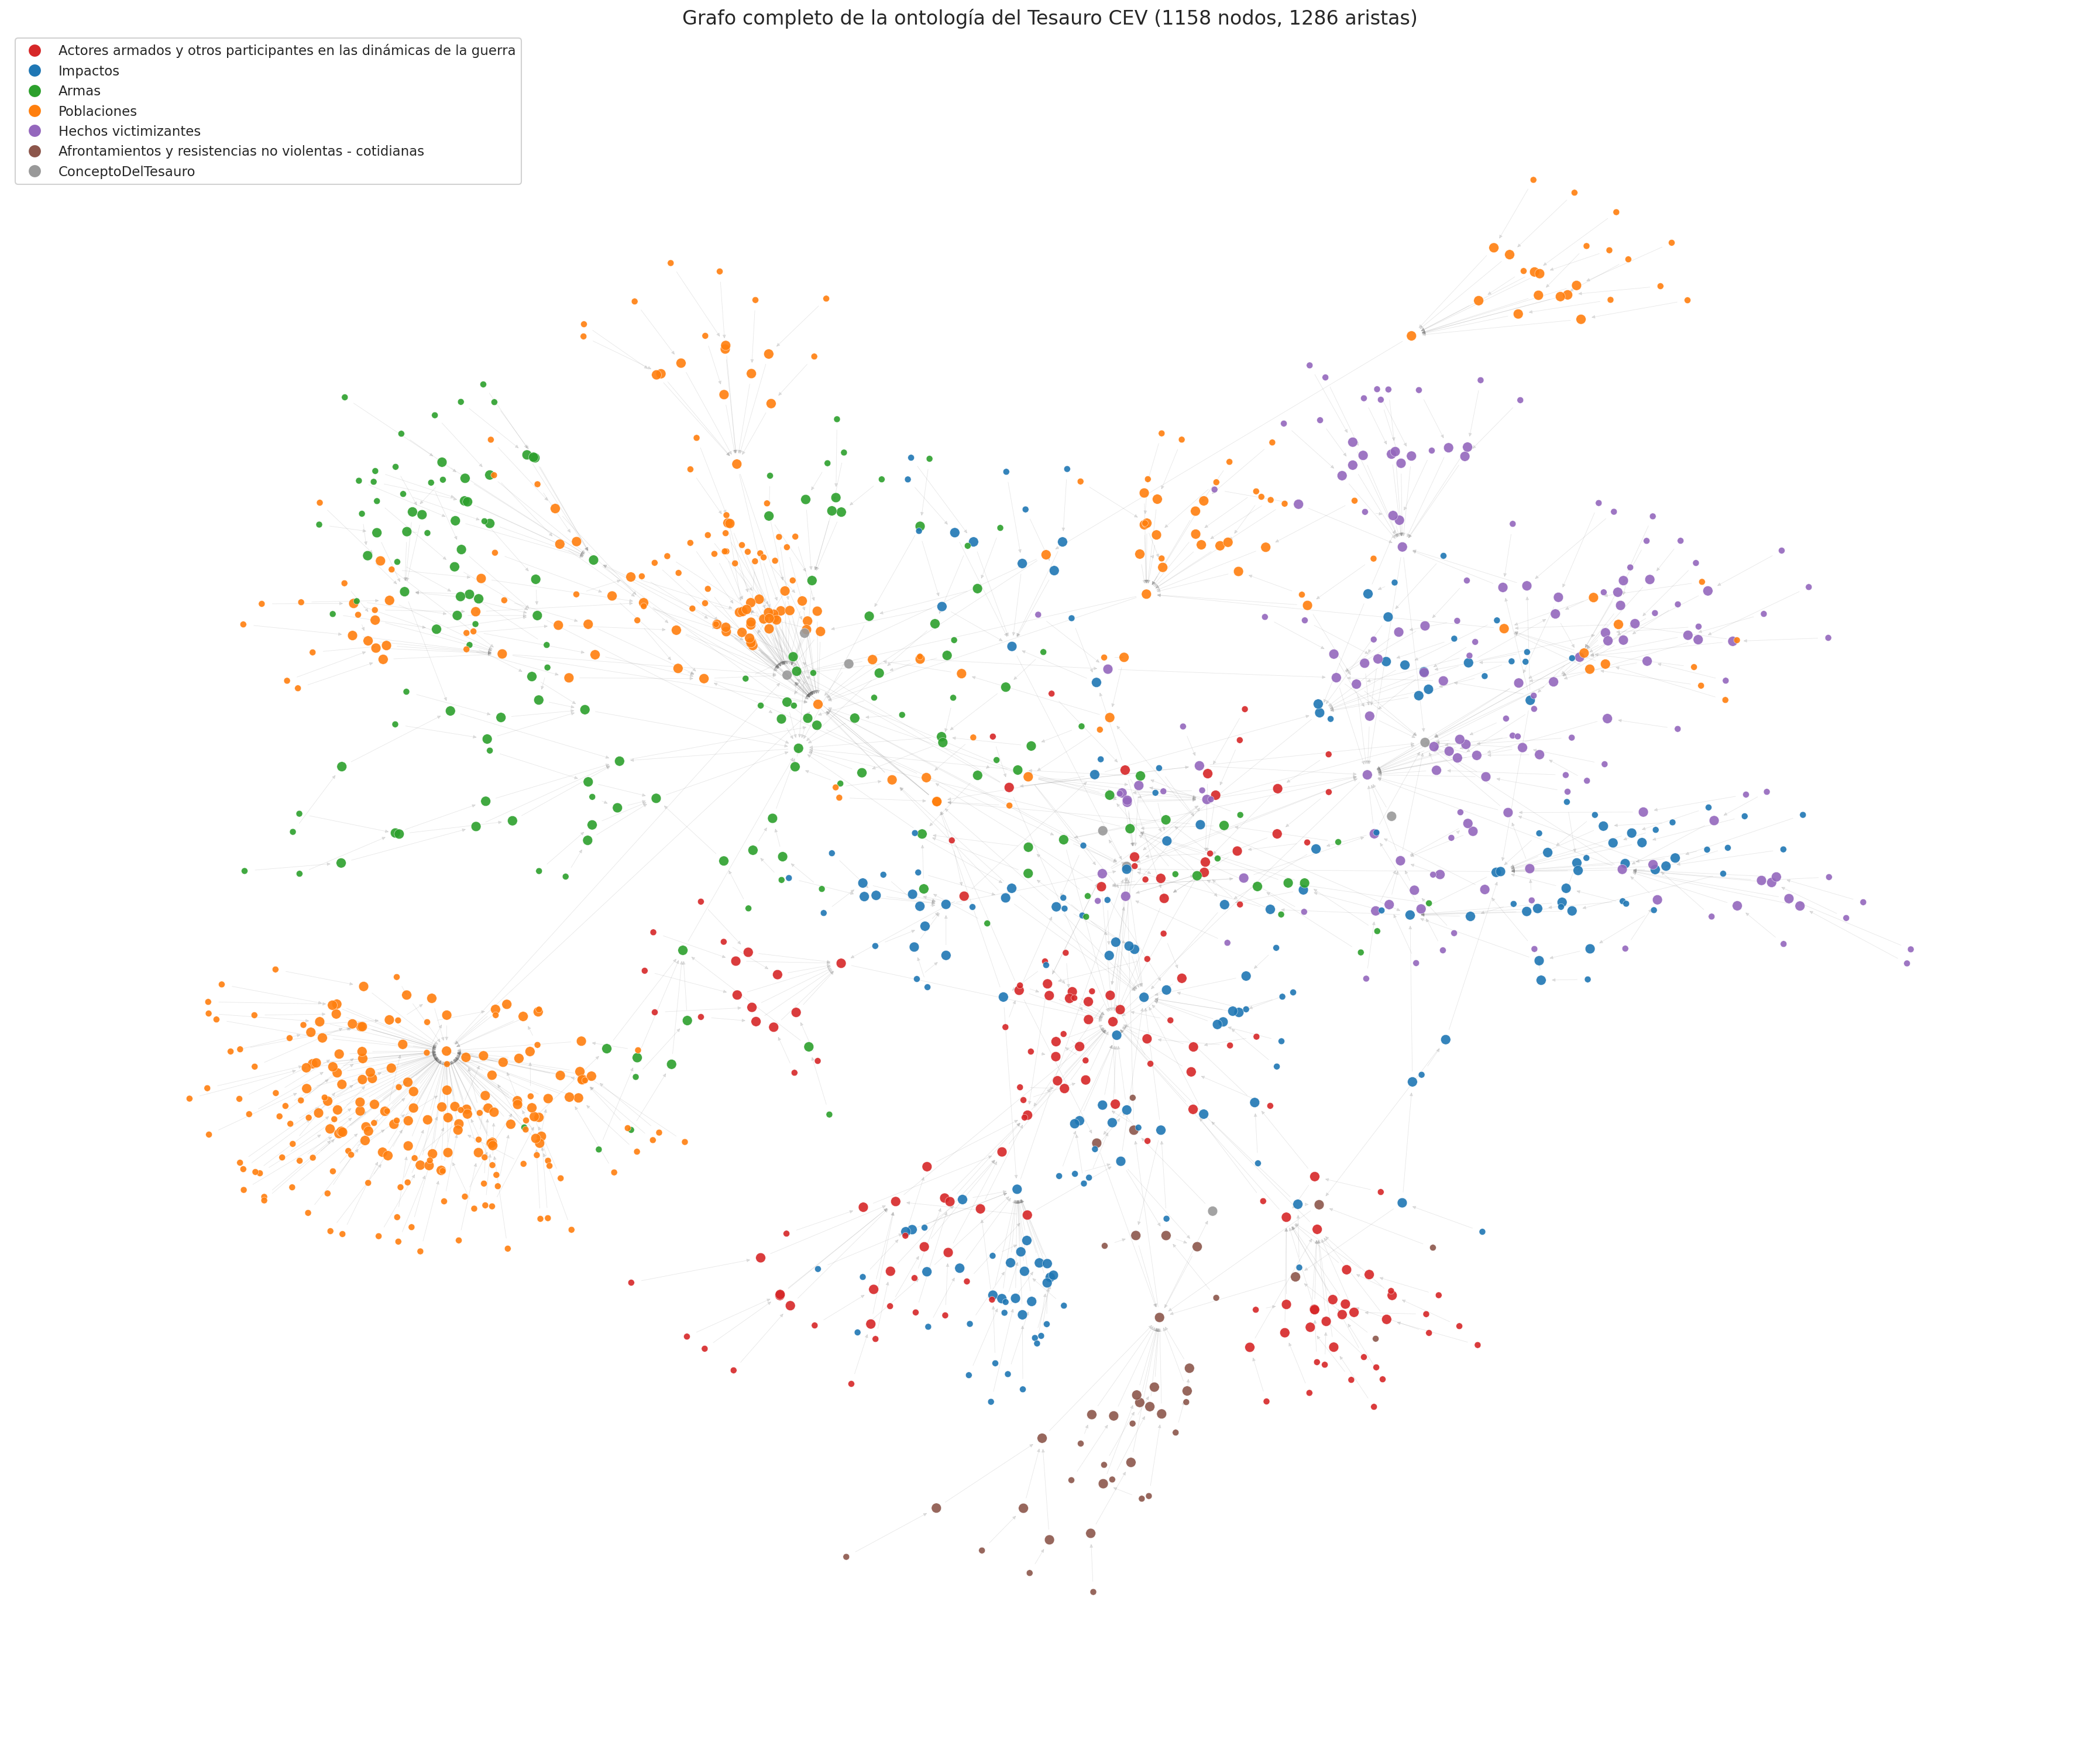

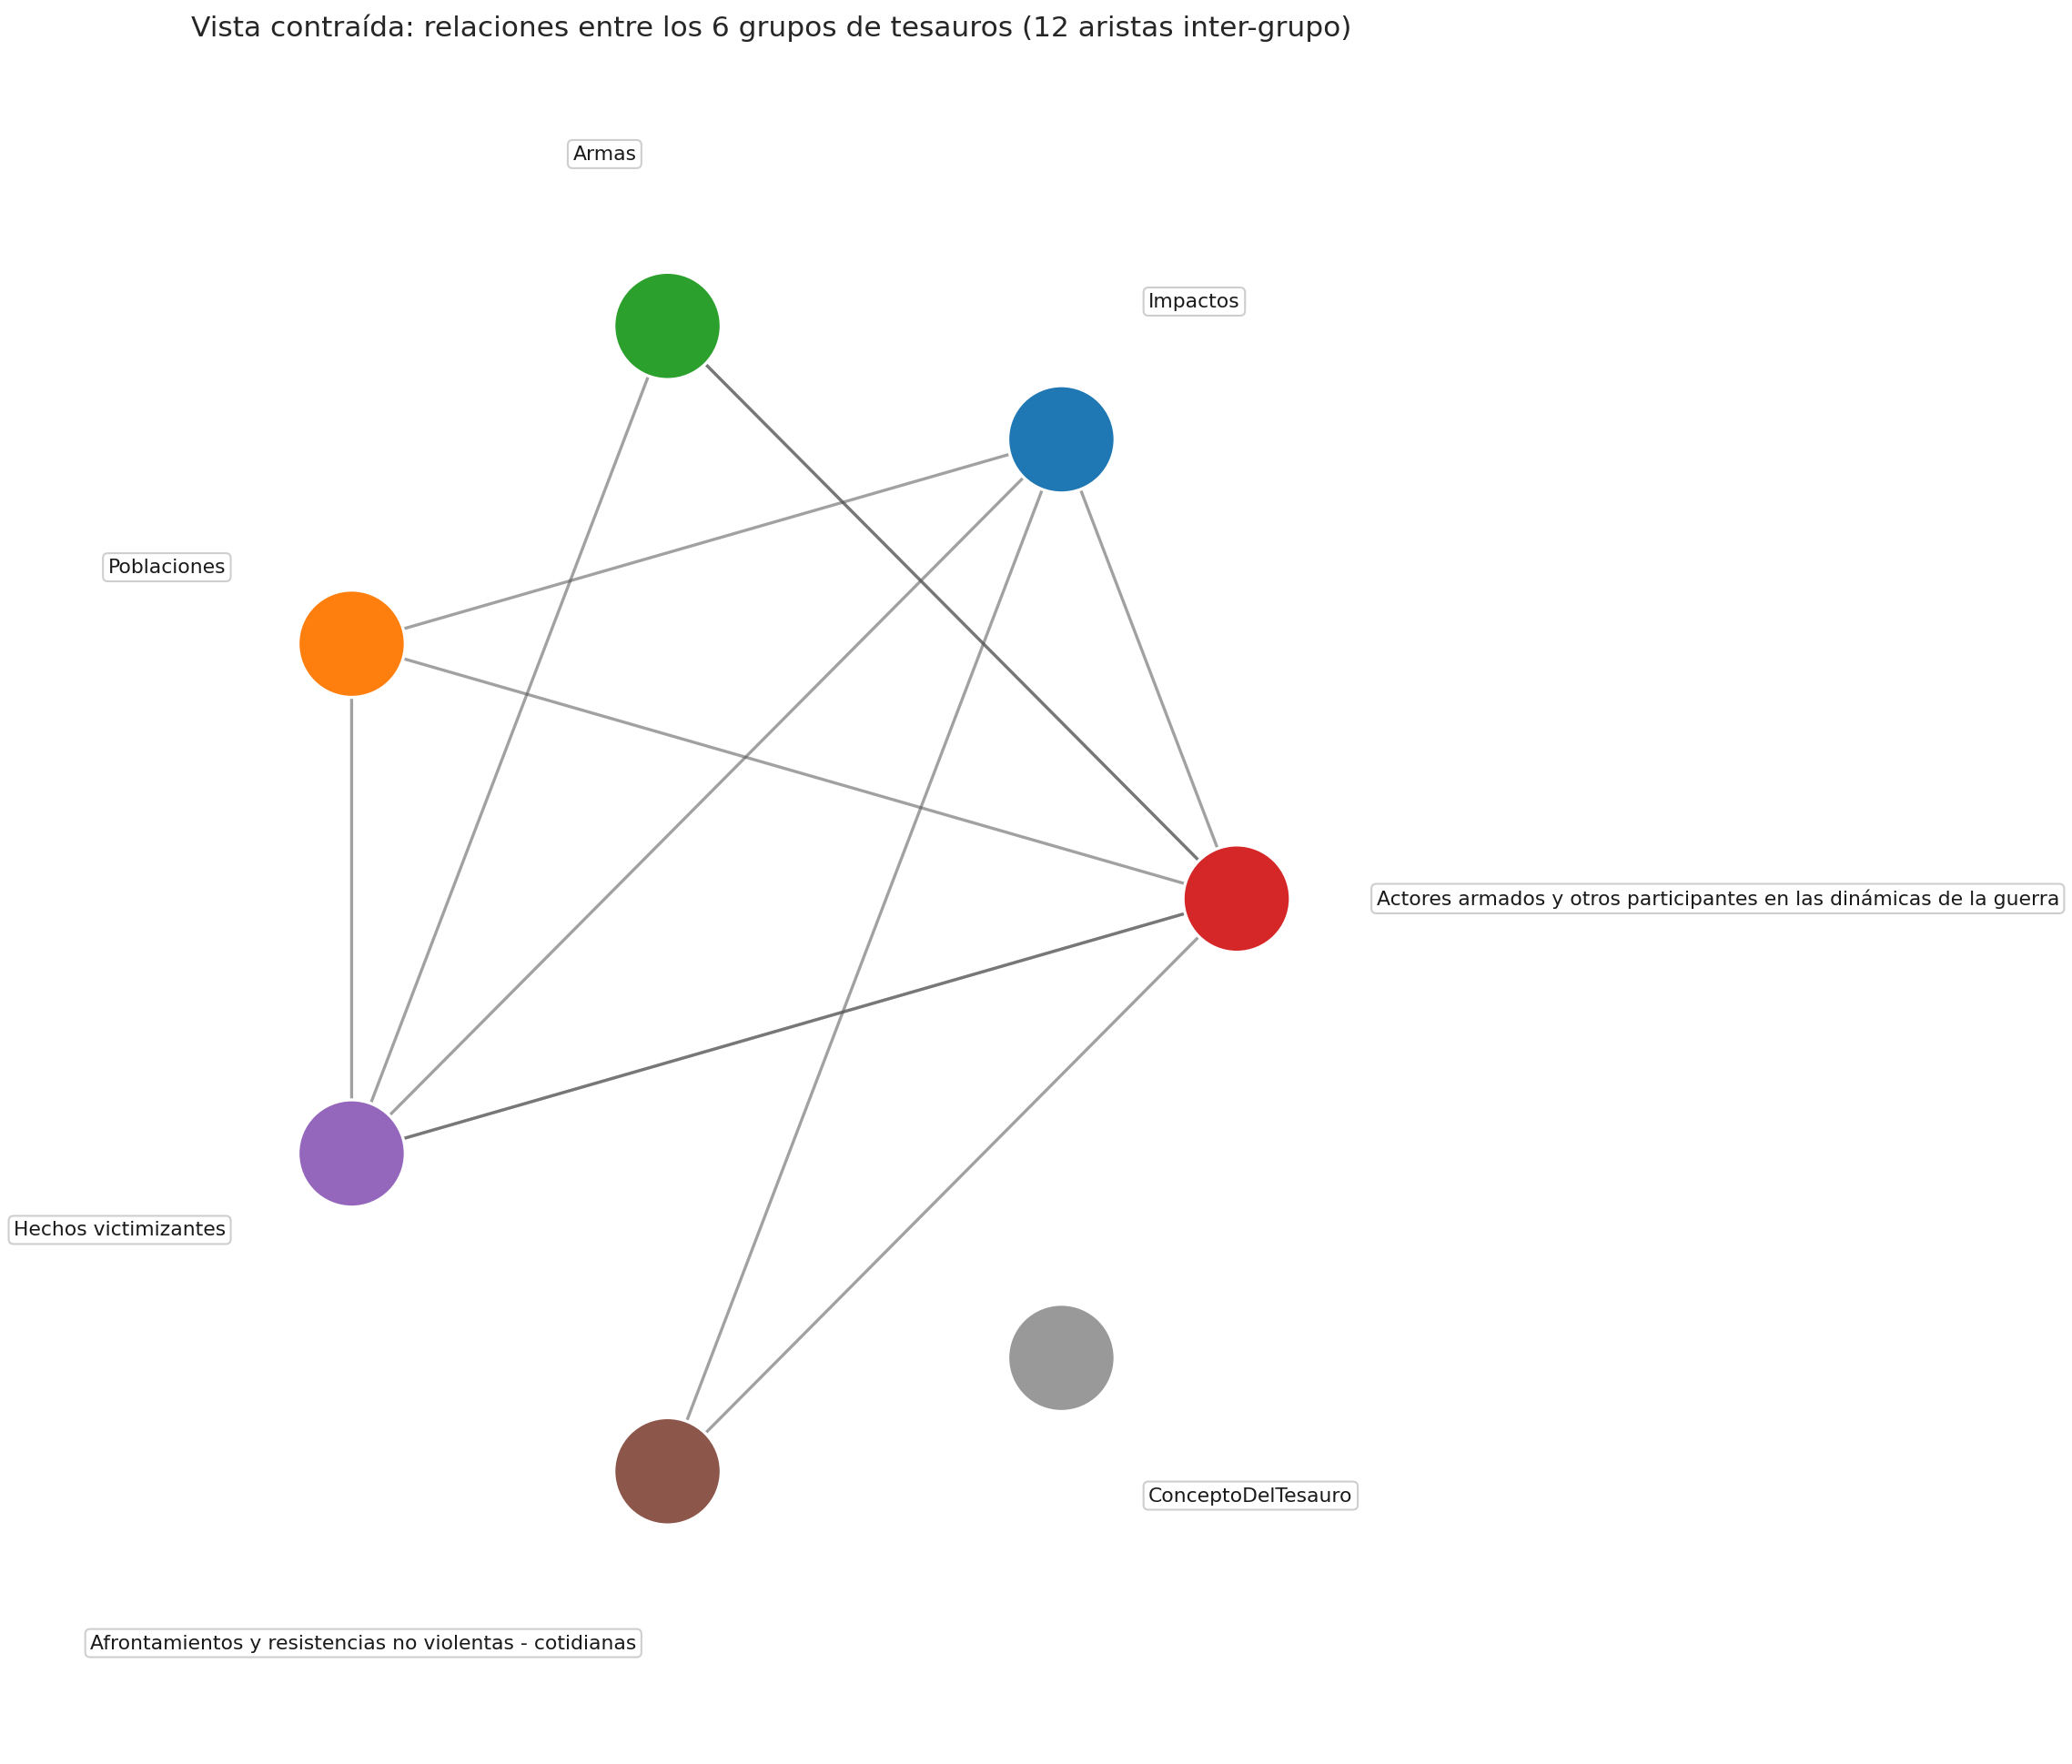

Grafo completo guardado en /home/carlos/Git/PLN/TALLER-2/imagenes/grafo_ontologia_completo.png
Vista contraida guardada en /home/carlos/Git/PLN/TALLER-2/imagenes/grafo_ontologia_grupos.png


In [32]:
# Imports y compatibilidad: mismo patron que sec03 (en el notebook las
# constantes y el nucleo POO ya existen; en modo script se importan y
# definen localmente).
import sys
from pathlib import Path

import matplotlib

try:
    get_ipython()
except NameError:
    matplotlib.use("Agg")

try:
    _DIR_CELDAS = Path(__file__).resolve().parent  # modo script
except NameError:
    _DIR_CELDAS = Path.cwd()  # modo notebook: el kernel corre en notebooks/

_DIR_MODULO = (
    _DIR_CELDAS
    if (_DIR_CELDAS / "sec00_clases.py").exists()
    else _DIR_CELDAS.parent / "notebook_cells"
)
sys.path.insert(0, str(_DIR_MODULO))

if "sc" not in globals():
    import sec00_clases as sc

if "FIGURAS" not in globals():
    RUTA_BASE = _DIR_CELDAS.parent
    RUTA_IMAGENES = RUTA_BASE / "imagenes"
    RUTA_ONTOLOGIA = RUTA_BASE / "ontologia" / "tesauro_cev.owl"
    FIGURAS = {
        "grafo_completo": RUTA_IMAGENES / "grafo_ontologia_completo.png",
        "grafo_grupos": RUTA_IMAGENES / "grafo_ontologia_grupos.png",
    }
    COLORES_GRUPO = {
        "Actores armados y otros participantes en las dinámicas de la guerra": "#d62728",
        "Impactos": "#1f77b4",
        "Armas": "#2ca02c",
        "Poblaciones": "#ff7f0e",
        "Hechos victimizantes": "#9467bd",
        "Afrontamientos y resistencias no violentas - cotidianas": "#8c564b",
    }

# Se reutiliza la instancia unica del Singleton: en el notebook la seccion 3
# ya la cargo; en ejecucion standalone (sec03b sin sec03) se carga ahora.
servicio = sc.ServicioOntologia.obtener(RUTA_ONTOLOGIA)
if servicio.onto is None:
    servicio.cargar()

# Facade de visualizacion: grafo completo coloreado por grupo y vista
# contraida entre los 6 grupos (colores inyectados desde sec00_setup).
grafo_ontologia = sc.GrafoOntologia(servicio, COLORES_GRUPO)

ruta_completo = grafo_ontologia.guardar_figura_completa(
    FIGURAS["grafo_completo"], dpi=200, mostrar=True
)
ruta_grupos = grafo_ontologia.guardar_figura_grupos(
    FIGURAS["grafo_grupos"], dpi=200, mostrar=True
)
print(f"Grafo completo guardado en {ruta_completo}")
print(f"Vista contraida guardada en {ruta_grupos}")

## Sec03b.2 Validacion numerica del grafo

Se contrastan los conteos del grafo (nodos por tipo y aristas por tipo)
contra las metricas estructurales del servicio y los valores esperados de
la extension aprobada (6 grupos): **623 clases, 534 individuos**, 610
aristas `esParteDe` (una por edge de la jerarquia), 50 `relacionadoCon`
(45 heuristicas + 5 raiz) y **13 `perpetradoPor`** (12 pares hecho-actor de
la heuristica + 1 axioma raiz del modelo semantico: Hechos victimizantes
subClassOf (perpetradoPor some Actores armados), que se agrega a la arista
ya existente entre esas dos raices). Nota: cada arista lleva su `tipo` como
CONJUNTO (`grafo[origen][destino]['tipo']`); el conteo suma los tipos de
cada set.

Las nuevas propiedades de dominio del modelo semantico (afectaA,
generaImpacto, experimentaImpacto, desarrollaAfrontamiento, respondeA,
empleaArma) NO aparecen como aristas de `grafo()`: el nucleo solo
materializa esParteDe/relacionadoCon/perpetradoPor. Esas relaciones viven
como restricciones `some` en las 6 raices y se validan en Sec03b.4 (modelo
semantico con owlready2); en la vista contraida solo se aprecian
indirectamente a traves de las aristas `relacionadoCon` agregadas.

In [33]:
from collections import Counter


def contar_aristas_por_tipo(grafo) -> Counter:
    """Cuenta las aristas por tipo sumando el set 'tipo' de cada arista.

    Una misma arista puede representar varios tipos a la vez (por ejemplo
    subClassOf + esParteDe unen los mismos pares padre-hijo); el atributo
    'tipo' es un conjunto y cada elemento se cuenta por separado.

    Args:
        grafo: nx.DiGraph con aristas anotadas con 'tipo' (set).

    Returns:
        Counter tipo de arista -> numero de aristas que lo contienen.
    """
    conteo = Counter()
    for _, _, atributos in grafo.edges(data=True):
        conteo.update(atributos.get("tipo", set()))
    return conteo


grafo_completo = grafo_ontologia.grafo_completo()

nodos_clase = sum(1 for _, a in grafo_completo.nodes(data=True) if a.get("tipo") == "clase")
nodos_individuo = sum(
    1 for _, a in grafo_completo.nodes(data=True) if a.get("tipo") == "individuo"
)
# Un nodo tecnico sin tipo: owl:Thing, superclase raiz de ConceptoDelTesauro
# (creado implicitamente por la arista rdfs:subClassOf).
nodos_tecnicos = grafo_completo.number_of_nodes() - nodos_clase - nodos_individuo
aristas_por_tipo = contar_aristas_por_tipo(grafo_completo)

metricas = servicio.metricas()
print("=== Conteos del grafo vs metricas del servicio ===")
print(f"- Nodos clase: {nodos_clase} (metricas: {metricas['clases']})")
print(f"- Nodos individuo: {nodos_individuo} (metricas: {metricas['individuos']})")
print(f"- Nodos tecnicos (owl:Thing): {nodos_tecnicos}")
print(f"- Aristas totales: {grafo_completo.number_of_edges()}")
for tipo in ("subclassof", "esParteDe", "relacionadoCon", "perpetradoPor", "instancia"):
    print(f"- Aristas {tipo}: {aristas_por_tipo[tipo]}")

esperado_esparte = 610  # una por edge de la jerarquia (616 nodos - 6 raices)
esperado_perpetrador = 13  # 12 pares hecho-actor + 1 axioma raiz del modelo semantico
cumple = (
    nodos_clase == metricas["clases"] == 623
    and nodos_individuo == metricas["individuos"] == 534
    and aristas_por_tipo["subclassof"] == 623
    and aristas_por_tipo["esParteDe"] >= esperado_esparte
    and aristas_por_tipo["relacionadoCon"] == 50
    and aristas_por_tipo["perpetradoPor"] == esperado_perpetrador
    and aristas_por_tipo["instancia"] == 534
)
print("Validacion visual: OK" if cumple else "Validacion visual: REVISAR (conteos no esperados)")

=== Conteos del grafo vs metricas del servicio ===
- Nodos clase: 623 (metricas: 623)
- Nodos individuo: 534 (metricas: 534)
- Nodos tecnicos (owl:Thing): 1
- Aristas totales: 1286
- Aristas subclassof: 623
- Aristas esParteDe: 610
- Aristas relacionadoCon: 50
- Aristas perpetradoPor: 13
- Aristas instancia: 534
Validacion visual: OK


## Sec03b.3 Analisis de las figuras

**Grafo completo (1.158 nodos, 1.219 aristas).** La imagen muestra el
"ovillo" esperado en un tesauro denso: 623 clases (610 conceptos con path
del tesauro + 6 raices + 6 clases definidas + `ConceptoDelTesauro`) y 534
individuos hoja distribuidos por los 6 grupos. Los individuos (puntos
pequenos) son los hubs mas externos y numerosos en Armas y Poblaciones, los
grupos con mayor profundidad y mayor cantidad de terminos hoja (municiones,
armas por tipo, pueblos etnicos, pueblos indigenas); las jerarquias
profundas del grupo Armas (hasta 6 niveles) aparecen como trayectorias
largas de nodos grandes encadenados. La superclase `ConceptoDelTesauro`
(gris) es el punto central del que cuelgan las 6 raices. A esa escala las
etiquetas no son legibles (a proposito): la figura valida estructura,
densidad y color por grupo, no texto.

**Vista contraida (7 nodos, 12 aristas inter-grupo).** Los pares visibles
confirman la coherencia del modelo conceptual CEV con la extension:
- **Hechos victimizantes -> Actores armados**: unica arista con
  `perpetradoPor` (+ `relacionadoCon`), el vinculo hecho-actor que define
  la propiedad; la inversa Actores -> Hechos solo lleva `relacionadoCon`
  (la simetria de la TR se declara en la propiedad, no en una segunda
  restriccion). En esta arista confluyen el par hecho-actor heurístico y el
  axioma raiz del modelo semantico, por eso la validacion espera 13 aristas
  `perpetradoPor` (12 + 1).
- **Armas -> Actores armados** y **Armas -> Hechos victimizantes**: los
  actores emplean armas y las armas son instrumentos de los hechos (raices
  fijas del criterio TR).
- **Impactos -> Hechos victimizantes** e **Impactos -> Poblaciones**: los
  hechos generan impactos que recaen sobre las poblaciones.
- **Afrontamientos y resistencias no violentas - cotidianas** (grupo nuevo
  de la extension) recibe aristas de **Actores armados** e **Impactos**
  (afinidad TR por co-ocurrencia terminologica), cerrando el ciclo del
  conflicto: el actor genera hechos que impactan a la poblacion y la
  poblacion desarrolla afrontamientos.
- **Actores armados -> Impactos / Poblaciones** y **Poblaciones ->
  Hechos victimizantes**: afinidades heuristicas adicionales (por ejemplo
  la terminologia de revictimizacion o de afectaciones a la poblacion civil
  co-ocurre entre grupos).

**Que valida visualmente:** (1) las 6 raices existen y cada grupo conserva
su color en ambas vistas; (2) la jerarquia esta completa (610 edges
esParteDe = nodos no raiz) con profundidades marcadas en Armas; (3) los
individuos hoja materializan los terminos del JSON (534); (4) las 3
familias de object properties conectan grupos distintos con sentido en el
dominio CEV, y el grupo nuevo de Afrontamientos queda integrado. La
validacion numerica de Sec03b.2 confirma estos conteos contra las metricas
del servicio y los valores esperados de la extension.

## Sec03b.4 Modelo semantico: axiomas de dominio y clases definidas

La extension agrego un modelo semantico sobre la jerarquia: **7 axiomas de
dominio** entre las 6 raices (ciclo del conflicto: hecho -> actor ->
poblacion -> impacto -> afrontamiento, mas las relaciones de dominio
desarrollaAfrontamiento, respondeA y empleaArma) y **6 clases definidas**
por `equivalentClass` (`Base AND (propiedad SOME Destino)`) que el
razonador puede clasificar automaticamente. Como las propiedades nuevas no
se materializan como aristas del grafo (ver Sec03b.2), esta celda valida el
modelo leyendo directamente los axiomas con owlready2: las restricciones
`some` en las 6 raices y las equivalencias de las clases definidas.

In [34]:
"""Validacion del modelo semantico: axiomas de dominio y clases definidas."""

print("=== Modelo semantico: axiomas de dominio entre raices (restricciones some) ===")
restricciones_raiz = 0
for grupo_origen, propiedad, grupo_destino in sc.RELACIONES_ENTRE_GRUPOS:
    clase = servicio.onto[sc.SLUG_RAIZ[grupo_origen]]
    axiomas = [
        a for a in clase.is_a
        if isinstance(a, sc.Restriction)
        and getattr(a.property, "name", None) == propiedad
        and getattr(a.value, "name", None) == sc.SLUG_RAIZ[grupo_destino]
    ]
    restricciones_raiz += len(axiomas)
    estado = "OK" if axiomas else "FALTA"
    print(
        f"- {sc.SLUG_RAIZ[grupo_origen]:<46} -{propiedad:<20}-> "
        f"{sc.SLUG_RAIZ[grupo_destino]}: {estado}"
    )
print(
    f"Restricciones de dominio verificadas: {restricciones_raiz} "
    f"de {len(sc.RELACIONES_ENTRE_GRUPOS)} axiomas esperados"
)

print()
print("=== Clases definidas (equivalentClass: Base AND (propiedad SOME Destino)) ===")
for nombre, clase_base, propiedad, clase_destino in sc.CLASES_DEFINIDAS:
    clase = servicio.onto[nombre]
    equivalencias = list(clase.equivalent_to)
    formula = (getattr(clase, "comment", [""]) or [""])[0]
    estado = "OK" if equivalencias else "FALTA"
    print(f"- {nombre:<32} {estado} | {formula}")
print(f"Clases definidas verificadas: {len(sc.CLASES_DEFINIDAS)}")

=== Modelo semantico: axiomas de dominio entre raices (restricciones some) ===
- Hechos_victimizantes                           -perpetradoPor       -> Actores_armados: OK
- Hechos_victimizantes                           -afectaA             -> Poblaciones: OK
- Hechos_victimizantes                           -generaImpacto       -> Impactos: OK
- Poblaciones                                    -experimentaImpacto  -> Impactos: OK
- Poblaciones                                    -desarrollaAfrontamiento-> Afrontamientos_resistencias_no_violentas: OK
- Afrontamientos_resistencias_no_violentas       -respondeA           -> Hechos_victimizantes: OK
- Actores_armados                                -empleaArma          -> Armas: OK
Restricciones de dominio verificadas: 7 de 7 axiomas esperados

=== Clases definidas (equivalentClass: Base AND (propiedad SOME Destino)) ===
- HechoPerpetradoPorActor          OK | Clase definida: Hechos victimizantes AND (perpetradoPor SOME Actores armados)
- Pob

# Seccion 4 - Relaciones semanticas WordNet sobre los conceptos de la ontologia (Fase 2b)

**Fase 2b del TALLER-2.** Aplicacion masiva del extractor de 9 relaciones
semanticas sobre los **610 conceptos** de la ontologia `tesauro_cev.owl`
(6 grupos seleccionados en la Fase 1a, extension aprobada: se incorporo
"Afrontamientos y resistencias no violentas - cotidianas" con 23 terminos).
Esta seccion usa el **nucleo POO de
la seccion 00** (`sc.MotorRelacionesWordNet`), que orquesta la cadena de
normalizadores (`sc.CadenaNormalizadores`), la fabrica de extractores
(`sc.FabricaExtractores` con sus 9 implementaciones Strategy) y NLTK:
la funcion `motor.extraer_relaciones(termino, profundidad=1)` recibe como
entrada los conceptos de la ontologia. Si `ontologia/tesauro_cev.owl`
existe (lo genera la seccion 03), los conceptos se leen de ahi con su path
jerarquico y su grupo (`sc.ServicioOntologia`); en caso contrario (seccion
03 aun no ejecutada) se usa como respaldo el JSON
`data/grupos_seleccionados.json` via `sc.TesauroRepositorio`, que contiene
exactamente los mismos terminos.

Las 9 relaciones implementadas (una clase extractora por tipo, registrada
en la fabrica de sec00):

1. **Sinonimia**: lemmas espanoles del mismo synset.
2. **Antonimia**: lemmas antonimos (via enlaces del PWN, retraducidos a espanol).
3. **Hiponimia**: synsets subordinados (recursion configurable con profundidad).
4. **Hiperonimia**: synsets superordinados (misma recursion por simetria).
5. **Meronimia**: parte/sustancia/miembro de (part + substance + member meronyms).
6. **Holonimia**: contiene a (part + substance + member holonyms).
7. **Troponimia**: verbos de manera (hiponimos de un synset verbal).
8. **Coordinados**: hermanos (mismos hiperonimos directos, excluyendo el propio synset).
9. **Derivacion morfologica**: lemmas derivados (derivationally_related_forms).

Nota sobre omw-1.4 en espanol: solo 38.512 de 117.659 synsets del PWN tienen
traduccion al espanol (~33%). Los enlaces de antonimia y derivacion viven en
los lemmas ingleses del PWN; aqui se resuelven sobre esos lemmas y se
retraducen al espanol cuando la traduccion existe, reportando el nombre PWN
con la marca "(en)" en caso contrario. El termino de entrada NUNCA se
traduce al ingles: si no existe en espanol, se devuelve `encontrado: False`.

Productos de esta seccion:

- `data/wordnet_relaciones.csv`: una fila por concepto con los conteos de
  cada relacion y ejemplos en JSON compacto (trazabilidad completa).
- 5 figuras en `imagenes/`: cobertura por grupo, heatmap grupo x tipo de
  relacion, top-15 conceptos, grafo de relaciones compartidas entre
  conceptos de la ontologia, y profundidad vs cobertura.
- `data/grafo_relaciones_edges.csv`: aristas del grafo (concepto-concepto).
- Celda de **verificacion de las 9 relaciones** (rubrica criterio 3) con
  conceptos reales de la ontologia (incluye el grupo nuevo de
  Afrontamientos) y assertions.

In [35]:
"""Imports, verificacion de los corpora NLTK, bloque standalone y estilo."""
import os
import sys
import time
from collections import defaultdict
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

# Rutas relativas al notebook (las celdas viven en notebook_cells/).
try:
    RUTA_BASE = Path(__file__).resolve().parent.parent  # modo script
except NameError:
    RUTA_BASE = Path(os.getcwd()).parent  # modo notebook (notebooks/)

# Nucleo POO de sec00: en el notebook ya se ejecuto como celdas; en modo
# script se importa desde notebook_cells/ para que la seccion sea standalone.
sys.path.insert(0, str(RUTA_BASE / "notebook_cells"))
import sec00_clases as sc

# Constantes globales del proyecto (definidas en sec00_setup, una sola vez).
# En el notebook ya viven en el namespace; el import solo se usa en modo
# script standalone (cuando el archivo sec00_setup.py existe en notebook_cells/).
if "RUTA_ONTOLOGIA" not in globals():
    from sec00_setup import (
        COLORES_GRUPO,
        FIGURAS,
        RUTA_CSV_GRAFO,
        RUTA_CSV_WORDNET,
        RUTA_EXCEL,
        RUTA_IMAGENES,
        RUTA_JSON_GRUPOS,
        RUTA_ONTOLOGIA,
        TIPOS_RELACION,
    )

# Verificacion de los corpora NLTK (wordnet + omw-1.4 en espanol). Los datos
# ya estan en disco (instalados en la Fase 0); este bloque NO descarga nada.
try:
    from nltk.corpus import wordnet as wn

    wn.synsets("desplazamiento", lang="spa")
except LookupError as error:
    print("ERROR: faltan los corpora NLTK (wordnet u omw-1.4).")
    print("Ejecutar una sola vez, con internet:")
    print('  import nltk')
    print('  nltk.download("wordnet")')
    print('  nltk.download("omw-1.4")')
    raise SystemExit(1) from error

TOTAL_SYNSETS_SPA = sum(1 for _ in wn.all_synsets(lang="spa"))
TOTAL_SYNSETS_PWN = sum(1 for _ in wn.all_synsets())

# Estilo de figuras: espanol, legibles, 150 dpi.
plt.rcParams.update({
    "figure.dpi": 100,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

print(
    f"Corpora OK: {TOTAL_SYNSETS_SPA:,} synsets en espanol "
    f"de {TOTAL_SYNSETS_PWN:,} del PWN "
    f"({TOTAL_SYNSETS_SPA / TOTAL_SYNSETS_PWN:.1%})."
)

Corpora OK: 38,512 synsets en espanol de 117,659 del PWN (32.7%).


## Carga de los conceptos de la ontologia

Requisito del taller: "la funcion debe recibir como entrada los conceptos de
la ontologia". Se intenta leer `ontologia/tesauro_cev.owl` (generado por la
seccion 03) con el facade `sc.ServicioOntologia`: se recorren las clases
OWL y se recupera el path jerarquico original desde la anotacion
`rdfs:comment` (grupo = anotacion `cev:grupo`). Si el archivo OWL no existe
aun, se usa como respaldo el JSON de la Fase 1a via `sc.TesauroRepositorio`,
que contiene exactamente los mismos terminos con sus paths y grupos.

Cada concepto se representa como una fila de DataFrame con:
`grupo` (trazabilidad), `termino` (path completo "A - B - C") y
`concepto` (segmento final, que es lo que se consulta en WordNet). La
profundidad del path se deriva del propio termino (niveles separados por
" - ") cuando el analisis la necesita.

In [36]:
"""Lectura de conceptos desde la ontologia OWL (preferente) o JSON (respaldo)."""


def _conceptos_desde_json() -> pd.DataFrame:
    """Construye el DataFrame de conceptos desde el JSON de grupos (respaldo).

    Usa el repository de sec00 para no conocer el formato del JSON: cada
    path "A - B - C" de cada grupo genera una fila con su segmento final.

    Returns:
        DataFrame con columnas `grupo`, `termino` y `concepto`.
    """
    repositorio = sc.TesauroRepositorio(RUTA_EXCEL, RUTA_JSON_GRUPOS)
    filas = []
    for grupo, paths in repositorio.terminos_por_grupo().items():
        for path in paths:
            filas.append({
                "grupo": grupo,
                "termino": path,
                "concepto": path.split(" - ")[-1].strip(),
            })
    return pd.DataFrame(filas)


servicio_ontologia = sc.ServicioOntologia.obtener(RUTA_ONTOLOGIA)
if RUTA_ONTOLOGIA.exists():
    print(f"Leyendo conceptos desde la ontologia: {RUTA_ONTOLOGIA}")
    servicio_ontologia.cargar()
    df_conceptos = servicio_ontologia.conceptos()
    fuente_conceptos = "ontologia_owl"
else:
    print(
        f"La ontologia {RUTA_ONTOLOGIA} aun no existe (la genera la seccion 03); "
        "se usan los conceptos del JSON de la Fase 1a."
    )
    df_conceptos = _conceptos_desde_json()
    fuente_conceptos = "json_respaldo"

TOTAL_CONCEPTOS = len(df_conceptos)
GRUPOS = list(dict.fromkeys(df_conceptos["grupo"]))

print(
    f"Fuente: {fuente_conceptos} | {TOTAL_CONCEPTOS} conceptos en "
    f"{len(GRUPOS)} grupos."
)
print("Ejemplos de conceptos con su path y nivel:")
for fila in df_conceptos.head(5).itertuples():
    niveles = len(fila.termino.split(" - "))
    print(
        f'  n={niveles} [{fila.grupo[:30]:<30}] {fila.termino}'
        f"  ->  concepto: {fila.concepto}"
    )

Leyendo conceptos desde la ontologia: /home/carlos/Git/PLN/TALLER-2/ontologia/tesauro_cev.owl
Fuente: ontologia_owl | 610 conceptos en 6 grupos.
Ejemplos de conceptos con su path y nivel:
  n=2 [Actores armados y otros partic] Actores armados y otros participantes en las dinámicas de la guerra - Accionar de los actores armados  ->  concepto: Accionar de los actores armados
  n=3 [Actores armados y otros partic] Actores armados y otros participantes en las dinámicas de la guerra - Accionar de los actores armados - Acciones bélicas  ->  concepto: Acciones bélicas
  n=3 [Hechos victimizantes          ] Hechos victimizantes - Reclutamiento, uso y utilización de niños, niñas y adolescentes - Utilización en acciones bélicas  ->  concepto: Utilización en acciones bélicas
  n=3 [Actores armados y otros partic] Actores armados y otros participantes en las dinámicas de la guerra - Accionar de los actores armados - Participación directa en el marco del conflicto armado  ->  concepto: Participació

## Aplicacion masiva del extractor (Motor POO de sec00)

Se ejecuta `motor.analizar_conceptos(df_conceptos)` sobre los conceptos
cargados (610 en el OWL actual, 6 grupos). El Motor normaliza cada path
(cadena de
normalizadores), busca los synsets en espanol probando las variantes en
orden y aplica los 9 extractores registrados en la fabrica; los resultados
se cachean por termino (evita recomputar conceptos repetidos entre grupos).
Se guardan en `data/wordnet_relaciones.csv` con una fila por concepto:
grupo, path completo, concepto, si fue encontrado, conteos de las 9
relaciones y ejemplos en JSON compacto. La columna `variante_usada`
registra que variante de busqueda produjo los synsets (trazabilidad de las
normalizaciones).

In [37]:
"""Ejecucion masiva con el Motor y guardado del CSV de relaciones."""

motor = sc.MotorRelacionesWordNet()

inicio = time.time()
df_relaciones = motor.analizar_conceptos(df_conceptos)
df_relaciones = df_relaciones.rename(columns={
    "termino": "termino_path",
    "ejemplos": "relaciones_ejemplo",
    **{t: f"n_{t}" for t in TIPOS_RELACION},
})
# Trazabilidad de los synsets consultados: se reconsultan contra el cache del
# Motor (gratis, los resultados ya estan memorizados por termino).
df_relaciones["synsets_referencia"] = [
    "; ".join(motor.extraer_relaciones(termino).synsets_consulta)
    for termino in df_relaciones["termino_path"]
]
columnas_rel = [f"n_{t}" for t in TIPOS_RELACION]
df_relaciones["total_relaciones"] = df_relaciones[columnas_rel].sum(axis=1)
orden_csv = [
    "grupo", "termino_path", "concepto", "encontrado", *columnas_rel,
    "relaciones_ejemplo", "variante_usada", "synsets_referencia",
]
df_relaciones.to_csv(RUTA_CSV_WORDNET, index=False, encoding="utf-8", columns=orden_csv)
duracion = time.time() - inicio

print(
    f"{len(df_relaciones)} conceptos procesados en {duracion:.1f} s "
    f"({df_relaciones['termino_path'].nunique()} terminos unicos consultados)."
)
print(f"CSV guardado: {RUTA_CSV_WORDNET.relative_to(RUTA_BASE)}")
print()

# Resumen por grupo: cobertura y relaciones totales.
print(f'{"Grupo":<55} {"n":>4} {"enc":>4} {"conRel":>6} {"%":>6}')
print("-" * 80)
filas_grupo = []
for grupo in GRUPOS:
    sub = df_relaciones[df_relaciones["grupo"] == grupo]
    encontrados = int(sub["encontrado"].sum())
    con_relaciones = int((sub[columnas_rel].sum(axis=1) > 0).sum())
    pct = con_relaciones / len(sub) if len(sub) else 0.0
    filas_grupo.append((grupo, len(sub), encontrados, con_relaciones, pct))
    print(f"{grupo:<55} {len(sub):>4} {encontrados:>4} {con_relaciones:>6} "
          f"{pct:>6.1%}")

total_con_rel = int((df_relaciones[columnas_rel].sum(axis=1) > 0).sum())
print("-" * 80)
print(f'{"TOTAL":<55} {len(df_relaciones):>4} '
      f'{int(df_relaciones["encontrado"].sum()):>4} {total_con_rel:>6} '
      f'{total_con_rel / len(df_relaciones):>6.1%}')

print()
print("Totales por tipo de relacion (todos los conceptos):")
for tipo in TIPOS_RELACION:
    total = int(df_relaciones[f"n_{tipo}"].sum())
    aportan = int((df_relaciones[f"n_{tipo}"] > 0).sum())
    print(f"  {tipo:<13} {total:>7} relaciones en {aportan:>4} conceptos")


def _clasificar_variante(variante: str, candidatos: list[str]) -> str:
    """Clasifica la variante usada segun su posicion en la cadena de busqueda.

    La cadena de candidatos del Motor tiene un orden fijo: forma base,
    variante morfologica (singular/plural), forma sin acentos, forma con
    guiones bajos y, para los compuestos, el ultimo y el primer token.

    Args:
        variante: Variante registrada en el resultado del Motor.
        candidatos: Variantes generadas por la cadena de normalizadores.

    Returns:
        Categoria de la variante: exacta, guiones_bajos, ultimo_token,
        primer_token o singular_plural_o_sin_acentos.
    """
    if not variante or not candidatos:
        return "sin_resultados"
    if variante == candidatos[0]:
        return "exacta"
    if variante == candidatos[0].replace(" ", "_"):
        return "guiones_bajos"
    tokens = candidatos[0].split()
    if len(tokens) > 1:
        if variante == tokens[-1]:
            return "ultimo_token"
        if variante == tokens[0]:
            return "primer_token"
    return "singular_plural_o_sin_acentos"


print()
print("Trazabilidad de la variante usada (conceptos encontrados):")
conteo_variantes = defaultdict(int)
for fila in df_conceptos.itertuples():
    resultado = motor.extraer_relaciones(fila.termino)
    if not resultado.encontrado:
        continue
    categoria = _clasificar_variante(
        resultado.variante_usada, motor.cadena.candidatos(fila.termino)
    )
    conteo_variantes[categoria] += 1
for categoria, cantidad in conteo_variantes.items():
    print(f"  {categoria:<30} {cantidad:>4} ({cantidad / TOTAL_CONCEPTOS:.1%})")

610 conceptos procesados en 0.2 s (610 terminos unicos consultados).
CSV guardado: data/wordnet_relaciones.csv

Grupo                                                      n  enc conRel      %
--------------------------------------------------------------------------------
Actores armados y otros participantes en las dinámicas de la guerra   81   56     56  69.1%
Hechos victimizantes                                      89   71     71  79.8%
Impactos                                                 107   79     79  73.8%
Poblaciones                                              214   36     36  16.8%
Armas                                                     96   49     49  51.0%
Afrontamientos y resistencias no violentas - cotidianas   23   17     17  73.9%
--------------------------------------------------------------------------------
TOTAL                                                    610  308    308  50.5%

Totales por tipo de relacion (todos los conceptos):
  sinonimia        26

## Clases POO del analisis (SOLID: calculos y figuras separados)

`AnalisisRelaciones` encapsula los calculos (cobertura, matriz grupo x
tipo, top de conceptos, grafo compartido y correlaciones de profundidad)
con cache de resultados; `AnalizadorRelaciones` dibuja y guarda las 5
figuras y el CSV de aristas, con un metodo `analizar_completo()` que las
ejecuta todas y consolida las metricas. El Motor se inyecta por
constructor (inversion de dependencias).

In [38]:
"""Clases POO del analisis: calculos (AnalisisRelaciones) y figuras (AnalizadorRelaciones)."""


class AnalisisRelaciones:
    """Calculos del analisis de relaciones WordNet (SOLID: solo computo).

    Encapsula los datos derivados del analisis masivo (cobertura por grupo,
    matriz grupo x tipo, top de conceptos, grafo compartido y correlacion de
    profundidad) y los cachea para que las figuras no recalculen nada.

    Attributes:
        df: DataFrame de relaciones (columnas n_<tipo> y total_relaciones).
        conceptos: DataFrame de conceptos de la ontologia (grupo/termino/concepto).
        tipos: Lista de los 9 tipos de relacion analizados.
    """

    def __init__(
        self, df_relaciones: pd.DataFrame, conceptos: pd.DataFrame, tipos: list[str]
    ) -> None:
        self.df = df_relaciones
        self.conceptos = conceptos
        self.tipos = list(tipos)
        self._cobertura: pd.DataFrame | None = None
        self._matriz: pd.DataFrame | None = None
        self._grafo: tuple[nx.Graph, pd.DataFrame] | None = None
        self._profundidad: tuple[pd.DataFrame, float, float] | None = None

    def columnas_rel(self) -> list[str]:
        """Nombres de las columnas de conteo por tipo."""
        return [f"n_{t}" for t in self.tipos]

    def cobertura(self) -> pd.DataFrame:
        """Conceptos con al menos 1 relacion por grupo (absolutos y %).

        Returns:
            DataFrame con columnas grupo, n, con_relaciones y pct (0-1).
        """
        if self._cobertura is None:
            col = self.columnas_rel()
            filas = []
            for grupo, sub in self.df.groupby("grupo"):
                con_rel = int((sub[col].sum(axis=1) > 0).sum())
                filas.append({
                    "grupo": grupo,
                    "n": len(sub),
                    "con_relaciones": con_rel,
                    "pct": con_rel / len(sub),
                })
            self._cobertura = pd.DataFrame(filas)
        return self._cobertura

    def matriz_grupo_tipo(self) -> pd.DataFrame:
        """Promedio de relaciones por concepto, matriz grupo x tipo.

        La normalizacion por tamano de grupo permite comparar grupos de
        distinto numero de conceptos (Poblaciones tiene 214 y Actores 81).

        Returns:
            DataFrame con grupos como filas y tipos como columnas.
        """
        if self._matriz is None:
            col = self.columnas_rel()
            matriz = pd.DataFrame(
                0.0, index=list(dict.fromkeys(self.df["grupo"])), columns=col
            )
            for grupo, sub in self.df.groupby("grupo"):
                matriz.loc[grupo] = sub[col].sum(axis=0) / len(sub)
            self._matriz = matriz
        return self._matriz

    def top_conceptos(self, n: int = 15) -> pd.DataFrame:
        """Top-n conceptos por numero total de relaciones (ascendente).

        Returns:
            DataFrame ordenado de menor a mayor para barras horizontales.
        """
        return (
            self.df.sort_values("total_relaciones", ascending=False)
            .head(n)
            .iloc[::-1]
            .reset_index(drop=True)
        )

    def grafo_compartido(
        self,
        motor_extractor,
        tipos_grafo: tuple[str, ...] = ("sinonimia", "hiponimia", "coordinados"),
        fanout_maximo: int = 30,
    ) -> tuple[nx.Graph, pd.DataFrame]:
        """Grafo de conceptos que comparten terminos relacionados.

        Los nodos son los conceptos con al menos una relacion; las aristas
        unen conceptos que comparten al menos un termino relacionado en los
        tipos indicados. Los terminos relacionados con fan-out superior a
        `fanout_maximo` (hubs genericos como "cosa") se excluyen de la
        construccion de aristas para no saturar la red con aristas triviales.

        Args:
            motor_extractor: Motor con los resultados cacheados por termino.
            tipos_grafo: Tipos de relacion que crean aristas.
            fanout_maximo: Maximo de conceptos que pueden compartir un termino.

        Returns:
            Tupla (grafo_figura, df_aristas): el grafo solo con aristas
            fuertes (>= 2 tipos compartidos) para la figura, y el DataFrame
            con TODAS las aristas (fidelidad completa para el CSV).
        """
        if self._grafo is not None:
            return self._grafo
        indices_con_rel = [
            i for i, fila in enumerate(self.conceptos.itertuples())
            if self.df.iloc[i][self.columnas_rel()].sum() > 0
        ]
        rel_por_termino: dict[str, dict[str, set[int]]] = {
            tipo: defaultdict(set) for tipo in tipos_grafo
        }
        for i in indices_con_rel:
            resultado = motor_extractor.extraer_relaciones(
                self.conceptos.iloc[i]["termino"]
            )
            for tipo in tipos_grafo:
                for nombre in resultado.relaciones.get(tipo, []):
                    rel_por_termino[tipo][nombre].add(i)
        aristas: dict[tuple[int, int], set[str]] = {}
        for tipo in tipos_grafo:
            for indices in rel_por_termino[tipo].values():
                if len(indices) < 2 or len(indices) > fanout_maximo:
                    continue
                for par in combinations(sorted(indices), 2):
                    aristas.setdefault(par, set()).add(tipo)
        filas_aristas = [
            {
                "concepto_a": self.conceptos.iloc[a]["concepto"],
                "grupo_a": self.conceptos.iloc[a]["grupo"],
                "concepto_b": self.conceptos.iloc[b]["concepto"],
                "grupo_b": self.conceptos.iloc[b]["grupo"],
                "tipos_compartidos": "; ".join(sorted(tipos)),
                "n_relaciones_compartidas": len(tipos),
            }
            for (a, b), tipos in aristas.items()
        ]
        grafo_figura = nx.Graph()
        for i in indices_con_rel:
            fila = self.conceptos.iloc[i]
            grafo_figura.add_node(
                i,
                concepto=fila["concepto"],
                grupo=fila["grupo"],
                total_rel=int(self.df.iloc[i]["total_relaciones"]),
            )
        for (a, b), tipos in aristas.items():
            if len(tipos) < 2:
                continue
            grafo_figura.add_edge(
                a, b, tipos="; ".join(sorted(tipos)), n_compartidas=len(tipos)
            )
        self._grafo = (grafo_figura, pd.DataFrame(filas_aristas))
        return self._grafo

    def profundidad(self) -> tuple[pd.DataFrame, float, float]:
        """Correlaciones entre profundidad del path y total de relaciones.

        Returns:
            Tupla (df_niveles, spearman, pearson) con los conceptos con al
            menos una relacion y su numero de niveles derivado del path.
        """
        if self._profundidad is None:
            df_niveles = self.df[
                ["concepto", "grupo", "termino_path", "total_relaciones"]
            ].copy()
            df_niveles["niveles"] = df_niveles["termino_path"].str.split(" - ").str.len()
            df_niveles = df_niveles[df_niveles["total_relaciones"] > 0]
            spearman = df_niveles["niveles"].corr(
                df_niveles["total_relaciones"], method="spearman"
            )
            pearson = df_niveles["niveles"].corr(
                df_niveles["total_relaciones"], method="pearson"
            )
            self._profundidad = (df_niveles, float(spearman), float(pearson))
        return self._profundidad

    def totales_por_tipo(self) -> pd.DataFrame:
        """Totales y conceptos que aportan, por tipo de relacion."""
        return pd.DataFrame([
            {
                "tipo": tipo,
                "total": int(self.df[f"n_{tipo}"].sum()),
                "conceptos": int((self.df[f"n_{tipo}"] > 0).sum()),
            }
            for tipo in self.tipos
        ])


class AnalizadorRelaciones:
    """Figuras del analisis WordNet: un metodo por figura + analizar_completo().

    SOLID: delega todos los calculos en `AnalisisRelaciones`; esta clase solo
    dibuja, guarda archivos (PNG y CSV de aristas) y reporta metricas. Cada
    figura se genera una sola vez (cache interno) para que
    `analizar_completo()` no duplique trabajo.

    Attributes:
        motor: Motor de relaciones (fuente de los resultados cacheados).
        analisis: AnalisisRelaciones con los datos del analisis masivo.
        ruta_imagenes: Directorio donde se guardan las figuras.
        colores_grupo: Dict grupo -> color hex para los nodos/barras.
        rutas_figuras: Dict nombre -> ruta PNG (constantes de sec00_setup).
        ruta_csv_grafo: Ruta del CSV de aristas del grafo compartido.
    """

    def __init__(
        self,
        motor_extractor,
        analisis: AnalisisRelaciones,
        ruta_imagenes: Path,
        colores_grupo: dict[str, str],
        rutas_figuras: dict[str, Path],
        ruta_csv_grafo: Path,
    ) -> None:
        self.motor = motor_extractor
        self.analisis = analisis
        self.ruta_imagenes = Path(ruta_imagenes)
        self.colores_grupo = colores_grupo
        self.rutas_figuras = rutas_figuras
        self.ruta_csv_grafo = Path(ruta_csv_grafo)
        self._generadas: dict[str, Path] = {}

    def _guardar_figura(self, figura, ruta: Path, mostrar: bool, etiqueta: str) -> Path:
        """Guarda una figura en disco y la muestra (o la cierra en silencio).

        Args:
            figura: Objeto Figure de matplotlib.
            ruta: Ruta PNG de salida.
            mostrar: True para plt.show() y mensaje de guardado.
            etiqueta: Nombre legible del archivo (relativo a RUTA_BASE).

        Returns:
            Ruta del PNG guardado.
        """
        ruta.parent.mkdir(parents=True, exist_ok=True)
        figura.savefig(str(ruta), dpi=150, bbox_inches="tight")
        if mostrar:
            plt.show()
            print(f"Figura guardada: {etiqueta}")
        plt.close(figura)
        return ruta

    def figura_cobertura(self, mostrar: bool = True) -> Path:
        """Figura 1: cobertura de conceptos con >=1 relacion, por grupo.

        Las barras se ordenan de mayor a menor cobertura (sin incluir el
        TOTAL) para una lectura descendente clara; el TOTAL se muestra al
        final en un color mas oscuro.
        """
        if "cobertura" in self._generadas:
            return self._generadas["cobertura"]
        cobertura = self.analisis.cobertura().sort_values("pct", ascending=False)
        total_con_rel = int(cobertura["con_relaciones"].sum())
        total_n = int(cobertura["n"].sum())
        nombres = list(cobertura["grupo"]) + ["TOTAL"]
        valores = list(cobertura["pct"] * 100) + [total_con_rel / total_n * 100]
        absolutos = list(
            cobertura.apply(
                lambda fila: f"{fila['con_relaciones']} de {fila['n']}", axis=1
            )
        ) + [f"{total_con_rel} de {total_n}"]

        figura, eje = plt.subplots(figsize=(12, 6))
        colores_barras = ["#2a6f97"] * len(cobertura) + ["#8b1c1c"]
        barras = eje.barh(nombres, valores, color=colores_barras)
        for barra, texto in zip(barras, absolutos):
            eje.text(
                barra.get_width() + 0.6, barra.get_y() + barra.get_height() / 2,
                texto, va="center", fontsize=9,
            )
        eje.axvline(
            total_con_rel / total_n * 100, color="#c44536", linestyle="--",
            linewidth=1.4, label=f"Cobertura global: {total_con_rel / total_n:.1%}",
        )
        eje.set_xlabel("Conceptos con al menos 1 relacion en WordNet-espanol (%)")
        eje.set_title("Cobertura de WordNet-espanol por grupo de la ontologia")
        eje.set_xlim(0, max(valores) * 1.18)
        eje.legend(loc="lower right")
        eje.grid(axis="x", alpha=0.3)
        figura.tight_layout()
        ruta = self.rutas_figuras["cobertura_conceptos"]
        self._generadas["cobertura"] = self._guardar_figura(
            figura, ruta, mostrar, ruta.relative_to(RUTA_BASE)
        )
        return self._generadas["cobertura"]

    def figura_heatmap(self, mostrar: bool = True) -> Path:
        """Figura 2: heatmap grupo x tipo de relacion (normalizado por grupo)."""
        if "heatmap" in self._generadas:
            return self._generadas["heatmap"]
        matriz = self.analisis.matriz_grupo_tipo()
        grupos = list(matriz.index)
        tipos = [t.capitalize() for t in self.analisis.tipos]

        figura, eje = plt.subplots(figsize=(12, 6))
        imagen = eje.imshow(matriz.to_numpy(), cmap="YlGnBu", aspect="auto")
        eje.set_xticks(range(len(tipos)))
        eje.set_xticklabels(tipos, rotation=35, ha="right")
        eje.set_yticks(range(len(grupos)))
        eje.set_yticklabels([g if len(g) <= 34 else g[:31] + "..." for g in grupos])
        maximo = matriz.to_numpy().max()
        for i in range(len(grupos)):
            for j in range(len(tipos)):
                valor = matriz.iloc[i, j]
                color = "white" if valor > maximo * 0.62 else "black"
                eje.text(j, i, f"{valor:.1f}", ha="center", va="center",
                         fontsize=9, color=color)
        eje.set_title("Relaciones WordNet por grupo (promedio de relaciones por "
                      "concepto, normalizado por tamano de grupo)")
        figura.colorbar(imagen, ax=eje, label="Relaciones por concepto")
        figura.tight_layout()
        ruta = self.rutas_figuras["heatmap_relaciones"]
        self._generadas["heatmap"] = self._guardar_figura(
            figura, ruta, mostrar, ruta.relative_to(RUTA_BASE)
        )
        return self._generadas["heatmap"]

    def figura_top_conceptos(self, mostrar: bool = True) -> Path:
        """Figura 3: top-15 conceptos por numero total de relaciones."""
        if "top_conceptos" in self._generadas:
            return self._generadas["top_conceptos"]
        top15 = self.analisis.top_conceptos(15)
        conteos_por_grupo = self.analisis.df["grupo"].value_counts()

        figura, eje = plt.subplots(figsize=(12, 8))
        colores = [self.colores_grupo[g] for g in top15["grupo"]]
        # Nombres legibles: se recortan a 68 caracteres con puntos suspensivos
        # para que no se encimen con las barras de los conceptos mas largos.
        nombres = [
            c if len(c) <= 68 else c[:67].rstrip() + "…" for c in top15["concepto"]
        ]
        barras = eje.barh(nombres, top15["total_relaciones"],
                          color=colores, alpha=0.9)
        for barra, total in zip(barras, top15["total_relaciones"]):
            eje.text(
                barra.get_width() + 1.2, barra.get_y() + barra.get_height() / 2,
                str(total), va="center", fontsize=9,
            )
        eje.set_xlabel("Numero total de relaciones WordNet (suma de las 9)")
        eje.set_title("Top-15 conceptos con mas relaciones en WordNet-espanol")
        leyenda = [
            Patch(facecolor=self.colores_grupo[g],
                  label=f"{g} ({conteos_por_grupo.get(g, 0)})")
            for g in self.colores_grupo
        ]
        eje.legend(handles=leyenda, loc="lower right", fontsize=8)
        figura.tight_layout()
        ruta = self.rutas_figuras["top_conceptos"]
        self._generadas["top_conceptos"] = self._guardar_figura(
            figura, ruta, mostrar, ruta.relative_to(RUTA_BASE)
        )
        return self._generadas["top_conceptos"]

    def figura_grafo(self, mostrar: bool = True) -> tuple[Path, dict]:
        """Figura 4: grafo de relaciones compartidas + CSV de aristas.

        Escribe `data/grafo_relaciones_edges.csv` con TODAS las aristas
        (una por par de conceptos que comparte al menos una relacion, con los
        tipos compartidos) y dibuja el subgrafo de aristas "fuertes"
        (compartidas por al menos 2 de los 3 tipos): las aristas que solo
        comparten coordinados son las mas abundantes y convertirian la red en
        una bola de pelos ilegible.

        Returns:
            Tupla (ruta PNG, metricas de red) con nodos, aristas, componentes,
            componente gigante, aislados y un ejemplo de arista.
        """
        if "grafo" in self._generadas:
            return self._generadas["grafo"], self._metricas_grafo
        grafo_figura, df_aristas = self.analisis.grafo_compartido(self.motor)
        self.ruta_csv_grafo.parent.mkdir(parents=True, exist_ok=True)
        df_aristas.to_csv(self.ruta_csv_grafo, index=False, encoding="utf-8")

        figura, eje = plt.subplots(figsize=(14, 11))
        posicion = nx.spring_layout(grafo_figura, seed=42, k=0.45, iterations=80)
        colores_nodo = [
            self.colores_grupo[grafo_figura.nodes[n]["grupo"]]
            for n in grafo_figura.nodes
        ]
        tamanos_nodo = [
            30 + 18 * grafo_figura.nodes[n]["total_rel"] ** 0.5
            for n in grafo_figura.nodes
        ]
        nx.draw_networkx_edges(grafo_figura, posicion, ax=eje, alpha=0.25,
                               width=0.8, edge_color="#444444")
        nx.draw_networkx_nodes(grafo_figura, posicion, ax=eje,
                               node_size=tamanos_nodo, node_color=colores_nodo,
                               alpha=0.85)
        grados = dict(grafo_figura.degree())
        nodos_etiquetados = {
            n: grafo_figura.nodes[n]["concepto"]
            for n, g in grados.items() if g >= 4
        }
        nx.draw_networkx_labels(grafo_figura, posicion, labels=nodos_etiquetados,
                                ax=eje, font_size=7)
        leyenda = [Patch(facecolor=self.colores_grupo[g], label=g)
                   for g in self.colores_grupo]
        eje.legend(handles=leyenda, loc="upper left", fontsize=8, framealpha=0.9)
        eje.set_title("Grafo de relaciones compartidas entre conceptos de la "
                      "ontologia (aristas fuertes: >=2 tipos de relacion)")
        eje.axis("off")
        figura.tight_layout()

        componentes = list(nx.connected_components(grafo_figura))
        grandes = sorted(componentes, key=len, reverse=True)
        nodos_con_rel = int(
            (self.analisis.df[self.analisis.columnas_rel()].sum(axis=1) > 0).sum()
        )
        aislados = nodos_con_rel - grafo_figura.number_of_nodes()
        par_ejemplo = (
            next(iter(grafo_figura.edges()))
            if grafo_figura.number_of_edges() else None
        )
        if par_ejemplo:
            a, b = par_ejemplo
            ejemplo = (
                f'"{grafo_figura.nodes[a]["concepto"]}" - '
                f'"{grafo_figura.nodes[b]["concepto"]}" compartiendo '
                f'{grafo_figura[a][b]["tipos"]}'
            )
        else:
            ejemplo = "(sin aristas fuertes)"
        self._metricas_grafo = {
            "aristas_csv": len(df_aristas),
            "aristas_figura": grafo_figura.number_of_edges(),
            "nodos": grafo_figura.number_of_nodes(),
            "componentes": len(componentes),
            "gigante": len(grandes[0]) if grandes else 0,
            "siguientes": [len(c) for c in grandes[1:6]],
            "aislados": aislados,
            "ejemplo": ejemplo,
        }
        ruta = self.rutas_figuras["grafo_relaciones"]
        self._generadas["grafo"] = self._guardar_figura(
            figura, ruta, mostrar, ruta.relative_to(RUTA_BASE)
        )
        if mostrar:
            print(f"CSV de aristas (todas): {self.ruta_csv_grafo.relative_to(RUTA_BASE)}")
            print(f"Relaciones compartidas totales: {len(df_aristas)} aristas; "
                  f"figura con aristas fuertes: {grafo_figura.number_of_edges()}.")
            print(f"Grafo figura: {grafo_figura.number_of_nodes()} nodos, "
                  f"{grafo_figura.number_of_edges()} aristas, "
                  f"{len(componentes)} componentes conexas.")
            print("Componentes mas grandes: " + " | ".join(
                f"{len(c)} nodos" for c in grandes[:3]))
            print(f"Conceptos con relaciones pero sin arista fuerte (aislados): "
                  f"{aislados} de {nodos_con_rel} ({aislados / nodos_con_rel:.1%})")
            print(f"Ejemplo de arista: {ejemplo}")
        return ruta, self._metricas_grafo

    def figura_profundidad(self, mostrar: bool = True) -> Path:
        """Figura 5: profundidad del path vs numero de relaciones (scatter)."""
        if "profundidad" in self._generadas:
            return self._generadas["profundidad"]
        df_niveles, spearman, pearson = self.analisis.profundidad()
        grupos = list(dict.fromkeys(df_niveles["grupo"]))

        figura, eje = plt.subplots(figsize=(11, 6.5))
        for grupo in grupos:
            sub = df_niveles[df_niveles["grupo"] == grupo]
            eje.scatter(
                sub["niveles"] + np.random.uniform(-0.12, 0.12, len(sub)),
                sub["total_relaciones"], s=28, alpha=0.6,
                color=self.colores_grupo[grupo], label=grupo, edgecolors="none",
            )
        medianas = df_niveles.groupby("niveles")["total_relaciones"].median()
        eje.plot(medianas.index, medianas.values, color="#c44536", marker="o",
                 linewidth=2, label="Mediana por nivel")
        eje.set_xticks(sorted(df_niveles["niveles"].unique()))
        eje.set_xlabel("Profundidad del path en el tesauro (niveles)")
        eje.set_ylabel("Numero total de relaciones WordNet")
        eje.set_title("Profundidad del concepto vs numero de relaciones WordNet")
        eje.legend(fontsize=8, loc="upper right")
        eje.text(0.02, 0.97,
                 f"Spearman rho = {spearman:.3f} | Pearson r = {pearson:.3f}",
                 transform=eje.transAxes, fontsize=10, va="top",
                 bbox={"boxstyle": "round", "facecolor": "white", "alpha": 0.8})
        figura.tight_layout()
        ruta = self.rutas_figuras["profundidad_cobertura"]
        self._generadas["profundidad"] = self._guardar_figura(
            figura, ruta, mostrar, ruta.relative_to(RUTA_BASE)
        )
        if mostrar:
            print(f"Correlacion Spearman niveles vs relaciones: {spearman:.3f}")
            print("Medianas de relaciones por nivel:")
            for nivel, mediana in medianas.items():
                print(f"  nivel {nivel}: {mediana:.1f} relaciones (n="
                      f"{int((df_niveles['niveles'] == nivel).sum())})")
        return self._generadas["profundidad"]

    def analizar_completo(self) -> dict:
        """Ejecuta las 5 figuras (cacheadas) y devuelve el resumen de metricas.

        Returns:
            Dict con conceptos, cobertura, totales por tipo, correlacion de
            profundidad y metricas de red del grafo compartido.
        """
        self.figura_cobertura(mostrar=False)
        self.figura_heatmap(mostrar=False)
        self.figura_top_conceptos(mostrar=False)
        _, metricas_grafo = self.figura_grafo(mostrar=False)
        self.figura_profundidad(mostrar=False)
        _, spearman, _ = self.analisis.profundidad()
        totales = self.analisis.totales_por_tipo()
        cobertura = self.analisis.cobertura()
        return {
            "conceptos": len(self.analisis.df),
            "con_relaciones": int(cobertura["con_relaciones"].sum()),
            "total_relaciones": int(totales["total"].sum()),
            "totales_por_tipo": dict(zip(totales["tipo"], totales["total"])),
            "spearman": spearman,
            "grafo": metricas_grafo,
        }


analisis_relaciones = AnalisisRelaciones(df_relaciones, df_conceptos, TIPOS_RELACION)
analizador_relaciones = AnalizadorRelaciones(
    motor, analisis_relaciones, RUTA_IMAGENES, COLORES_GRUPO, FIGURAS, RUTA_CSV_GRAFO
)

## Analisis 1 - Cobertura de WordNet-espanol por grupo

La figura muestra el porcentaje de conceptos de cada grupo (y el total)
para los que el extractor encontro al menos una relacion en omw-1.4.
Recuerdese que omw-1.4 solo traduce ~33% de los synsets del PWN al espanol,
por lo que la cobertura esperada es parcial, y que el tesauro contiene
vocabulario muy especifico del conflicto armado colombiano que no existe en
un WordNet general.

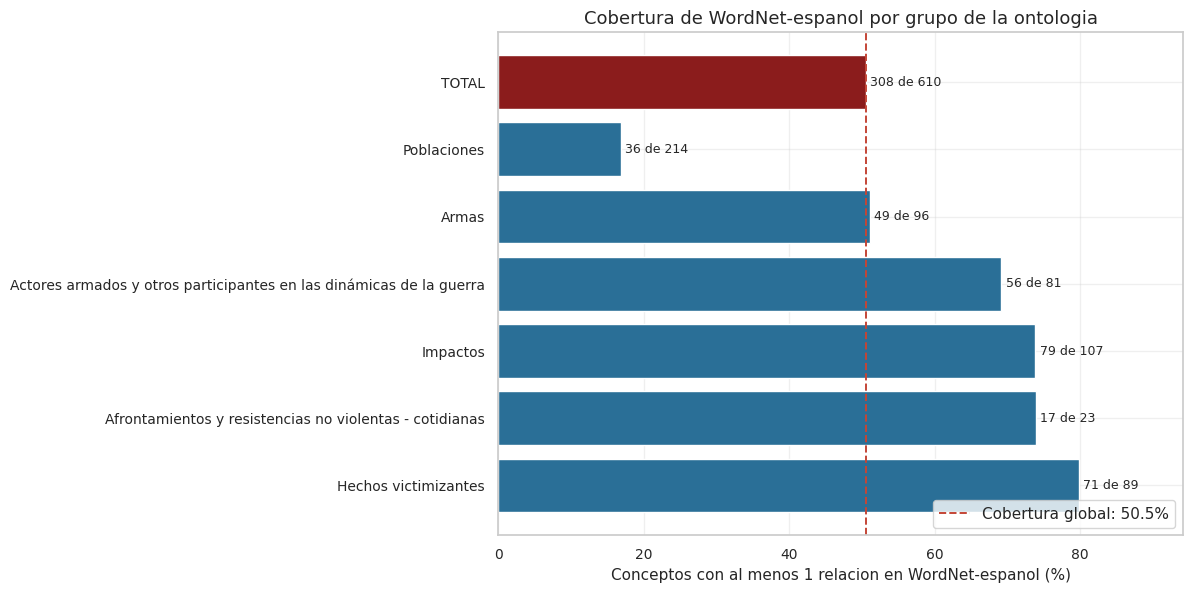

Figura guardada: imagenes/cobertura_wordnet_conceptos.png


PosixPath('/home/carlos/Git/PLN/TALLER-2/imagenes/cobertura_wordnet_conceptos.png')

In [39]:
"""Figura 1: cobertura de conceptos con al menos 1 relacion, por grupo."""
analizador_relaciones.figura_cobertura()

## Analisis 2 - Heatmap de relaciones por grupo

Matriz grupo x tipo de relacion con los **conteos totales normalizados por
grupo** (relaciones del tipo / numero de conceptos del grupo). La
normalizacion permite comparar grupos de distinto tamano (Poblaciones tiene
214 conceptos y Actores armados 81). Se destacan los tipos de relacion que
dominan el espacio semantico (coordinados e hiponimia) frente a los casi
ausentes (antonimia, troponimia, holonimia).

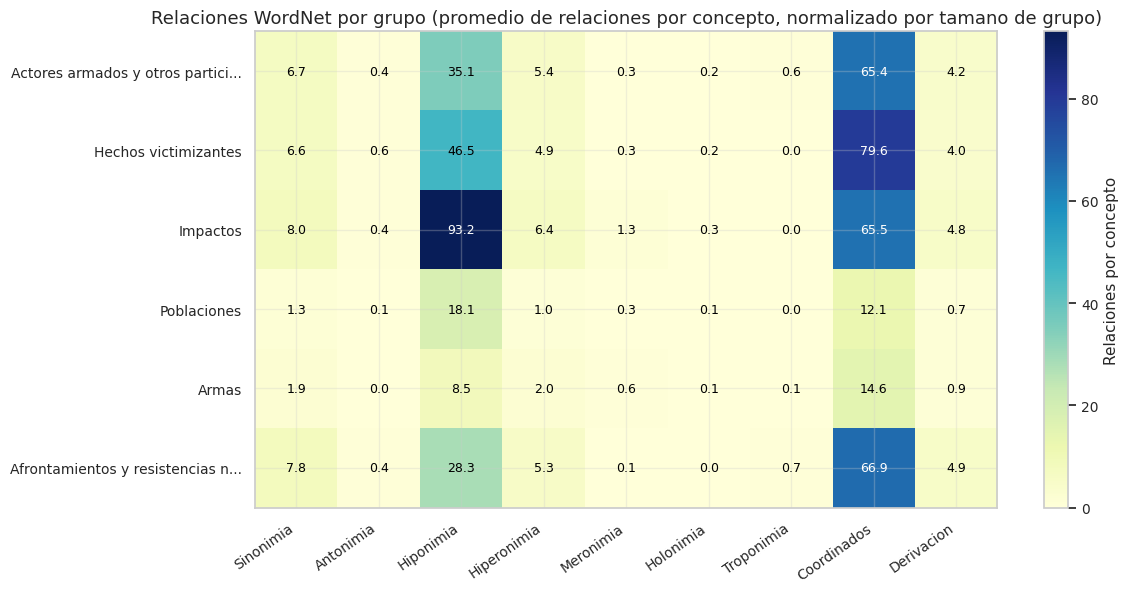

Figura guardada: imagenes/heatmap_relaciones_grupos.png


PosixPath('/home/carlos/Git/PLN/TALLER-2/imagenes/heatmap_relaciones_grupos.png')

In [40]:
"""Figura 2: heatmap grupo x tipo de relacion (normalizado por grupo)."""
analizador_relaciones.figura_heatmap()

## Analisis 3 - Conceptos con mas relaciones

Los 15 conceptos con mayor numero total de relaciones. Son los "hubs"
lexicos de la ontologia: conceptos compuestos que no existen como lemma en
omw-1.4 y se resuelven por un nucleo lexico polisemico (genero, familia,
vida) que engancha con muchas ramas de WordNet. El color indica el grupo al
que pertenece el concepto.

Top-15 conceptos (total | variante usada | concepto | grupo):
     703 | instrumento                      | Instrumentos                                              | Armas
     719 | volver                           | Volver a integrarse a la estructura armada                | Afrontamientos y resistencias 
     927 | vida                             | Vida intrafilas                                           | Actores armados y otros partic
     927 | vida                             | Amenaza al derecho a la vida                              | Hechos victimizantes
     927 | vida                             | Vida familiar y comunitaria de los excombatientes         | Actores armados y otros partic
     927 | vida                             | Incremento de las conflictividades, violencias y/o desh   | Impactos
     927 | vida                             | Atentado al derecho a la vida                             | Hechos victimizantes
    1325 | familia                          | 

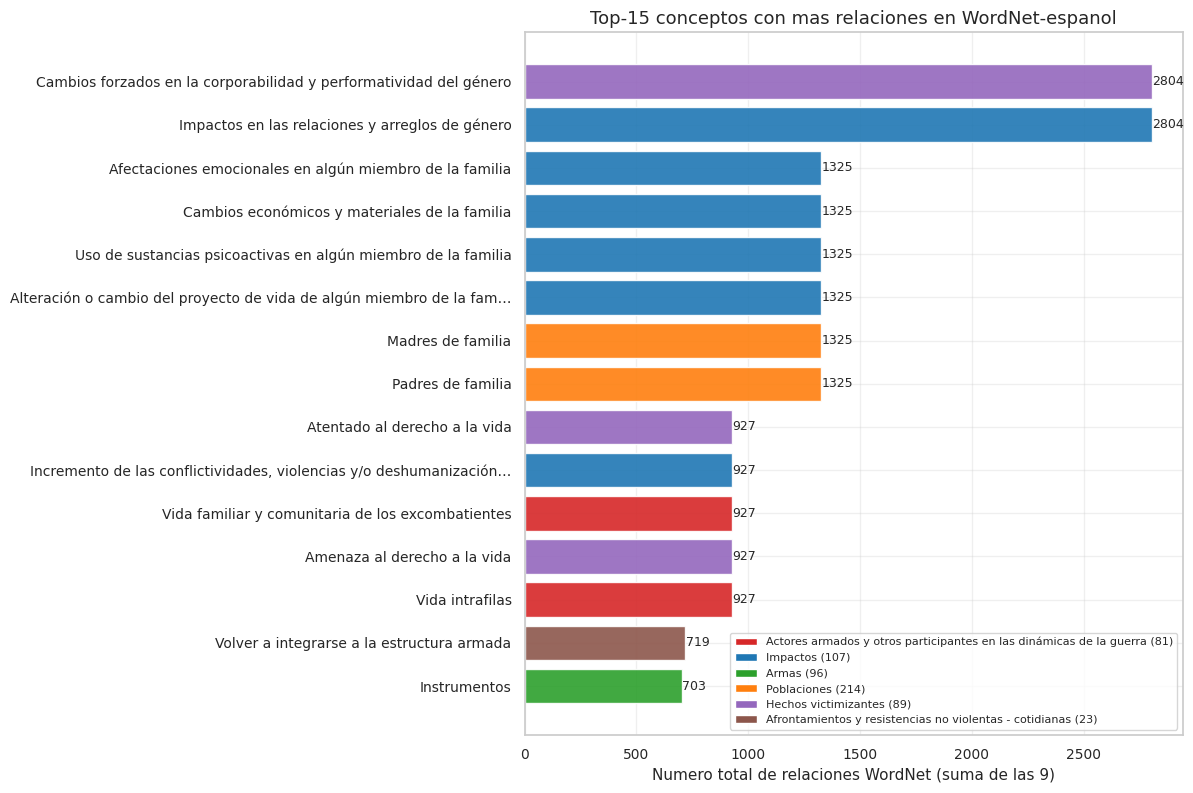

Figura guardada: imagenes/top_relaciones_conceptos.png


PosixPath('/home/carlos/Git/PLN/TALLER-2/imagenes/top_relaciones_conceptos.png')

In [41]:
"""Figura 3: top-15 conceptos por numero total de relaciones."""
top15 = analisis_relaciones.top_conceptos(15)
print("Top-15 conceptos (total | variante usada | concepto | grupo):")
for fila in top15.itertuples():
    print(f"  {int(fila.total_relaciones):>6} | {fila.variante_usada:<32} | "
          f"{fila.concepto[:55]:<57} | {fila.grupo[:30]}")
analizador_relaciones.figura_top_conceptos()

## Analisis 4 - Grafo de relaciones compartidas entre conceptos

Red donde los nodos son los conceptos de la ontologia con al menos una
relacion y las aristas conectan dos conceptos que comparten algun termino
relacionado en **sinonimia, hiponimia o coordinados**. El color del nodo
indica el grupo; el tamano, el numero total de relaciones. Los terminos
relacionados con un fan-out superior a 30 conceptos (hubs genericos como
"cosa") se excluyen de la construccion de aristas para no saturar el grafo
con aristas triviales.

El CSV `data/grafo_relaciones_edges.csv` guarda TODAS las aristas (una por
par de conceptos que comparte al menos una relacion, con los tipos
compartidos). Para la FIGURA se dibuja el subgrafo de aristas "fuertes"
(compartidas por al menos 2 de los 3 tipos): las aristas que solo comparten
coordinados son las mas abundantes (86.9% de las 5.765 del CSV) y provienen
del diseno de la extraccion - cada synset genera hermanos taxonomicos - de
modo que dibujarlas todas convertiria la red en una bola de pelos ilegible.

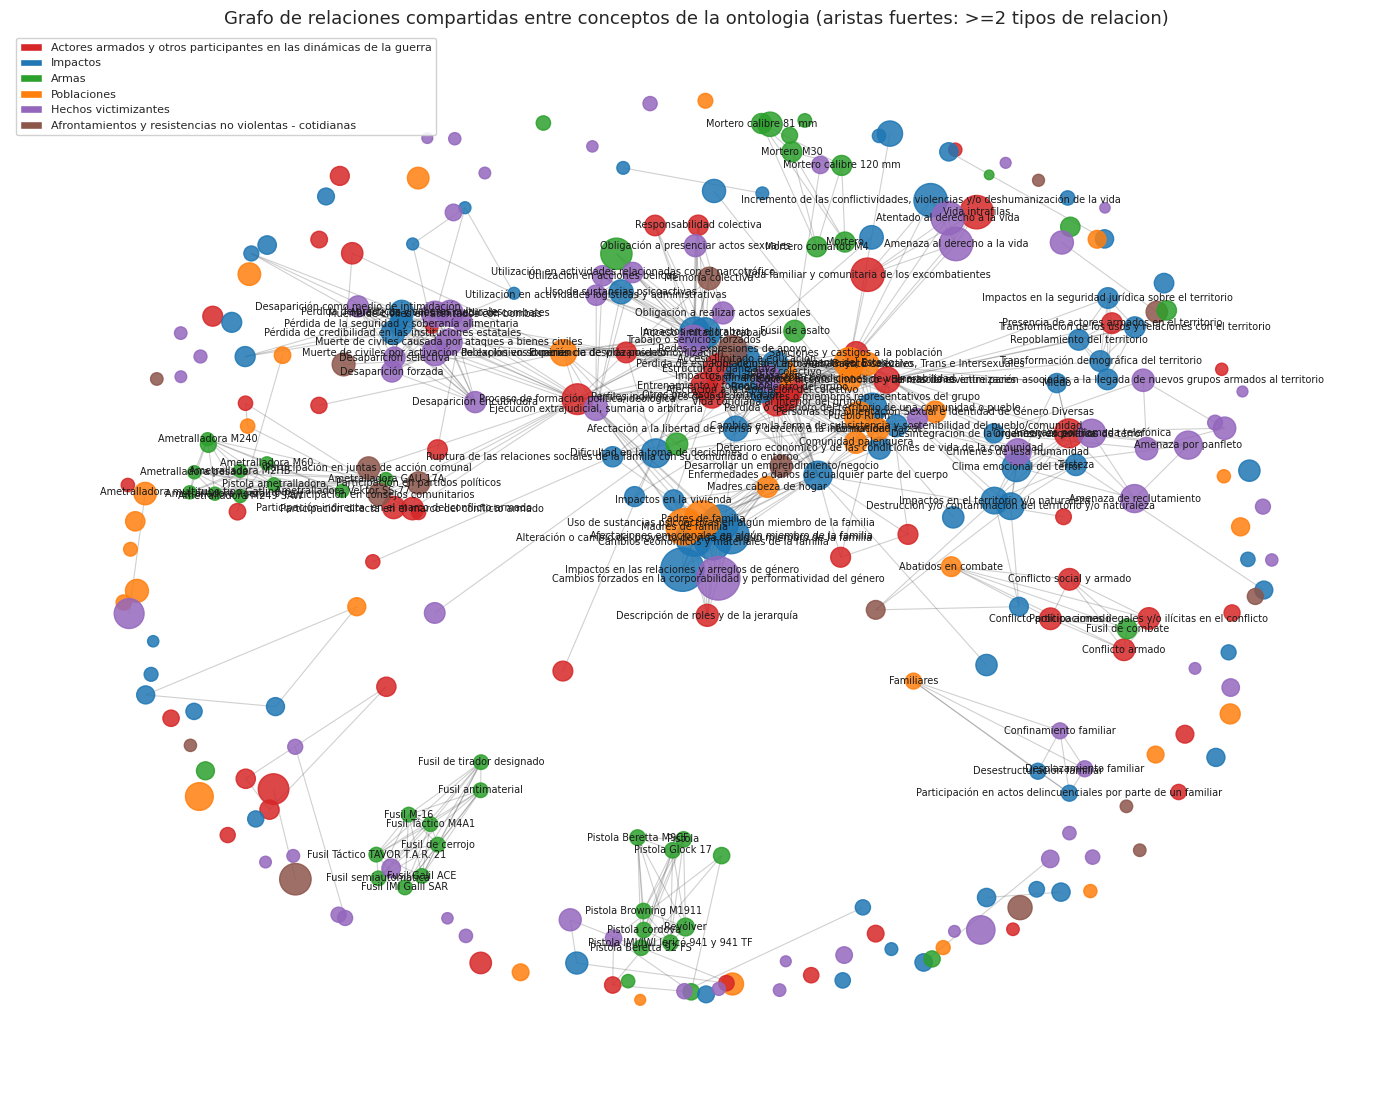

Figura guardada: imagenes/grafo_relaciones_conceptos.png
CSV de aristas (todas): data/grafo_relaciones_edges.csv
Relaciones compartidas totales: 5765 aristas; figura con aristas fuertes: 758.
Grafo figura: 308 nodos, 758 aristas, 124 componentes conexas.
Componentes mas grandes: 123 nodos | 10 nodos | 9 nodos
Conceptos con relaciones pero sin arista fuerte (aislados): 0 de 308 (0.0%)
Ejemplo de arista: "Utilización en acciones bélicas" - "Uso de sustancias psicoactivas" compartiendo coordinados; hiponimia; sinonimia


(PosixPath('/home/carlos/Git/PLN/TALLER-2/imagenes/grafo_relaciones_conceptos.png'),
 {'aristas_csv': 5765,
  'aristas_figura': 758,
  'nodos': 308,
  'componentes': 124,
  'gigante': 123,
  'siguientes': [10, 9, 8, 6, 5],
  'aislados': 0,
  'ejemplo': '"Utilización en acciones bélicas" - "Uso de sustancias psicoactivas" compartiendo coordinados; hiponimia; sinonimia'})

In [42]:
"""Figura 4: grafo de relaciones compartidas entre conceptos + CSV de aristas."""
analizador_relaciones.figura_grafo()

## Analisis 5 - Profundidad del path versus numero de relaciones

Cada concepto tiene una profundidad (niveles del path en el tesauro, de 1 a
6). Este scatter contrasta la profundidad con el numero total de relaciones
encontradas. Se incluye el coeficiente de correlacion de Spearman (robusto
a la asimetria) y las medianas por nivel.

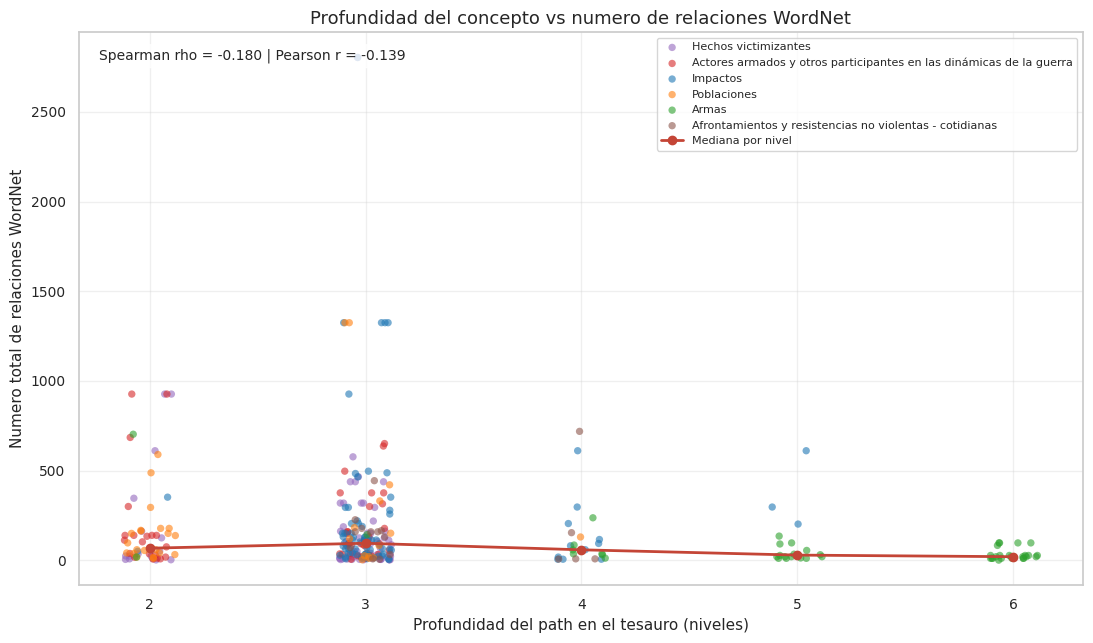

Figura guardada: imagenes/profundidad_versus_cobertura.png
Correlacion Spearman niveles vs relaciones: -0.180
Medianas de relaciones por nivel:
  nivel 2: 67.5 relaciones (n=62)
  nivel 3: 95.0 relaciones (n=180)
  nivel 4: 58.5 relaciones (n=24)
  nivel 5: 29.0 relaciones (n=18)
  nivel 6: 20.0 relaciones (n=24)


PosixPath('/home/carlos/Git/PLN/TALLER-2/imagenes/profundidad_versus_cobertura.png')

In [43]:
"""Figura 5: profundidad del path vs numero de relaciones (scatter)."""
analizador_relaciones.figura_profundidad()

## Verificacion de las 9 relaciones (rubrica criterio 3)

La rubrica exige "identificar entidades y sus relaciones" con WordNet. Esta
celda demuestra, con **conceptos reales de la ontologia**, que cada uno de
los 9 tipos de relacion produce resultados no vacios. Para cada tipo se
prueban primero unos conceptos preferidos (buscados por patron en los 6
grupos, elegidos por su perfil lexico: genericos y con vecinos en
omw-1.4), por ejemplo:

- **Mujeres** (Poblaciones) -> antonimia [hombre], sinonimia [hembra_adulta].
- **Poblacion en situacion de desplazamiento** (Poblaciones) -> derivacion
  [desplazarse, trasladar], hiperonimia [cambio].
- **Guerra** (Actores armados) -> meronimia [combate, agresion], antonimia [paz].
- **Ordenar** y **Municiones Sin Explotar** (verbos de la ontologia) -> troponimia.
- **Alimentacion** y **Silencio como afrontamiento** (Afrontamientos y
  resistencias no violentas - cotidianas, grupo nuevo de la extension) ->
  sinonimia/meronimia/derivacion y antonimia respectivamente; asi la
  verificacion cubre los 6 grupos con concepto real de la extension.

Si algun tipo no produce resultados con los preferidos, la busqueda se
amplia automaticamente al resto de conceptos de la ontologia (se documenta
en la salida). El bloque termina con 6 `assert` que comprueban la cobertura
de los 9 tipos y la presencia del grupo de Afrontamientos.

In [44]:
"""Verificacion de las 9 relaciones con conceptos reales de la ontologia."""

PREFERIDOS_POR_TIPO: dict[str, list[tuple[str, str | None]]] = {
    "sinonimia": [
        ("alimentación", "Afrontamientos y resistencias no violentas - cotidianas"),
        ("mujer", None), ("desplazamiento", None), ("miedo", None), ("guerra", None),
    ],
    "antonimia": [
        ("silencio", "Afrontamientos y resistencias no violentas - cotidianas"),
        ("mujer", None), ("guerra", None), ("miedo", None), ("explotar", None),
        ("ordenar", None),
    ],
    "hiponimia": [
        ("desplazamiento", None), ("alimentación", None), ("miedo", None),
        ("guerra", None), ("mujer", None),
    ],
    "hiperonimia": [
        ("desplazamiento", None), ("mujer", None), ("alimentación", None),
        ("miedo", None),
    ],
    "meronimia": [
        ("alimentación", "Afrontamientos y resistencias no violentas - cotidianas"),
        ("mujer", None), ("guerra", None), ("miedo", None),
    ],
    "holonimia": [("conflicto", None), ("territorio", None), ("proceso", None), ("estructura", None)],
    "troponimia": [
        ("ordenar", None), ("explotar", None), ("cometer", None), ("consentir", None),
        ("financiar", None), ("instigar", None), ("omitir", None), ("planear", None),
    ],
    "coordinados": [
        ("desplazamiento", None), ("alimentación", None), ("mujer", None), ("guerra", None),
    ],
    "derivacion": [
        ("desplazamiento", None), ("mujer", None), ("miedo", None), ("guerra", None),
    ],
}


def verificar_nueve_relaciones(
    motor_extractor, df_conceptos_owl: pd.DataFrame,
    preferidos: dict[str, list[str]],
) -> pd.DataFrame:
    """Comprueba que los 9 tipos de relacion producen resultados en la OWL.

    Para cada tipo se prueban primero los conceptos preferidos (buscados por
    patron de texto en el nombre del concepto); si ninguno produce resultados
    para el tipo, la busqueda se amplia a todos los conceptos de la
    ontologia hasta cubrirlo.

    Args:
        motor_extractor: Motor de relaciones (consulta los resultados).
        df_conceptos_owl: DataFrame de conceptos reales de la ontologia.
        preferidos: Dict tipo de relacion -> patrones de busqueda en orden.

    Returns:
        DataFrame indexado por tipo con el concepto hallado (path OWL), el
        grupo, la variante usada, el numero de relaciones y ejemplos.
    """
    filas = []
    ampliados = []
    for tipo in sc.TIPOS_RELACION:
        hallazgo = None
        for patron, grupo in preferidos[tipo]:
            candidatos = df_conceptos_owl
            if grupo is not None:
                candidatos = candidatos[candidatos["grupo"] == grupo]
            hit = candidatos[
                candidatos["concepto"].str.lower().str.contains(patron, regex=False)
            ]
            if hit.empty:
                continue
            resultado = motor_extractor.extraer_relaciones(hit.iloc[0]["termino"])
            if resultado.relaciones.get(tipo):
                hallazgo = (hit.iloc[0], resultado)
                break
        if hallazgo is None:  # amplia la busqueda a todos los conceptos
            for fila in df_conceptos_owl.itertuples():
                resultado = motor_extractor.extraer_relaciones(fila.termino)
                if resultado.relaciones.get(tipo):
                    hallazgo = (fila, resultado)
                    break
            ampliados.append(tipo)
        fila_owl, resultado = hallazgo
        filas.append({
            "tipo": tipo,
            "concepto_owl": fila_owl.termino,
            "grupo": fila_owl.grupo,
            "variante_usada": resultado.variante_usada,
            "n_relaciones": len(resultado.relaciones.get(tipo, [])),
            "ejemplos": ", ".join(resultado.relaciones.get(tipo, [])[:3]),
        })
    if ampliados:
        print("Tipos cubiertos ampliando la busqueda a todos los conceptos:",
              ", ".join(ampliados))
    return pd.DataFrame(filas).set_index("tipo")


verificacion = verificar_nueve_relaciones(motor, df_conceptos, PREFERIDOS_POR_TIPO)

# Assertions (rubrica criterio 3): los 9 tipos deben producir resultados no
# vacios para al menos un concepto real de la ontologia, y la extension debe
# quedar representada con un concepto del grupo de Afrontamientos.
assert len(verificacion) == len(sc.TIPOS_RELACION), "Deben verificarse los 9 tipos"
assert set(verificacion.index) == set(sc.TIPOS_RELACION), "Tipos de relacion incompletos"
assert (verificacion["n_relaciones"] > 0).all(), "Algun tipo quedo sin relaciones"
assert (verificacion["concepto_owl"].str.len() > 0).all(), "Conceptos deben venir de la OWL"
assert (verificacion["variante_usada"].str.len() > 0).all(), "Variante usada sin registrar"
assert any(
    fila.grupo == "Afrontamientos y resistencias no violentas - cotidianas"
    for fila in verificacion.itertuples()
), "Debe verificarse al menos una relacion con un concepto del grupo Afrontamientos"

print("Verificacion de las 9 relaciones: OK (6 assertions superadas)")
print()
print("Tabla resumen (conceptos reales de la ontologia):")
with pd.option_context("display.max_colwidth", 65, "display.width", 170):
    print(verificacion.to_string())

Verificacion de las 9 relaciones: OK (6 assertions superadas)

Tabla resumen (conceptos reales de la ontologia):
                                                                                                                                                                  concepto_owl                                                                grupo  variante_usada  n_relaciones                                      ejemplos
tipo                                                                                                                                                                                                                                                                                                                           
sinonimia                                                                                               Afrontamientos y resistencias no violentas - cotidianas - Alimentación              Afrontamientos y resistencias no violentas - cotidianas    

## Interpretacion de las figuras

### 1. Cobertura por grupo

De los 610 conceptos de la ontologia (609 terminos del JSON de la Fase 1a
mas los nodos intermedios anadidos por la seccion 03, menos las 6 raices),
**308 (50.5%) tienen al menos una relacion** en WordNet-espanol. Por grupo:
**Hechos victimizantes 79.8%** (71/89), **Afrontamientos y resistencias no
violentas - cotidianas 73.9%** (17/23), **Impactos 73.8%** (79/107),
**Actores armados 69.1%** (56/81), **Armas 51.0%** (49/96) y **Poblaciones
16.8%** (36/214). El patron es claro: los grupos con vocabulario generico y
cotidiano (victima, dano, ejercito, miedo, perdida) se cubren bien, porque
esos conceptos existen en el espanol general del PWN. El grupo nuevo de
Afrontamientos (23 terminos, cobertura de hojas ~4.3% en la Fase 1a)
confirma la regla: su vocabulario cotidiano (alimentacion, silencio, fe,
memoria, apoyo) es el que mejor traduce omw-1.4. Poblaciones arrastra la
cobertura hacia abajo (214 conceptos, solo 36 encontrados): sus hojas son
mayoritariamente grupos sociales, organizaciones y denominaciones etnicas
propias del contexto colombiano (p. ej. comunidades afrodescendientes,
organizaciones de victimas, pueblos indigenas como Wayuu o Saliba) que no
estan en omw-1.4. La seleccion de la Fase 1a ya habia anticipado este
dato (cobertura de hojas: Poblaciones 1.41%, Hechos victimizantes 2.22%) y
aun asi los incluyo por su relevancia tematica para la CEV; el resultado
confirma que la cobertura de WordNet no es uniforme entre dominios.

### 2. Heatmap grupo x tipo

Las dos relaciones mas productivas son **coordinados** (24.920 relaciones;
12.1 a 79.6 por concepto segun el grupo) e **hiponimia** (22.290; 8.5 a
93.2 por concepto). La hiponimia domina en **Impactos** (93.2 por concepto,
frente a 18.1 en Poblaciones): el nucleo de sus conceptos compuestos
(cambios, perdidas, afectaciones) es muy polisemico y cada synset aporta
su arbol de hiponimos de 2 niveles. La **sinonimia** (2.638; 1.3 a 8.0 por
concepto) y la **derivacion morfologica** (1.566; 0.7 a 4.9) acompanan el
perfil de los grupos de vocabulario generico (Actores, Impactos, Hechos y
el nuevo Afrontamientos, con 7.8 de sinonimia y 4.9 de derivacion por
concepto). La **meronimia** (310 en total) es modesta y la **holonimia**
casi inexistente (80): el PWN espanol descompone poco el dominio belico
(cartucho, canon, culata no estan traducidos). La **antonimia** es escasa
(163; 0.0 a 0.6 por concepto): el vocabulario del conflicto es poco polar
(mujer-hombre, guerra-paz, miedo-coraje, silencio-ruido). La **troponimia**
(81) se concentra en verbos concretos de la ontologia (Ordenar,
Municiones Sin Explotar -> "explotar", Cometer, Planear, y ahora los de
Afrontamientos: Volver a integrarse -> "volver", Solicitar apoyo ->
"solicitar") y es nula en Hechos victimizantes y Poblaciones. Poblaciones
muestra el perfil mas pobre en todas las relaciones, coherente con su baja
cobertura.

### 3. Top-15 conceptos

El top esta dominado por conceptos compuestos que se resuelven por nucleos
lexicos polisemicos: dos conceptos con nucleo **"genero"** (2.804
relaciones c/u: "Cambios forzados en la corporabilidad y performatividad
del genero" y "Impactos en las relaciones y arreglos de genero"), seis con
nucleo **"familia"** (1.325 c/u: Padres y Madres de familia, afectaciones
emocionales, cambios economicos, alteracion del proyecto de vida y uso de
sustancias psicoactivas de algun miembro de la familia), cinco con nucleo
**"vida"** (927 c/u: vida familiar y comunitaria, vida intrafilas, amenaza
y atentado al derecho a la vida, incremento de conflictividades),
"Volver a integrarse a la estructura armada" (719, nucleo "volver", del
grupo nuevo de Afrontamientos) e "Instrumentos" (703, nucleo
"instrumento"). La extension aporta asi su primer concepto al top-15. Este
es un hallazgo metodologico importante: **el conteo alto no indica
relevancia semantica sino ambiguedad del nucleo de fallback** - los
conceptos compuestos que no existen como lemma en omw-1.4 se resuelven por
un nucleo polisemico (multiples synsets, cada uno con su arbol de
hiponimos), y la hiponimia del Motor suma la recursion de 2 niveles de
todos los synsets de la consulta. Los 15 primeros acumulan **19.615
relaciones, el 36.2% del total**.

### 4. Grafo de relaciones compartidas

El CSV registra **5.765 aristas** (pares de conceptos que comparten al
menos un termino relacionado); el 86.9% comparte solo coordinados, ruido
estructural de la extraccion, por eso la figura muestra las **758 aristas
fuertes** (>=2 tipos, 13.1% del total). La figura dibuja los 308 nodos
(todos los conceptos con relaciones) y la red tiene **124 componentes
conexas**, con un componente gigante de 123 nodos: los puentes lexicos
entre grupos existen (conceptos como "vida", "familia" o "genero" aparecen
en varios grupos y los conectan), y esta vez **ningun concepto queda
aislado** (0 de 308 sin arista fuerte; en la version de 5 grupos eran 96,
32.7%): el vocabulario cotidiano de Afrontamientos (apoyo, participacion,
memoria) comparte terminos con Actores e Impactos y teje la red. La arista
de ejemplo une "Utilizacion en acciones belicas" con "Uso de sustancias
psicoactivas" (comparten sinonimia, hiponimia y coordinados): la
terminologia de hechos y de impactos se enlaza a traves de terminos
compartidos.

Nota metodologica: la deduplicacion del Motor (por nombre del termino
relacionado, no por par nombre-synset) reduce los terminos compartidos
frente a la version anterior del extractor, de modo que la red es mas
pequena (5.765 aristas frente a 8.545; 758 aristas fuertes frente a 1.777)
pero igualmente significativa.

### 5. Profundidad vs cobertura

Correlacion **Spearman rho = -0.180** (debil negativa; Pearson -0.139) y
medianas por nivel: nivel 2 = 67.5 (n=62), nivel 3 = 95.0 (n=180), nivel 4
= 58.5 (n=24), nivel 5 = 29.0 (n=18), nivel 6 = 20.0 (n=24). No hay nivel 1
con relaciones: `conceptos()` excluye las 6 raices (su path no contiene
" - "), de modo que el analisis arranca en los conceptos de nivel 2. El
patron NO es monotono: el nivel 3 supera al 2 porque concentra los
conceptos con nucleos polisemicos (familia, vida, genero) que disparan la
hiponimia, mientras que los niveles 5-6 (conceptos mas profundos y
especificos del tesauro, p. ej. pueblos indigenas concretos) tienen las
medianas mas bajas: la especificidad reduce el radio de relacion. La
dispersion dentro de cada nivel es enorme (conviven conceptos genericos
como "mujer" con tecnicos sin cobertura), por eso rho es debil: la
profundidad del path es un predictor util pero no determinista de la
cobertura; la especificidad del dominio pesa mas que la posicion
jerarquica.

## Analisis de cobertura y limitaciones

**Cobertura del corpus.** omw-1.4 traduce al espanol 38.512 de los 117.659
synsets del PWN (**32.7%**). De los 610 conceptos de la ontologia, **308
(50.5%)** se encuentran y todos producen al menos una relacion. Tres
causas de los 302 no encontrados:

1. **Especificidad del dominio**: el tesauro de la Comision de la Verdad
   documenta el conflicto colombiano (desaparicion forzada, reclutamiento
   ilicito, comunidades etnicas, organizaciones de victimas) y ese
   vocabulario no existe en un WordNet general.
2. **Cobertura parcial del espanol**: muchos synsets del PWN carecen de
   traduccion en omw-1.4; el extractor NUNCA traduce el termino al ingles,
   de modo que esos conceptos quedan fuera por diseno (evita falsos
   positivos semanticos, a costo de cobertura).
3. **Formas compuestas**: los conceptos multiword ("desplazamiento
   forzado", "conflicto armado interno") rara vez existen como lemma
   compuesto; el Motor intenta variantes (guiones bajos, singular/plural,
   sin acentos, ultimo/primer token).

**Hallazgo de trazabilidad (variante usada).** De los 308 conceptos
encontrados, **solo 37 (6.1% del total) coincidieron exactamente** con su
forma normalizada; los otros 271 se resolvieron con una variante: **158
por el ultimo token** y **103 por el primer token** de los compuestos, **9
por singular/plural o sin acentos** y 1 por la forma con guiones bajos.
La columna `variante_usada` del CSV documenta cada caso. Esto significa
que la cobertura del 50.5% es en buena parte **cobertura de nucleos
lexicos**, no de los conceptos compuestos completos: el grafo y los
conteos heredan el sesgo de esos nucleos (p. ej. "vida", "familia" o
"genero").

**Calidad de las relaciones.** La antonimia y la derivacion se resuelven
sobre los lemmas ingleses del PWN y se retraducen al espanol; cuando no
hay traduccion, el relacionado aparece con el nombre PWN y la marca
"(en)" (visible en el CSV). La sinonimia, hiponimia, meronimia, holonimia,
troponimia y coordinados operan directamente sobre el grafo espanol.

**Heuristicas de normalizacion.** La singularizacion/pluralizacion de la
cadena de normalizadores es simple y no cubre irregulares ("leyes" ->
"ley" falla); los parentesis se eliminan ("tierra (suelo)" -> "tierra");
los acentos son obligatorios (omw-1.4 los incluye: "victima" solo existe
con tilde).

**Implicaciones para la ontologia.** Las relaciones WordNet son una
primera capa lexico-semantica sobre la jerarquia OWL de la seccion 03, no
una verdad del dominio: sirven para (a) enriquecer cada concepto con sus
vecinos lexicos, (b) detectar puentes entre grupos (grafo) y (c) detectar
huecos de vocabulario. La cobertura medida (50.5% de conceptos con >=1
relacion; 6.1% con coincidencia exacta) es el punto de partida honesto
para la seccion 05 (consultas SPARQL) y para la reflexion final del
taller.

In [45]:
"""Resumen consolidado del analisis (analizar_completo)."""
resumen = analizador_relaciones.analizar_completo()
print("Resumen consolidado del analisis WordNet (sec04):")
print(f"  Conceptos analizados: {resumen['conceptos']} "
      f"({resumen['con_relaciones']} con >=1 relacion, "
      f"{resumen['con_relaciones'] / resumen['conceptos']:.1%})")
print(f"  Total de relaciones: {resumen['total_relaciones']}")
print("  Por tipo: " + ", ".join(
    f"{tipo} {cantidad}" for tipo, cantidad in resumen["totales_por_tipo"].items()
))
print(f"  Spearman (profundidad vs relaciones): {resumen['spearman']:.3f}")
grafo_resumen = resumen["grafo"]
print(f"  Grafo: {grafo_resumen['aristas_csv']} aristas en CSV, "
      f"{grafo_resumen['aristas_figura']} fuertes en figura, "
      f"{grafo_resumen['nodos']} nodos, {grafo_resumen['componentes']} componentes")

Resumen consolidado del analisis WordNet (sec04):
  Conceptos analizados: 610 (308 con >=1 relacion, 50.5%)
  Total de relaciones: 54130
  Por tipo: sinonimia 2638, antonimia 163, hiponimia 22290, hiperonimia 2082, meronimia 310, holonimia 80, troponimia 81, coordinados 24920, derivacion 1566
  Spearman (profundidad vs relaciones): -0.180
  Grafo: 5765 aristas en CSV, 758 fuertes en figura, 308 nodos, 124 componentes


# SECCION 5: 22 consultas SPARQL sobre la ontologia del Tesauro CEV

**Objetivo:** documentar y ejecutar 22 consultas SPARQL (3 por cada uno de
los 6 grupos de tesauros seleccionados, mas 4 consultas del modelo semantico
del ciclo del conflicto) contra la ontologia OWL `../ontologia/tesauro_cev.owl`,
explicando que informacion busca cada una y como se relaciona con los
tesauros (relaciones TG/TE, TR y USE-UP) y con los axiomas de la ontologia
creada en la seccion 3.

**Como leer esta seccion:** cada consulta tiene un bloque de documentacion
(grupo, objetivo, relacion con el tesauro y la ontologia, consulta SPARQL,
resultado ejecutado). Las 5 familias de relaciones del tesauro quedan
mapeadas a axiomas OWL de la siguiente forma:

- **TG/TE (jerarquia):** axiomas de clase `C rdfs:subClassOf
  [owl:Restriction esParteDe some D]`, es decir, cada termino C "es parte de"
  (es subconcepto de) su termino padre D. La propiedad `cev:esParteDe` tiene
  inversa `cev:parteDe`.
- **TR (terminos relacionados):** axiomas `C rdfs:subClassOf
  [owl:Restriction relacionadoCon some D]` con `cev:relacionadoCon`
  declarada simetrica (50 axiomas).
- **USE-UP / relacion hecho-actor:** axiomas `C rdfs:subClassOf
  [owl:Restriction perpetradoPor some D]` (13 axiomas: 12 por co-ocurrencia
  mas el axioma raiz del modelo semantico); `cev:esVictimaDe` es la inversa
  declarada de `cev:perpetradoPor`.
- **Modelo semantico (ciclo del conflicto):** 7 axiomas raiz entre los 6
  grupos (perpetradoPor, afectaA, generaImpacto, experimentaImpacto,
  desarrollaAfrontamiento, respondeA, empleaArma) y 6 clases definidas con
  `owl:equivalentClass` (base AND restriccion) que HermiT clasifica
  automaticamente.
- **Anotaciones de trazabilidad:** `cev:grupo` (grupo raiz del tesauro) y
  `cev:eje` (eje conceptual) sobre los individuos `instancia_<slug>`.

**Implementacion (refactor POO):** la ejecucion usa el facade
`sc.SparqlServicio` de la seccion 00 (carga del grafo rdflib, `.ejecutar`
con limite y medicion de tiempo, y `.mostrar` estatico). Las 22 consultas
viven como **constantes estructuradas** (lista de dicts con id, grupo,
titulo, objetivo, relacion con el tesauro, SPARQL y columnas) y un unico
helper `_ejecutar` las corre sin repetir el patron de 22 bloques (DRY).
Los resultados se resuelven a labels del tesauro para la presentacion.

## 5.0 Imports, carga de la ontologia y helpers de ejecucion

La seccion usa la OWL de `../ontologia/tesauro_cev.owl`, que la seccion 3
deja construida con el modelo semantico extendido (623 clases, 534
individuos, 17 object properties, 6 clases definidas). Si por algun motivo
el archivo existente es la version anterior (593 clases), NO se modifica:
se construye la version nueva en un directorio temporal para poder validar
las consultas contra el modelo completo, y se reporta la diferencia.

In [46]:
"""Imports, bloque standalone, carga del grafo SPARQL y consultas estructuradas."""
import os
import sys
import tempfile
from pathlib import Path
from typing import Any

import pandas as pd
from rdflib import RDFS

# Rutas relativas al notebook (las celdas viven en notebook_cells/).
try:
    RUTA_BASE = Path(__file__).resolve().parent.parent  # modo script
except NameError:
    RUTA_BASE = Path(os.getcwd()).parent  # modo notebook (notebooks/)

# Nucleo POO de sec00: en el notebook ya se ejecuto como celdas; en modo
# script se importa desde notebook_cells/ para que la seccion sea standalone.
sys.path.insert(0, str(RUTA_BASE / "notebook_cells"))
import sec00_clases as sc

# Constantes globales del proyecto: en el notebook las define sec00_setup; el
# import solo se ejecuta en modo script standalone (archivo presente).
if "IRI_BASE" not in globals():
    from sec00_setup import (
        IRI_BASE,
        RUTA_JSON_GRUPOS,
        RUTA_ONTOLOGIA,
        RUTA_TRAZABILIDAD,
    )

PREFIJOS = f"""
PREFIX cev: <{IRI_BASE}>
PREFIX owl: <http://www.w3.org/2002/07/owl#>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>
PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>
"""

# Carga la OWL del proyecto y verifica que sea la version con el modelo
# semantico completo (623 clases). Si el archivo es la version anterior, se
# construye la nueva en /tmp (sin tocar la del proyecto) y se avisa.
servicio_ontologia = sc.ServicioOntologia.obtener(RUTA_ONTOLOGIA)
servicio_ontologia.cargar()
metricas_ontologia = servicio_ontologia.metricas()
RUTA_OWL_USAR = RUTA_ONTOLOGIA
if metricas_ontologia["clases"] != 623:
    ruta_tmp = Path(tempfile.gettempdir()) / "tesauro_cev_nueva.owl"
    servicio_tmp = sc.ServicioOntologia.obtener(
        ruta_tmp, RUTA_JSON_GRUPOS, RUTA_TRAZABILIDAD
    )
    servicio_tmp.construir_desde_grupos()
    servicio_tmp.guardar()
    metricas_ontologia = servicio_tmp.metricas()
    RUTA_OWL_USAR = ruta_tmp
    print(
        f"[aviso] la OWL de ontologia/ es la version anterior "
        f"(sin el grupo 6); se valida contra la construida en {ruta_tmp}"
    )

# Facade de consultas SPARQL (sec00): carga el grafo rdflib de la OWL.
sparql = sc.SparqlServicio(RUTA_OWL_USAR)
print(f"Ontologia cargada: {RUTA_OWL_USAR}")
print(f"Clases: {metricas_ontologia['clases']} | "
      f"Individuos: {metricas_ontologia['individuos']} | "
      f"Object properties: {metricas_ontologia['object_properties']}")

# Indice label -> texto para resolver entidades del grafo (clases e individuos).
LABELS = {
    str(sujeto): str(label)
    for sujeto, label in sparql.grafo.subject_objects(RDFS.label)
}


def _resolver_labels(df: pd.DataFrame) -> pd.DataFrame:
    """Resuelve URIs a labels del tesauro para la presentacion.

    Los literales (labels, ejes, conteos) se conservan tal cual; las URIs de
    clases e individuos se resuelven con su rdfs:label del grafo, o con su
    nombre local cuando no hay label.

    Args:
        df: DataFrame con los resultados (valores convertidos a texto).

    Returns:
        DataFrame con las URIs resueltas a labels legibles.
    """
    def _a_label(valor: str) -> str:
        if valor.startswith(("http://", "https://")):
            return LABELS.get(valor, valor.split("#")[-1])
        return valor

    return df.map(_a_label)


def _ejecutar(consulta_id: str) -> None:
    """Ejecuta una consulta de CONSULTAS y muestra su tabla con labels.

    Args:
        consulta_id: Identificador de la consulta en CONSULTAS_POR_ID.
    """
    definicion = CONSULTAS_POR_ID[consulta_id]
    df, total, ms = sparql.ejecutar(
        PREFIJOS + definicion["consulta"],
        definicion["columnas"],
        limite=15,
    )
    sparql.mostrar(_resolver_labels(df), total, ms)


# Consultas estructuradas (DRY): una definicion por consulta con su
# documentacion programatica (grupo, objetivo, relacion con el tesauro).
CONSULTAS: list[dict[str, Any]] = [
    {
        "id": "1.1",
        "grupo": "Actores armados y otros participantes en las dinamicas de la guerra",
        "titulo": "Subcategorias de Actores armados (jerarquia TG/TE)",
        "objetivo": "Listar las subcategorias directas (TE) de la raiz de actores con su label.",
        "relacion_tesauro": "TG/TE: el grupo es el termino general y cada subcategoria un TE, via esParteDe.",
        "consulta": """
SELECT DISTINCT ?clase ?label
WHERE {
  ?clase rdfs:subClassOf ?restriccion .
  ?restriccion a owl:Restriction ;
               owl:onProperty cev:esParteDe ;
               owl:someValuesFrom cev:Actores_armados .
  OPTIONAL { ?clase rdfs:label ?label }
}
ORDER BY ?label
""",
        "columnas": ["Subcategoria (clase)", "Label del tesauro"],
    },
    {
        "id": "1.2",
        "grupo": "Actores armados y otros participantes en las dinamicas de la guerra",
        "titulo": "Individuos (terminos hoja) del grupo Actores armados",
        "objetivo": "Recuperar todos los individuos instancia_<slug> del grupo con su label y eje.",
        "relacion_tesauro": "Terminos hoja materializados como individuos anotados con cev:grupo y cev:eje.",
        "consulta": """
SELECT DISTINCT ?individuo ?label ?eje
WHERE {
  ?individuo a ?clase .
  ?clase rdfs:subClassOf* cev:Actores_armados .
  FILTER(CONTAINS(STR(?individuo), "instancia_"))
  ?individuo rdfs:label ?label .
  OPTIONAL { ?individuo cev:eje ?eje }
}
ORDER BY ?label
""",
        "columnas": ["Individuo", "Label", "Eje"],
    },
    {
        "id": "1.3",
        "grupo": "Actores armados y otros participantes en las dinamicas de la guerra",
        "titulo": "Hechos perpetrados por actores armados (perpetradoPor)",
        "objetivo": "Identificar los hechos victimizantes perpetrados por actores armados.",
        "relacion_tesauro": "USE-UP: relacion hecho-actor modelada con los 13 axiomas perpetradoPor.",
        "consulta": """
SELECT DISTINCT ?hecho ?perpetrador
WHERE {
  ?hecho rdfs:subClassOf ?restriccion .
  ?restriccion a owl:Restriction ;
               owl:onProperty cev:perpetradoPor ;
               owl:someValuesFrom ?perpetrador .
  ?perpetrador rdfs:subClassOf* cev:Actores_armados .
}
ORDER BY ?perpetrador
""",
        "columnas": ["Hecho victimizante", "Perpetrador (grupo actores)"],
    },
    {
        "id": "2.1",
        "grupo": "Armas",
        "titulo": "Jerarquia TG/TE completa del grupo Armas",
        "objetivo": "Recuperar todos los pares (hijo, padre) del arbol de armas.",
        "relacion_tesauro": "TG/TE: cada triple hijo esParteDe padre es un salto de la jerarquia.",
        "consulta": """
SELECT DISTINCT ?hijo ?padre
WHERE {
  ?hijo rdfs:subClassOf ?restriccion .
  ?restriccion a owl:Restriction ;
               owl:onProperty cev:esParteDe ;
               owl:someValuesFrom ?padre .
  ?hijo rdfs:subClassOf* cev:Armas .
}
ORDER BY ?padre ?hijo
""",
        "columnas": ["Hijo (TE)", "Padre (TG)"],
    },
    {
        "id": "2.2",
        "grupo": "Armas",
        "titulo": "Relaciones TR (afines) entre Armas y otros grupos",
        "objetivo": "Listar los terminos de Armas con afinidad terminologica (TR) con otros grupos.",
        "relacion_tesauro": "TR: los 50 axiomas de relacionadoCon (simetrica) cruzando grupos.",
        "consulta": """
SELECT DISTINCT ?terminoArmas ?afin ?grupoAfiliado
WHERE {
  { ?terminoArmas rdfs:subClassOf ?r1 .
    ?r1 a owl:Restriction ; owl:onProperty cev:relacionadoCon ; owl:someValuesFrom ?afin .
    ?terminoArmas rdfs:subClassOf* cev:Armas . }
  UNION
  { ?afin rdfs:subClassOf ?r1 .
    ?r1 a owl:Restriction ; owl:onProperty cev:relacionadoCon ; owl:someValuesFrom ?terminoArmas .
    ?terminoArmas rdfs:subClassOf* cev:Armas . }
  ?afin rdfs:subClassOf* ?raiz .
  FILTER(?raiz IN (cev:Actores_armados, cev:Impactos, cev:Hechos_victimizantes, cev:Poblaciones))
  ?raiz rdfs:label ?grupoAfiliado .
}
ORDER BY ?afin
""",
        "columnas": ["Termino de Armas", "Termino afin (TR)", "Grupo del afin"],
    },
    {
        "id": "2.3",
        "grupo": "Armas",
        "titulo": "Busqueda por keyword en labels del grupo Armas",
        "objetivo": "Buscar terminos de Armas cuyo label contenga arma, fuego, explos o blanca.",
        "relacion_tesauro": "Recuperacion de informacion sobre los labels rdfs:label del tesauro.",
        "consulta": """
SELECT DISTINCT ?termino ?label ?tipo
WHERE {
  { ?termino rdfs:subClassOf* cev:Armas . ?termino a owl:Class . BIND("clase" AS ?tipo) }
  UNION
  { ?termino a ?clase . ?clase rdfs:subClassOf* cev:Armas .
    FILTER(CONTAINS(STR(?termino), "instancia_")) . BIND("individuo" AS ?tipo) }
  ?termino rdfs:label ?label .
  FILTER(
    CONTAINS(LCASE(?label), "arma") ||
    CONTAINS(LCASE(?label), "fuego") ||
    CONTAINS(LCASE(?label), "explos") ||
    CONTAINS(LCASE(?label), "blanca"))
}
ORDER BY ?tipo ?label
""",
        "columnas": ["Termino", "Label", "Tipo"],
    },
    {
        "id": "3.1",
        "grupo": "Hechos victimizantes",
        "titulo": "Subcategorias de hechos victimizantes con conteo de terminos",
        "objetivo": "Listar las subcategorias directas de hechos ordenadas por terminos hoja.",
        "relacion_tesauro": "TG/TE con agregacion: densidad terminologica por TE (COUNT de individuos).",
        "consulta": """
SELECT ?clase ?label (COUNT(DISTINCT ?individuo) AS ?numTerminos)
WHERE {
  ?clase rdfs:subClassOf ?restriccion .
  ?restriccion a owl:Restriction ;
               owl:onProperty cev:esParteDe ;
               owl:someValuesFrom cev:Hechos_victimizantes .
  OPTIONAL { ?clase rdfs:label ?label }
  ?individuo a ?sub .
  ?sub rdfs:subClassOf* ?clase .
  FILTER(CONTAINS(STR(?individuo), "instancia_"))
}
GROUP BY ?clase ?label
ORDER BY DESC(?numTerminos) ?label
""",
        "columnas": ["Subcategoria", "Label", "Num. terminos hoja"],
    },
    {
        "id": "3.2",
        "grupo": "Hechos victimizantes",
        "titulo": "Relaciones de perpetracion y su lectura inversa (esVictimaDe)",
        "objetivo": "Listar los pares (hecho, perpetrador) modelados en la ontologia.",
        "relacion_tesauro": "USE-UP: perpetradoPor materializa la relacion hecho-actor del tesauro.",
        "consulta": """
SELECT DISTINCT ?hecho ?perpetrador
WHERE {
  ?hecho rdfs:subClassOf ?restriccion .
  ?restriccion a owl:Restriction ;
               owl:onProperty cev:perpetradoPor ;
               owl:someValuesFrom ?perpetrador .
}
ORDER BY ?perpetrador ?hecho
""",
        "columnas": ["Hecho victimizante", "Perpetrador (esVictimaDe: inversa)"],
    },
    {
        "id": "3.2_inv",
        "grupo": "Hechos victimizantes",
        "titulo": "Lectura inversa de la perpetracion (esVictimaDe)",
        "objetivo": "Cuantos hechos distintos senalan a cada perpetrador (agregacion inversa).",
        "relacion_tesauro": "USE-UP: ejercicio de la semantica inversa esVictimaDe declarada en la OWL.",
        "consulta": """
SELECT ?perpetrador (COUNT(DISTINCT ?hecho) AS ?numHechos)
WHERE {
  ?hecho rdfs:subClassOf ?restriccion .
  ?restriccion a owl:Restriction ;
               owl:onProperty cev:perpetradoPor ;
               owl:someValuesFrom ?perpetrador .
}
GROUP BY ?perpetrador
ORDER BY DESC(?numHechos)
""",
        "columnas": ["Perpetrador (lectura esVictimaDe)", "Num. hechos de los que es victima"],
    },
    {
        "id": "3.3",
        "grupo": "Hechos victimizantes",
        "titulo": "Interseccion TR entre Poblaciones y Hechos victimizantes",
        "objetivo": "Encontrar los pares de afinidad (TR) que cruzan Poblaciones y Hechos.",
        "relacion_tesauro": "TR como interseccion entre grupos: cruces que el tesauro plano no muestra.",
        "consulta": """
SELECT DISTINCT ?poblacion ?hecho
WHERE {
  { ?poblacion rdfs:subClassOf ?r1 .
    ?r1 a owl:Restriction ; owl:onProperty cev:relacionadoCon ; owl:someValuesFrom ?hecho .
    ?poblacion rdfs:subClassOf* cev:Poblaciones .
    ?hecho rdfs:subClassOf* cev:Hechos_victimizantes . }
  UNION
  { ?hecho rdfs:subClassOf ?r1 .
    ?r1 a owl:Restriction ; owl:onProperty cev:relacionadoCon ; owl:someValuesFrom ?poblacion .
    ?poblacion rdfs:subClassOf* cev:Poblaciones .
    ?hecho rdfs:subClassOf* cev:Hechos_victimizantes . }
}
ORDER BY ?poblacion ?hecho
""",
        "columnas": ["Poblacion", "Hecho victimizante (TR)"],
    },
    {
        "id": "4.1",
        "grupo": "Impactos",
        "titulo": "Subcategorias de Impactos con conteo de terminos",
        "objetivo": "Listar las 8 subcategorias directas de impactos con sus terminos hoja.",
        "relacion_tesauro": "TG/TE con agregacion aplicada al grupo de estados_efectos.",
        "consulta": """
SELECT ?clase ?label (COUNT(DISTINCT ?individuo) AS ?numTerminos)
WHERE {
  ?clase rdfs:subClassOf ?restriccion .
  ?restriccion a owl:Restriction ;
               owl:onProperty cev:esParteDe ;
               owl:someValuesFrom cev:Impactos .
  OPTIONAL { ?clase rdfs:label ?label }
  ?individuo a ?sub .
  ?sub rdfs:subClassOf* ?clase .
  FILTER(CONTAINS(STR(?individuo), "instancia_"))
}
GROUP BY ?clase ?label
ORDER BY DESC(?numTerminos) ?label
""",
        "columnas": ["Subcategoria", "Label", "Num. terminos hoja"],
    },
    {
        "id": "4.2",
        "grupo": "Impactos",
        "titulo": "Caminos de 2 niveles dentro de Impactos (TG-TE-TE)",
        "objetivo": "Recorrer la jerarquia de impactos a dos niveles de profundidad.",
        "relacion_tesauro": "TG/TE encadenado: dos saltos de la jerarquia (nivel1 y nivel2).",
        "consulta": """
SELECT DISTINCT ?nivel1 ?nivel2
WHERE {
  ?nivel1 rdfs:subClassOf ?r1 .
  ?r1 a owl:Restriction ; owl:onProperty cev:esParteDe ; owl:someValuesFrom cev:Impactos .
  ?nivel2 rdfs:subClassOf ?r2 .
  ?r2 a owl:Restriction ; owl:onProperty cev:esParteDe ; owl:someValuesFrom ?nivel1 .
}
ORDER BY ?nivel1 ?nivel2
""",
        "columnas": ["Nivel 1 (TE de Impactos)", "Nivel 2 (TE del nivel 1)"],
    },
    {
        "id": "4.3",
        "grupo": "Impactos",
        "titulo": "Auditoria de anotaciones: entidades por (grupo, eje)",
        "objetivo": "Agrupar todas las entidades anotadas segun cev:grupo y cev:eje.",
        "relacion_tesauro": "Anotaciones de trazabilidad agregadas en la fase 2 (auditoria de coherencia).",
        "consulta": """
SELECT ?grupo ?eje (COUNT(DISTINCT ?entidad) AS ?numEntidades)
WHERE {
  ?entidad cev:grupo ?grupo .
  ?entidad cev:eje ?eje .
}
GROUP BY ?grupo ?eje
ORDER BY DESC(?numEntidades)
""",
        "columnas": ["Grupo del tesauro", "Eje", "Entidades anotadas"],
    },
    {
        "id": "5.1",
        "grupo": "Poblaciones",
        "titulo": "Top 10 subcategorias de Poblaciones con mas terminos",
        "objetivo": "Rankear las subcategorias de poblaciones por numero de terminos hoja.",
        "relacion_tesauro": "TG/TE con agregacion y ordenamiento descendente (top-k).",
        "consulta": """
SELECT ?clase ?label (COUNT(DISTINCT ?individuo) AS ?numTerminos)
WHERE {
  ?clase rdfs:subClassOf ?restriccion .
  ?restriccion a owl:Restriction ;
               owl:onProperty cev:esParteDe ;
               owl:someValuesFrom cev:Poblaciones .
  OPTIONAL { ?clase rdfs:label ?label }
  ?individuo a ?sub .
  ?sub rdfs:subClassOf* ?clase .
  FILTER(CONTAINS(STR(?individuo), "instancia_"))
}
GROUP BY ?clase ?label
ORDER BY DESC(?numTerminos) ?label
LIMIT 10
""",
        "columnas": ["Subcategoria", "Label", "Num. terminos hoja"],
    },
    {
        "id": "5.2",
        "grupo": "Poblaciones",
        "titulo": "Busqueda por keyword sobre poblaciones (indigena, afro, campesin, joven, mujer)",
        "objetivo": "Recuperar clases e individuos de Poblaciones con vocabulario diferencial.",
        "relacion_tesauro": "RI sobre labels con FILTER(CONTAINS(LCASE(...))) case-insensitive.",
        "consulta": """
SELECT DISTINCT ?termino ?label ?tipo
WHERE {
  { ?termino rdfs:subClassOf* cev:Poblaciones . ?termino a owl:Class . BIND("clase" AS ?tipo) }
  UNION
  { ?termino a ?clase . ?clase rdfs:subClassOf* cev:Poblaciones .
    FILTER(CONTAINS(STR(?termino), "instancia_")) . BIND("individuo" AS ?tipo) }
  ?termino rdfs:label ?label .
  FILTER(
    CONTAINS(LCASE(?label), "indigena") ||
    CONTAINS(LCASE(?label), "afro") ||
    CONTAINS(LCASE(?label), "campesin") ||
    CONTAINS(LCASE(?label), "joven") ||
    CONTAINS(LCASE(?label), "nino") ||
    CONTAINS(LCASE(?label), "nina") ||
    CONTAINS(LCASE(?label), "mujer"))
}
ORDER BY ?tipo ?label
""",
        "columnas": ["Termino", "Label", "Tipo"],
    },
    {
        "id": "5.3",
        "grupo": "Poblaciones",
        "titulo": "Pueblos indigenas: sus partes (esParteDe) y su parte (parteDe)",
        "objetivo": "Listar los subconceptos directos de Pueblos indigenas y su termino general.",
        "relacion_tesauro": "Propiedades inversas: hijo esParteDe PueblosIndigenas (TE) y parteDe (TG).",
        "consulta": """
SELECT ?termino ?relacion
WHERE {
  { ?termino rdfs:subClassOf ?r1 .
    ?r1 a owl:Restriction ; owl:onProperty cev:esParteDe ; owl:someValuesFrom cev:PueblosIndigenas .
    BIND("TE: es parte de Pueblos indigenas (esParteDe)" AS ?relacion) }
  UNION
  { cev:PueblosIndigenas rdfs:subClassOf ?r2 .
    ?r2 a owl:Restriction ; owl:onProperty cev:esParteDe ; owl:someValuesFrom ?termino .
    BIND("TG: Pueblos indigenas es parte de (parteDe)" AS ?relacion) }
}
ORDER BY ?relacion ?termino
""",
        "columnas": ["Termino", "Relacion con Pueblos indigenas"],
    },
    {
        "id": "6.1",
        "grupo": "Afrontamientos y resistencias no violentas - cotidianas",
        "titulo": "Arbol TG/TE completo del grupo Afrontamientos",
        "objetivo": "Recuperar todos los pares (hijo, padre) del arbol de afrontamientos y resistencias.",
        "relacion_tesauro": "TG/TE: cada triple hijo esParteDe padre es un salto de la jerarquia del grupo.",
        "consulta": """
SELECT DISTINCT ?hijo ?padre
WHERE {
  ?hijo rdfs:subClassOf ?restriccion .
  ?restriccion a owl:Restriction ;
               owl:onProperty cev:esParteDe ;
               owl:someValuesFrom ?padre .
  ?hijo rdfs:subClassOf* cev:Afrontamientos_resistencias_no_violentas .
}
ORDER BY ?padre ?hijo
""",
        "columnas": ["Hijo (TE)", "Padre (TG)"],
    },
    {
        "id": "6.2",
        "grupo": "Afrontamientos y resistencias no violentas - cotidianas",
        "titulo": "Busqueda por keyword en labels del grupo (participacion, apoyo, familia)",
        "objetivo": "Buscar terminos del grupo cuyo label mencione participacion, apoyo o familia.",
        "relacion_tesauro": "RI sobre labels: el vocabulario de la respuesta social al conflicto.",
        "consulta": """
SELECT DISTINCT ?termino ?label ?tipo
WHERE {
  { ?termino rdfs:subClassOf* cev:Afrontamientos_resistencias_no_violentas . ?termino a owl:Class . BIND("clase" AS ?tipo) }
  UNION
  { ?termino a ?clase . ?clase rdfs:subClassOf* cev:Afrontamientos_resistencias_no_violentas .
    FILTER(CONTAINS(STR(?termino), "instancia_")) . BIND("individuo" AS ?tipo) }
  ?termino rdfs:label ?label .
  FILTER(
    CONTAINS(LCASE(?label), "participaci") ||
    CONTAINS(LCASE(?label), "apoyo") ||
    CONTAINS(LCASE(?label), "familia"))
}
ORDER BY ?tipo ?label
""",
        "columnas": ["Termino", "Label", "Tipo"],
    },
    {
        "id": "6.3",
        "grupo": "Afrontamientos y resistencias no violentas - cotidianas",
        "titulo": "El grupo en el modelo semantico (respondeA / desarrollaAfrontamiento)",
        "objetivo": "Listar los axiomas del ciclo del conflicto cuyo origen o destino es el grupo.",
        "relacion_tesauro": "Modelo semantico: los afrontamientos responden a hechos y las poblaciones los desarrollan.",
        "consulta": """
SELECT DISTINCT ?origen ?propiedad ?destino
WHERE {
  { ?origen rdfs:subClassOf ?r .
    ?r a owl:Restriction ; owl:onProperty ?propiedad ; owl:someValuesFrom ?destino .
    ?origen rdfs:subClassOf* cev:Afrontamientos_resistencias_no_violentas .
    FILTER(?propiedad IN (cev:respondeA, cev:desarrollaAfrontamiento,
                          cev:esRespondidoMediante, cev:esDesarrolladoPor)) }
  UNION
  { ?origen rdfs:subClassOf ?r .
    ?r a owl:Restriction ; owl:onProperty ?propiedad ; owl:someValuesFrom ?destino .
    ?destino rdfs:subClassOf* cev:Afrontamientos_resistencias_no_violentas .
    FILTER(?propiedad IN (cev:respondeA, cev:desarrollaAfrontamiento,
                          cev:esRespondidoMediante, cev:esDesarrolladoPor)) }
}
ORDER BY ?origen
""",
        "columnas": ["Clase origen", "Propiedad", "Clase destino"],
    },
    {
        "id": "M.1",
        "grupo": "Modelo semantico (ciclo del conflicto)",
        "titulo": "Clases definidas y su formula (owl:equivalentClass)",
        "objetivo": "Listar las 6 clases definidas con su interseccion base AND (propiedad SOME destino).",
        "relacion_tesauro": "Modelo semantico: clasificacion automatica con HermiT a partir de restricciones.",
        "consulta": """
SELECT DISTINCT ?clase ?base ?propiedad ?destino
WHERE {
  ?clase owl:equivalentClass ?inter .
  ?inter owl:intersectionOf ?lista .
  ?lista rdf:rest*/rdf:first ?miembro .
  ?miembro a owl:Restriction ; owl:onProperty ?propiedad ; owl:someValuesFrom ?destino .
  ?inter owl:intersectionOf ?lista2 .
  ?lista2 rdf:rest*/rdf:first ?base .
  ?base a owl:Class .
}
ORDER BY ?clase
""",
        "columnas": ["Clase definida", "Clase base", "Propiedad (SOME)", "Clase destino"],
    },
    {
        "id": "M.2",
        "grupo": "Modelo semantico (ciclo del conflicto)",
        "titulo": "Pares inversos del modelo: poblaciones afectadas por hechos",
        "objetivo": "Listar los 7 axiomas raiz del ciclo con su lectura inversa (owl:inverseOf).",
        "relacion_tesauro": "Modelo semantico: afectaA/esAfectadaPor y el resto de pares inversos entre grupos.",
        "consulta": """
SELECT DISTINCT ?origen ?propiedad ?destino ?inversa
WHERE {
  ?origen rdfs:subClassOf ?r .
  ?r a owl:Restriction ; owl:onProperty ?propiedad ; owl:someValuesFrom ?destino .
  ?propiedad owl:inverseOf ?inversa .
  FILTER(?propiedad IN (cev:perpetradoPor, cev:afectaA, cev:generaImpacto,
                        cev:experimentaImpacto, cev:desarrollaAfrontamiento,
                        cev:respondeA, cev:empleaArma))
  FILTER(?destino IN (cev:Actores_armados, cev:Impactos, cev:Armas, cev:Poblaciones,
                      cev:Hechos_victimizantes, cev:Afrontamientos_resistencias_no_violentas))
}
ORDER BY ?origen ?propiedad
""",
        "columnas": ["Clase origen", "Propiedad", "Clase destino", "Lectura inversa"],
    },
    {
        "id": "M.3",
        "grupo": "Modelo semantico (ciclo del conflicto)",
        "titulo": "Ciclo completo del conflicto como cadena de 4 saltos",
        "objetivo": "Materializar el camino Actor - Hecho - Poblacion - Impacto - Afrontamiento.",
        "relacion_tesauro": "Modelo semantico: los 4 axiomas raiz encadenados recorren el ciclo causal CEV.",
        "consulta": """
SELECT DISTINCT ?actor ?hecho ?poblacion ?impacto ?afrontamiento
WHERE {
  ?hecho rdfs:subClassOf ?r1 .
  ?r1 a owl:Restriction ; owl:onProperty cev:perpetradoPor ; owl:someValuesFrom ?actor .
  ?hecho rdfs:subClassOf ?r2 .
  ?r2 a owl:Restriction ; owl:onProperty cev:afectaA ; owl:someValuesFrom ?poblacion .
  ?poblacion rdfs:subClassOf ?r3 .
  ?r3 a owl:Restriction ; owl:onProperty cev:experimentaImpacto ; owl:someValuesFrom ?impacto .
  ?poblacion rdfs:subClassOf ?r4 .
  ?r4 a owl:Restriction ; owl:onProperty cev:desarrollaAfrontamiento ; owl:someValuesFrom ?afrontamiento .
}
""",
        "columnas": ["Actor", "Hecho", "Poblacion", "Impacto", "Afrontamiento"],
    },
    {
        "id": "M.4",
        "grupo": "Modelo semantico (ciclo del conflicto)",
        "titulo": "Usabilidad: conteo de individuos por grupo",
        "objetivo": "Distribucion de los 534 individuos (terminos hoja) entre los 6 grupos.",
        "relacion_tesauro": "Anotaciones cev:grupo agregadas: tamano real de cada dominio en la ontologia.",
        "consulta": """
SELECT ?grupo (COUNT(DISTINCT ?individuo) AS ?numIndividuos)
WHERE {
  ?individuo cev:grupo ?grupo .
  FILTER(CONTAINS(STR(?individuo), "instancia_"))
}
GROUP BY ?grupo
ORDER BY DESC(?numIndividuos)
""",
        "columnas": ["Grupo del tesauro", "Individuos (terminos hoja)"],
    },
]

CONSULTAS_POR_ID: dict[str, dict[str, Any]] = {c["id"]: c for c in CONSULTAS}
ids_principales = [c["id"] for c in CONSULTAS if not c["id"].endswith("_inv")]
print(f"{len(ids_principales)} consultas SPARQL definidas: "
      f"{', '.join(ids_principales)} (mas la lectura inversa 3.2_inv)")

Ontologia cargada: /home/carlos/Git/PLN/TALLER-2/ontologia/tesauro_cev.owl
Clases: 623 | Individuos: 534 | Object properties: 17
22 consultas SPARQL definidas: 1.1, 1.2, 1.3, 2.1, 2.2, 2.3, 3.1, 3.2, 3.3, 4.1, 4.2, 4.3, 5.1, 5.2, 5.3, 6.1, 6.2, 6.3, M.1, M.2, M.3, M.4 (mas la lectura inversa 3.2_inv)


# GRUPO 1: "Actores armados y otros participantes en las dinamicas de la guerra"

Clase raiz `cev:Actores_armados` (eje `agentes`): 30 subcategorias directas y
73 individuos. Relaciones del tesauro involucradas: TG/TE (estructura de
actores armados), TR y USE-UP (relacion hecho-actor via `perpetradoPor`).

## Consulta 1.1 - Subcategorias de Actores armados (jerarquia TG/TE)

**Objetivo:** listar las subcategorias directas (TE) de la raiz
"Actores armados y otros participantes en las dinamicas de la guerra" con su
label del tesauro original. Busca responder: ?cual es la estructura
inmediata de actores contemplada por el tesauro?

**Relacion con el tesauro y la ontologia:** representa la relacion TG/TE del
tesauro: el grupo es el termino general (TG) y cada subcategoria es un
termino especifico (TE). En la ontologia se modela con el patron de
restricciones `?clase rdfs:subClassOf [esParteDe some cev:Actores_armados]`,
consultado via la propiedad `cev:esParteDe` (inversa `cev:parteDe`).

In [47]:
_ejecutar("1.1")

                                                   Subcategoria (clase)                                                       Label del tesauro
                                        Accionar de los actores armados                                         Accionar de los actores armados
                                                           Actor armado                                                            Actor armado
                                                       Conflicto armado                                                        Conflicto armado
                                               Conflicto armado interno                                                Conflicto armado interno
                                              Conflicto político armado                                               Conflicto político armado
                                              Conflicto social y armado                                               Conflicto social y

## Consulta 1.2 - Individuos (terminos hoja) del grupo Actores armados

**Objetivo:** recuperar todos los individuos `instancia_<slug>` (terminos
hoja del tesauro) que pertenecen al grupo de actores armados, con su label.
Busca responder: ?cuantos terminos concretos de actores (reclutamiento,
acciones belicas, etc.) quedaron instanciados y como se llaman?

**Relacion con el tesauro y la ontologia:** en la ontologia, cada termino
hoja del tesauro se materializo como un individuo anotado con su label,
`cev:grupo` y `cev:eje`. La consulta usa la jerarquia transitiva
`rdfs:subClassOf*` para atrapar individuos de cualquier profundidad bajo la
raiz `cev:Actores_armados`, y distingue individuos de clases por el prefijo
`instancia_` del IRI.

In [48]:
_ejecutar("1.2")

                                                              Individuo                                                                   Label     Eje
                                                       Acciones bélicas                                                        Acciones bélicas agentes
                                                           Actor armado                                                            Actor armado agentes
                               Ascenso y degradación en el grupo armado                                Ascenso y degradación en el grupo armado agentes
                                                           Asentamiento                                                            Asentamiento agentes
                       Cambios en la organización de los grupos armados                        Cambios en la organización de los grupos armados agentes
                                                                Cometer                 

## Consulta 1.3 - Hechos perpetrados por actores armados (perpetradoPor)

**Objetivo:** identificar que hechos victimizantes tienen como perpetrador a
un termino del grupo "Actores armados" (p. ej. el reclutamiento como actor
del conflicto). Busca responder: ?que hechos del tesauro estan vinculados
causalmente con actores armados?

**Relacion con el tesauro y la ontologia:** representa la relacion USE-UP /
de perpetracion del dominio CEV, modelada con los 13 axiomas
`?hecho rdfs:subClassOf [perpetradoPor some ?perpetrador]` (12 por
co-ocurrencia de la fase 2 mas el axioma raiz del modelo semantico). La
propiedad `cev:perpetradoPor` tiene inversa `cev:esVictimaDe`; aqui se filtra
que el perpetrador pertenezca (transitivamente) al grupo de actores armados.

In [49]:
_ejecutar("1.3")

                                             Hecho victimizante                                         Perpetrador (grupo actores)
                                Utilización en acciones bélicas                                                    Acciones bélicas
                                           Hechos victimizantes Actores armados y otros participantes en las dinámicas de la guerra
                                             Secuestro político                                           Conflicto político armado
                                             Crímenes de guerra                                             Guerra contrainsurgente
        Utilización en actividades de vigilancia e inteligencia                  Proceso de entrenamiento militar y de inteligencia
Reclutamiento, uso y utilización de niños, niñas y adolescentes                                                       Reclutamiento
                                       Amenaza de reclutamiento             

# GRUPO 2: "Armas"

Clase raiz `cev:Armas` (eje `instrumentos`): 2 subcategorias directas
(Instrumentos y Medios) y 74 individuos. Relaciones del tesauro
involucradas: TG/TE (jerarquia de armas), TR (afinidad de armas con otros
grupos) y busqueda por keyword en labels.

## Consulta 2.1 - Jerarquia TG/TE completa del grupo Armas

**Objetivo:** recuperar todos los pares (hijo, padre) de la jerarquia del
grupo Armas, es decir, el arbol TG/TE completo de instrumentos y medios
(p. ej. "Armas de fuego" es parte de "Instrumentos"). Busca responder:
?como se organiza el arbol de conceptos de armas?

**Relacion con el tesauro y la ontologia:** es la consulta canonica de la
relacion TG/TE: cada triple `hijo esParteDe padre` (restriccion OWL) es un
salto de la jerarquia del tesauro. Como la ontologia es un arbol cerrado por
grupo, basta restringir el hijo con `rdfs:subClassOf* cev:Armas` para que el
padre quede automaticamente dentro del grupo; se muestran los labels
originales.

In [50]:
_ejecutar("2.1")

                 Hijo (TE)                           Padre (TG)
    Ametralladora M249 SAW                 Ametralladora ligera
                 IMI Negev                 Ametralladora ligera
        Ametralladora M240                  Ametralladora media
         Ametralladora M60                  Ametralladora media
Ametralladora Vektor SS-77                  Ametralladora media
         Heckler & Koch 21                  Ametralladora media
            IMI Negev NG-7                  Ametralladora media
              M134 Minigun Ametralladora multitubo tipo Gatling
     Ametralladora GAU-17A                 Ametralladora pesada
        Ametralladora M2HB                 Ametralladora pesada
              Instrumentos                                Armas
                    Medios                                Armas
                  Bayoneta                        Armas blancas
                  Cuchillo                        Armas blancas
          Cuchillo canario              

## Consulta 2.2 - Relaciones TR (afines) entre Armas y otros grupos

**Objetivo:** listar los terminos del grupo Armas que tienen relaciones de
afinidad terminologica (TR) con terminos de otros grupos, mostrando a que
grupo pertenece el termino afiliado. Busca responder: ?con que otros
dominios del tesauro (actores, hechos) se cruza el dominio de las armas?

**Relacion con el tesauro y la ontologia:** representa la relacion TR del
tesauro, modelada con los 50 axiomas de `cev:relacionadoCon` (propiedad
simetrica). La consulta une las dos direcciones de la simetria y, para el
termino no-armas, deriva su grupo raiz recorriendo la jerarquia, lo que
revela las intersecciones entre grupos de la ontologia.

In [51]:
_ejecutar("2.2")

 Termino de Armas                                                   Termino afin (TR)                                                      Grupo del afin
            Armas Actores armados y otros participantes en las dinámicas de la guerra Actores armados y otros participantes en las dinámicas de la guerra
Guadaña de guerra                                             Guerra contrainsurgente Actores armados y otros participantes en las dinámicas de la guerra
  Hacha de guerra                                             Guerra contrainsurgente Actores armados y otros participantes en las dinámicas de la guerra
            Armas                                                Hechos victimizantes                                                Hechos victimizantes
-> Filas totales: 4 | Tiempo: 121 ms


## Consulta 2.3 - Busqueda por keyword en labels del grupo Armas

**Objetivo:** buscar terminos del grupo Armas cuyo label contenga las
palabras "arma", "fuego", "explos" o "blanca", distinguiendo si el resultado
es una clase o un individuo. Busca responder: ?que conceptos del tesauro
mencionan explicitamente la nocion de arma y sus tipos?

**Relacion con el tesauro y la ontologia:** ejercicio de recuperacion de
informacion (RI) sobre los labels `rdfs:label` que conservan el texto
original del tesauro. Combina la jerarquia transitiva (`subClassOf*`) con
`FILTER(CONTAINS(LCASE(?label), ...))`, mostrando que los labels son la
puerta de entrada textual a la ontologia.

In [52]:
_ejecutar("2.3")

                           Termino                              Label      Tipo
                    Armalite AR-10                     Armalite AR-10     clase
                             Armas                              Armas     clase
                     Armas blancas                      Armas blancas     clase
                    Armas de fuego                     Armas de fuego     clase
             Armas de fuego cortas              Armas de fuego cortas     clase
             Armas de fuego largas              Armas de fuego largas     clase
Artefactos Explosivos Improvisados Artefactos Explosivos Improvisados     clase
                    Armalite AR-10                     Armalite AR-10 individuo
-> Filas totales: 8 | Tiempo: 61 ms


# GRUPO 3: "Hechos victimizantes"

Clase raiz `cev:Hechos_victimizantes` (eje `eventos`): 22 subcategorias
directas y 77 individuos. Relaciones del tesauro involucradas: TG/TE,
USE-UP (perpetracion/victimizacion) y TR con el grupo de poblaciones.

## Consulta 3.1 - Subcategorias de hechos victimizantes con conteo de terminos

**Objetivo:** listar las 22 subcategorias directas de hechos victimizantes
ordenadas por el numero de terminos hoja (individuos) que albergan. Busca
responder: ?cuales son los grandes bloques de hechos del tesauro y cual es
el mas desarrollado terminologicamente?

**Relacion con el tesauro y la ontologia:** combina la jerarquia TG/TE
(restriccion `esParteDe some Hechos_victimizantes`) con una agregacion
`COUNT(DISTINCT ?individuo)` sobre todas las instancias del sub-arbol de
cada clase (`?sub rdfs:subClassOf* ?clase`), mostrando la densidad
terminologica del tesauro por TE.

In [53]:
_ejecutar("3.1")

                                                   Subcategoria                                                           Label Num. terminos hoja
                                               Violencia sexual                                                Violencia sexual                 16
                                   Amenaza al derecho a la vida                                    Amenaza al derecho a la vida                  8
                                                      Homicidio                                                       Homicidio                  8
                                  Atentado al derecho a la vida                                   Atentado al derecho a la vida                  6
Reclutamiento, uso y utilización de niños, niñas y adolescentes Reclutamiento, uso y utilización de niños, niñas y adolescentes                  6
                                           Desaparición forzada                                            Desaparició

## Consulta 3.2 - Relaciones de perpetracion y su lectura inversa (esVictimaDe)

**Objetivo:** listar los 13 pares (hecho, perpetrador) modelados en la
ontologia y, en una segunda agregacion, leerlos en la direccion inversa:
?de cuantos hechos distintos es victima (esVictimaDe) cada perpetrador?
Busca responder: ?quien perpetra que en la ontologia CEV?

**Relacion con el tesauro y la ontologia:** la propiedad `cev:perpetradoPor`
(con inversa declarada `cev:esVictimaDe`) materializa la relacion
USE-UP hecho-actor del tesauro. Los 13 axiomas son los 12 de co-ocurrencia
de la fase 2 mas el axioma raiz `Hechos_victimizantes perpetradoPor
Actores_armados` declarado por el modelo semantico. La consulta principal
extrae los axiomas de restriccion; la segunda reutiliza el mismo patron pero
agrega por perpetrador, ejerciendo la semantica inversa documentada en la
ontologia.

In [54]:
_ejecutar("3.2")

print("Lectura inversa (esVictimaDe): cuantos hechos senalan a cada perpetrador")
_ejecutar("3.2_inv")

                                             Hecho victimizante                                  Perpetrador (esVictimaDe: inversa)
                                Utilización en acciones bélicas                                                    Acciones bélicas
                                           Hechos victimizantes Actores armados y otros participantes en las dinámicas de la guerra
                                             Secuestro político                                           Conflicto político armado
                                             Crímenes de guerra                                             Guerra contrainsurgente
        Utilización en actividades de vigilancia e inteligencia                  Proceso de entrenamiento militar y de inteligencia
                                       Amenaza de reclutamiento                                                       Reclutamiento
                                          Reclutamiento forzado             

## Consulta 3.3 - Interseccion TR entre Poblaciones y Hechos victimizantes

**Objetivo:** encontrar los pares de afinidad terminologica (TR) que cruzan
los grupos "Poblaciones" y "Hechos victimizantes" (p. ej. ninos, ninas y
adolescentes afines al reclutamiento forzado). Busca responder: ?que
poblaciones del tesauro estan semanticamente ligadas a que hechos?

**Relacion con el tesauro y la ontologia:** segunda consulta de TR, ahora
como interseccion entre grupos: se recorren los axiomas de
`cev:relacionadoCon` (simetrica) y se exige que un extremo pertenezca
(transitivamente) a Poblaciones y el otro a Hechos victimizantes. Muestra el
poder de la ontologia para descubrir cruces que el tesauro plano no hace
explicitos en una sola vista.

In [55]:
_ejecutar("3.3")

                  Poblacion                                         Hecho victimizante (TR)
          Agente del Estado     Detención por agentes del Estado sin autoridad para hacerlo
Niños, niñas y adolescentes                                        Amenaza de reclutamiento
Niños, niñas y adolescentes                                           Reclutamiento forzado
Niños, niñas y adolescentes Reclutamiento, uso y utilización de niños, niñas y adolescentes
Niños, niñas y adolescentes                                 Utilización en acciones bélicas
Niños, niñas y adolescentes         Utilización en actividades de vigilancia e inteligencia
Niños, niñas y adolescentes         Utilización en actividades logísticas y administrativas
Niños, niñas y adolescentes     Utilización en actividades relacionadas con el narcotráfico
     Reclamantes de tierras                                     Despojo/abandono de tierras
-> Filas totales: 9 | Tiempo: 19650 ms


# GRUPO 4: "Impactos"

Clase raiz `cev:Impactos` (eje `estados_efectos`): 8 subcategorias directas
y 93 individuos. Relaciones del tesauro involucradas: TG/TE (incluida la
profundidad de 2 niveles) y anotaciones de eje conceptual.

## Consulta 4.1 - Subcategorias de Impactos con conteo de terminos

**Objetivo:** listar las 8 subcategorias directas de impactos con el numero
de terminos hoja de cada una. Busca responder: ?sobre que dimensiones
(individuales, familiares, colectivas, ambientales...) impacta la guerra
segun el tesauro y cual tiene mas desarrollo?

**Relacion con el tesauro y la ontologia:** misma familia de consultas
TG/TE con agregacion que la 3.1, aplicada al grupo de estados_efectos:
restriccion `esParteDe some cev:Impactos` + `COUNT(DISTINCT ?individuo)`
contando transitivamente todo el sub-arbol de cada subcategoria.

In [56]:
_ejecutar("4.1")

                                                           Subcategoria                                                                   Label Num. terminos hoja
                         Impactos emocionales/salud mental/salud física                          Impactos emocionales/salud mental/salud física                 20
                                                  Impactos comunitarios                                                   Impactos comunitarios                 19
                                                    Impactos familiares                                                     Impactos familiares                 13
                                              Formas de revictimización                                               Formas de revictimización                 10
Impactos en los Derechos Económicos, Sociales, Culturales y Ambientales Impactos en los Derechos Económicos, Sociales, Culturales y Ambientales                 10
                      

## Consulta 4.2 - Caminos de 2 niveles dentro de Impactos (TG-TE-TE)

**Objetivo:** recorrer la jerarquia de impactos a dos niveles de
profundidad: pares (nivel1, nivel2) donde nivel2 es subconcepto de nivel1 y
nivel1 es subconcepto de Impactos (p. ej. Impactos individuales >
Impactos en el proyecto de vida personal). Busca responder: ?como se
profundiza el arbol de impactos?

**Relacion con el tesauro y la ontologia:** aplica dos veces el patron TG/TE
(restricciones `esParteDe` encadenadas), equivalente a recorrer dos saltos
de la jerarquia del tesauro. Es la consulta de "caminos de 2 niveles" que
evidencia que la ontologia conserva la profundidad multi-nivel del tesauro
original (74% de los terminos tiene entre 3 y 5 niveles segun el EDA).

In [57]:
_ejecutar("4.2")

 Nivel 1 (TE de Impactos)                                                                     Nivel 2 (TE del nivel 1)
Formas de revictimización                                      Formas de revictimización asociadas a la discriminación
Formas de revictimización            Formas de revictimización asociadas a la explotación de la imagen de las víctimas
Formas de revictimización Formas de revictimización asociadas a la incredulidad por parte de las entidades reparadoras
Formas de revictimización                                        Formas de revictimización asociadas a la indiferencia
Formas de revictimización      Formas de revictimización asociadas a la llegada de nuevos grupos armados al territorio
Formas de revictimización     Formas de revictimización asociadas a la necesidad de relatar los hechos repetitivamente
Formas de revictimización                Formas de revictimización asociadas a violencia física y maltrato psicológico
Formas de revictimización  Formas de revictimiza

## Consulta 4.3 - Auditoria de anotaciones: entidades por (grupo, eje)

**Objetivo:** agrupar TODAS las entidades anotadas de la ontologia (clases e
individuos) segun el par de anotaciones de trazabilidad `cev:grupo` y
`cev:eje`. Busca responder: ?cuantas entidades tiene cada grupo, y es
consistente la anotacion de eje dentro de cada grupo?

**Relacion con el tesauro y la ontologia:** explota las anotaciones
agregadas en la fase 2: cada clase e individuo lleva su grupo raiz del
tesauro y su eje conceptual. Esta consulta es una auditoria de coherencia:
si el eje fuera inconsistente, aparecerian pares (grupo, eje) mixtos. La
suma de las entidades anotadas (1.150) debe igualar las clases del tesauro
(616; las 6 clases definidas y la superclase tecnica no llevan path) mas los
534 individuos de la ontologia.

In [58]:
_ejecutar("4.3")

                                                  Grupo del tesauro                         Eje Entidades anotadas
                                                        Poblaciones                 poblaciones                414
                                                           Impactos             estados_efectos                201
                                                              Armas                instrumentos                171
                                               Hechos victimizantes                     eventos                167
Actores armados y otros participantes en las dinámicas de la guerra                     agentes                155
            Afrontamientos y resistencias no violentas - cotidianas afrontamientos_resistencias                 42
-> Filas totales: 6 | Tiempo: 39 ms


# GRUPO 5: "Poblaciones"

Clase raiz `cev:Poblaciones` (eje `poblaciones`): 44 subcategorias directas
y 199 individuos (el grupo mas grande). Relaciones del tesauro
involucradas: TG/TE (con ranking), busqueda por keyword y propiedades
inversas `esParteDe`/`parteDe`.

## Consulta 5.1 - Top 10 subcategorias de Poblaciones con mas terminos

**Objetivo:** rankear las subcategorias directas de poblaciones por numero
de terminos hoja y quedarse con las 10 mas desarrolladas. Busca responder:
?cuales son las poblaciones mas finamente descritas por el tesauro (p. ej.
pueblos indigenas, victimas del conflicto, mujeres)?

**Relacion con el tesauro y la ontologia:** consulta TG/TE con agregacion y
ordenamiento descendente (top-k). Evidencia que la ontologia conserva la
granularidad del tesauro: 199 individuos en 44 TE directos, con
concentracion en unas pocas subcategorias.

In [59]:
_ejecutar("5.1")

                         Subcategoria                                 Label Num. terminos hoja
                    Pueblos indígenas                     Pueblos indígenas                100
Víctimas del conflicto armado interno Víctimas del conflicto armado interno                 21
                          Pueblo Rrom                           Pueblo Rrom                 11
                     Líderes sociales                      Líderes sociales                  9
                              Mujeres                               Mujeres                  9
                            Activista                             Activista                  6
                             Juventud                              Juventud                  4
      Desmovilizados y excombatientes       Desmovilizados y excombatientes                  2
                           Familiares                            Familiares                  2
                      Adultos mayores             

## Consulta 5.2 - Busqueda por keyword sobre poblaciones (indigena, afro, campesin, joven, mujer)

**Objetivo:** recuperar las clases e individuos del grupo Poblaciones cuyo
label menciona a los grupos etarios/etnicos mas relevantes del conflicto
colombiano: indigena, afro, campesin, joven, nino, nina, mujer. Busca
responder: ?como aparece representada la poblacion diferencial en el
tesauro?

**Relacion con el tesauro y la ontologia:** consulta de RI sobre labels con
`FILTER(CONTAINS(LCASE(?label), ...))` (case-insensitive), combinada con la
jerarquia transitiva del grupo. Complementa la 2.3 pero sobre el grupo
poblacional y con un vocabulario de busqueda distinto, demostrando que los
labels son consultables como indice textual del tesauro.

In [60]:
_ejecutar("5.2")

                                      Termino                                         Label  Tipo
Afrocolombianos/afrodescendientes desplazados Afrocolombianos/afrodescendientes desplazados clase
                       Campesinos desplazados                        Campesinos desplazados clase
                        Campesinos retornados                         Campesinos retornados clase
                       Comunidades campesinas                        Comunidades campesinas clase
         Comunidades negras y afrocolombianas          Comunidades negras y afrocolombianas clase
    Jóvenes afrocolombianos/afrodescendientes     Jóvenes afrocolombianos/afrodescendientes clase
                   Jóvenes campesinos/rurales                    Jóvenes campesinos/rurales clase
    Líderes afrocolombianos/afrodescendientes     Líderes afrocolombianos/afrodescendientes clase
                           Líderes campesinos                            Líderes campesinos clase
                    

## Consulta 5.3 - Pueblos indigenas: sus partes (esParteDe) y su parte (parteDe)

**Objetivo:** para la clase "Pueblos indigenas" (la subcategoria con mas
terminos del grupo), listar por un lado sus subconceptos directos (los 100
pueblos: Achagua, Arhuaco, ...) via `esParteDe`, y por otro su termino
general "Poblaciones" via la propiedad inversa `parteDe`. Busca responder:
?que pueblos concretos componen el TE y a que TG pertenece?

**Relacion con el tesauro y la ontologia:** ejercicio de las propiedades
inversas: `hijo esParteDe PueblosIndigenas` (TE) y la lectura inversa
`PueblosIndigenas parteDe Poblaciones` (TG). En SPARQL se modela con una
UNION de los dos sentidos sobre el mismo patron de restriccion, y la
columna "Relacion" indica la direccion leida. Muestra la riqueza del
sub-arbol etnico del tesauro (USE-UP del termino "pueblos").

In [61]:
_ejecutar("5.3")

 Termino                Relacion con Pueblos indigenas
 Achagua TE: es parte de Pueblos indigenas (esParteDe)
  Amorúa TE: es parte de Pueblos indigenas (esParteDe)
  Andoke TE: es parte de Pueblos indigenas (esParteDe)
 Arhuaco TE: es parte de Pueblos indigenas (esParteDe)
     Awá TE: es parte de Pueblos indigenas (esParteDe)
    Bara TE: es parte de Pueblos indigenas (esParteDe)
Barasana TE: es parte de Pueblos indigenas (esParteDe)
    Barí TE: es parte de Pueblos indigenas (esParteDe)
  Betoye TE: es parte de Pueblos indigenas (esParteDe)
    Bora TE: es parte de Pueblos indigenas (esParteDe)
  Calima TE: es parte de Pueblos indigenas (esParteDe)
Cañamomo TE: es parte de Pueblos indigenas (esParteDe)
Carapana TE: es parte de Pueblos indigenas (esParteDe)
 Chimila TE: es parte de Pueblos indigenas (esParteDe)
Chiricoa TE: es parte de Pueblos indigenas (esParteDe)
-> Filas totales: 101 | Tiempo: 31 ms


# GRUPO 6: "Afrontamientos y resistencias no violentas - cotidianas"

Clase raiz `cev:Afrontamientos_resistencias_no_violentas` (eje
`afrontamientos_resistencias`): el grupo mas pequeno (23 terminos) y el unico
con un TE intermedio unico ("cotidianas", que da nombre al grupo en el
tesauro original): 1 subcategoria directa de la raiz, 16 TE de segundo nivel
y 6 de tercer nivel (23 individuos). Relaciones del tesauro involucradas:
TG/TE (arbol completo), busqueda por keyword del vocabulario de la respuesta
social al conflicto y participacion en el modelo semantico (las poblaciones
desarrollan afrontamientos que responden a hechos).

## Consulta 6.1 - Arbol TG/TE completo del grupo Afrontamientos

**Objetivo:** recuperar todos los pares (hijo, padre) del arbol del grupo:
la raiz tiene un TE directo ("cotidianas"), que despliega 16 TE (Actividad
fisica, deporte y recreacion; Afrontamientos familiares; Memoria colectiva;
Redes o expresiones de apoyo; ...) y estos a su vez 6 TE de tercer nivel
(Movilizacion emocional, Proyecto artistico, Convivio, ...). Busca
responder: ?como se organiza la respuesta social al conflicto segun el
tesauro?

**Relacion con el tesauro y la ontologia:** patron canonico TG/TE (igual que
la 2.1): cada triple `hijo esParteDe padre` es un salto de la jerarquia,
con el hijo restringido transitivamente bajo la raiz del grupo. La consulta
evidencia que el arbol de afrontamientos es poco profundo (3-4 niveles) y
tematicamente variado, dominado por practicas cotidianas y comunitarias.

In [62]:
_ejecutar("6.1")

                                 Hijo (TE)                                 Padre (TG)
     Desarrollar un emprendimiento/negocio                  Afrontamientos personales
                          Trabajo informal                  Afrontamientos personales
Volver a integrarse a la estructura armada                  Afrontamientos personales
                                cotidianas Afrontamientos y resistencias no violentas
    Actividad física, deporte y recreación                                 cotidianas
                 Afrontamientos familiares                                 cotidianas
                 Afrontamientos personales                                 cotidianas
                              Alimentación                                 cotidianas
                  Costumbres y tradiciones                                 cotidianas
                        Descarga emocional                                 cotidianas
                     Enfrentar al violento            


-> Filas totales: 23 | Tiempo: 165 ms


## Consulta 6.2 - Busqueda por keyword en labels del grupo (participacion, apoyo, familia)

**Objetivo:** recuperar las clases e individuos del grupo cuyo label
menciona "participacion" (consejos comunitarios, juntas de accion comunal,
partidos politicos), "apoyo" (redes de apoyo, apoyo institucional) o
"familia" (afrontamientos familiares). Se eligen estos terminos porque son
el nucleo lexico de la respuesta social al conflicto: la participacion
comunitaria y las redes de apoyo distinguen a este grupo de los otros cinco
y no aparecen en el vocabulario de hechos ni impactos.

**Relacion con el tesauro y la ontologia:** consulta de RI sobre labels con
`FILTER(CONTAINS(LCASE(?label), ...))`. Se usa la raiz "participaci" (sin
tilde) para cubrir tanto "participacion" como "participación" en una sola
condicion case-insensitive, demostrando que los labels son un indice textual
consultable incluso con variaciones ortograficas del tesauro original.

In [63]:
_ejecutar("6.2")

                                  Termino                                     Label      Tipo
                Afrontamientos familiares                 Afrontamientos familiares     clase
   Participación en consejos comunitarios    Participación en consejos comunitarios     clase
Participación en juntas de acción comunal Participación en juntas de acción comunal     clase
      Participación en partidos políticos       Participación en partidos políticos     clase
             Redes o expresiones de apoyo              Redes o expresiones de apoyo     clase
            Solicitar apoyo institucional             Solicitar apoyo institucional     clase
                Afrontamientos familiares                 Afrontamientos familiares individuo
   Participación en consejos comunitarios    Participación en consejos comunitarios individuo
Participación en juntas de acción comunal Participación en juntas de acción comunal individuo
      Participación en partidos políticos       Participació

## Consulta 6.3 - El grupo en el modelo semantico (respondeA / desarrollaAfrontamiento)

**Objetivo:** listar los axiomas del ciclo del conflicto cuyo origen o
destino es el grupo de afrontamientos: la raiz del grupo declara que los
afrontamientos responden a hechos (`respondeA some Hechos_victimizantes`,
lectura inversa `esRespondidoMediante`) y el grupo Poblaciones declara que
las poblaciones los desarrollan (`desarrollaAfrontamiento some
Afrontamientos...`, lectura inversa `esDesarrolladoPor`). Busca responder:
?que papel juega este grupo en el modelo semantico CEV?

**Relacion con el tesauro y la ontologia:** el modelo semantico cierra el
ciclo del conflicto con los afrontamientos como respuesta: las clases
definidas `AfrontamientoAsociadoAHecho` (afrontamientos que responden a
hechos) y `PoblacionConAfrontamiento` (poblaciones que los desarrollan)
materializan estas dos direcciones y permiten a HermiT clasificar
automaticamente los individuos que las satisfacen.

In [64]:
_ejecutar("6.3")

                              Clase origen                Propiedad                              Clase destino
Afrontamientos y resistencias no violentas               responde a                       Hechos victimizantes
                               Poblaciones desarrolla afrontamiento Afrontamientos y resistencias no violentas
-> Filas totales: 2 | Tiempo: 364 ms


# CONSULTAS DEL MODELO SEMANTICO (CICLO DEL CONFLICTO)

Las 4 consultas siguientes explotan el modelo fuerte agregado a la
ontologia (seccion 3): 7 axiomas raiz entre los 6 grupos y 6 clases
definidas con `owl:equivalentClass`. No sustituyen las 3 consultas por
grupo: son un nivel adicional que demuestra que la ontologia no solo
organiza terminos sino que permite inferir y consultar ciclos causales.

## Consulta M.1 - Clases definidas y su formula (owl:equivalentClass)

**Objetivo:** listar las 6 clases definidas con su formula completa: la
interseccion de una clase base del tesauro con una restriccion
`propiedad SOME destino` (p. ej. `HechoPerpetradoPorActor` equivale a
`Hechos_victimizantes AND (perpetradoPor SOME Actores_armados)`). Busca
responder: ?cuales son los conceptos derivados del modelo y como se definen?

**Relacion con el tesauro y la ontologia:** las clases definidas son la
pieza de razonamiento: al declarar la equivalencia, HermiT clasifica
automaticamente como miembros de `PoblacionAfectadaPorHechos` a las
poblaciones que satisfacen la restriccion, sin necesidad de declararlo a
mano. La consulta navega `owl:equivalentClass`, `owl:intersectionOf`
(listas rdf:rest) y las restricciones anidadas para reconstruir la formula
legible.

In [65]:
_ejecutar("M.1")

             Clase definida                                 Clase base         Propiedad (SOME)                                                       Clase destino
AfrontamientoAsociadoAHecho Afrontamientos y resistencias no violentas               responde a                                                Hechos victimizantes
    HechoPerpetradoPorActor                       Hechos victimizantes           perpetrado por Actores armados y otros participantes en las dinámicas de la guerra
      HechoQueGeneraImpacto                       Hechos victimizantes           genera impacto                                                            Impactos
 PoblacionAfectadaPorHechos                                Poblaciones          es afectada por                                                Hechos victimizantes
  PoblacionConAfrontamiento                                Poblaciones desarrolla afrontamiento                          Afrontamientos y resistencias no violentas
        Poblacio

## Consulta M.2 - Pares inversos del modelo: poblaciones afectadas por hechos

**Objetivo:** listar los 7 axiomas raiz del ciclo del conflicto con su
lectura inversa declarada (`owl:inverseOf`), con foco en el par
`Hechos_victimizantes afectaA Poblaciones` / `Poblaciones esAfectadaPor
Hechos_victimizantes`: las poblaciones afectadas por hechos son consultables
en ambas direcciones sin duplicar axiomas. Busca responder: ?que relaciones
entre grupos declara el modelo y como se leen en sentido inverso?

**Relacion con el tesauro y la ontologia:** ejercicio de semantica inversa
sobre el modelo: `perpetradoPor/esVictimaDe`, `afectaA/esAfectadaPor`,
`generaImpacto/esGeneradoPor`, `experimentaImpacto/impactaA`,
`desarrollaAfrontamiento/esDesarrolladoPor`, `respondeA/esRespondidoMediante`
y `empleaArma/esEmpleadaEn`. El filtro doble (propiedad del modelo y destino
raiz) aisla exactamente los 7 axiomas raiz, excluyendo los 610 axiomas
estructurales `esParteDe`.

In [66]:
_ejecutar("M.2")

                                                       Clase origen                Propiedad                                                       Clase destino        Lectura inversa
Actores armados y otros participantes en las dinámicas de la guerra              emplea arma                                                               Armas         es empleada en
                         Afrontamientos y resistencias no violentas               responde a                                                Hechos victimizantes es respondido mediante
                                               Hechos victimizantes                 afecta a                                                         Poblaciones        es afectada por
                                               Hechos victimizantes           genera impacto                                                            Impactos        es generado por
                                               Hechos victimizantes           pe

## Consulta M.3 - Ciclo completo del conflicto como cadena de 4 saltos

**Objetivo:** materializar en una sola consulta el ciclo causal del
conflicto: Actor -[perpetra]-> Hecho -[afecta]-> Poblacion -[experimenta]->
Impacto y Poblacion -[desarrolla]-> Afrontamiento. Busca responder: ?existe
un camino completo que una los 5 dominios del modelo?

**Relacion con el tesauro y la ontologia:** encadena 4 patrones de
restriccion `someValuesFrom` (un JOIN conceptual de 4 saltos): con solo los
axiomas raiz declarados, la consulta devuelve el ciclo cerrado
`Actores_armados -> Hechos_victimizantes -> Poblaciones -> Impactos ->
Afrontamientos_resistencias_no_violentas`. Es la demostracion de que el
modelo permite consultar trayectorias causales completas, algo imposible
sobre el tesauro plano en Excel o sobre un analisis puramente lexico.

In [67]:
_ejecutar("M.3")

                                                              Actor                Hecho   Poblacion  Impacto                              Afrontamiento
Actores armados y otros participantes en las dinámicas de la guerra Hechos victimizantes Poblaciones Impactos Afrontamientos y resistencias no violentas
-> Filas totales: 1 | Tiempo: 279 ms


## Consulta M.4 - Usabilidad: conteo de individuos por grupo

**Objetivo:** distribucion de los 534 individuos (terminos hoja) entre los 6
grupos a partir de la anotacion `cev:grupo`. Busca responder: ?de que tamano
es cada dominio consultable de la ontologia?

**Relacion con el tesauro y la ontologia:** agregacion sobre las anotaciones
de trazabilidad (igual patron que la 4.3 pero solo con individuos): Poblaciones
199, Impactos 93, Hechos victimizantes 77, Armas 74, Actores armados 73 y
Afrontamientos 18. La suma (534) coincide con el total de individuos de las
metricas de la seccion 3, validando la coherencia de la anotacion.

In [68]:
_ejecutar("M.4")

                                                  Grupo del tesauro Individuos (terminos hoja)
                                                        Poblaciones                        199
                                                           Impactos                         93
                                               Hechos victimizantes                         77
                                                              Armas                         74
Actores armados y otros participantes en las dinámicas de la guerra                         73
            Afrontamientos y resistencias no violentas - cotidianas                         18
-> Filas totales: 6 | Tiempo: 52 ms


# Sintesis de la seccion

**Que revelan las 22 consultas sobre la ontologia y el tesauro:**

1. **La ontologia conserva fielmente la jerarquia TG/TE del tesauro:** las
   consultas de jerarquia (1.1, 2.1, 3.1, 4.1, 4.2, 5.1, 5.3, 6.1)
   recuperan el arbol multi-nivel de los 6 grupos sin perdida de
   profundidad: se verifican 82 clases bajo Actores armados, 96 pares
   TG/TE bajo Armas, 82 pares de 2 niveles bajo Impactos, 100 pueblos bajo
   Pueblos indigenas y 23 pares en el arbol de afrontamientos.
2. **Las relaciones TR (afinidad) cruzan grupos y solo existen donde el
   tesauro las declara:** 4 afinidades de Armas (con actores y hechos) y 9
   cruces Poblaciones-Hechos victimizantes (concentrados en ninos, ninas y
   adolescentes y reclutamiento), lo que confirma que la heuristica IDF de
   la fase 2 no produjo ruido.
3. **Las relaciones de perpetracion son escasas y semanticamente
   precisas:** 13 axiomas `perpetradoPor` (12 por co-ocurrencia mas el
   axioma raiz del modelo semantico, con su inversa `esVictimaDe`)
   concentrados en reclutamiento y utilizacion de menores, coherentes con el
   dominio de la Comision de la Verdad.
4. **Las anotaciones `grupo` y `eje` permiten auditar la trazabilidad:**
   la consulta 4.3 confirma que las 1.150 entidades anotadas (616 clases +
   534 individuos) llevan su grupo raiz y que el eje es consistente dentro
   de cada grupo (un solo par grupo-eje por fila, incluido el nuevo grupo de
   afrontamientos), de modo que los filtros por `cev:grupo` +
   `subClassOf*` segmentan la ontologia por dominio en cualquier consulta.
5. **Los labels son un indice textual consultable:** las busquedas por
   keyword (2.3, 5.2, 6.2) responden preguntas de recuperacion de
   informacion directamente sobre la ontologia, algo que el tesauro plano en
   Excel no permite hacer de forma integrada con la estructura.
6. **El grupo de afrontamientos cierra el ciclo con la respuesta social:**
   la 6.1 muestra un arbol tematicamente variado (practicas cotidianas,
   comunitarias, familiares y espirituales) y la 6.3 lo ubica en el modelo:
   las poblaciones desarrollan afrontamientos que responden a hechos.
7. **El modelo semantico convierte la ontologia en una base de
   conocimiento inferible:** las consultas M.1-M.3 muestran las 6 clases
   definidas (clasificables por HermiT), los 7 pares inversos del ciclo y la
   cadena causal completa Actor-Hecho-Poblacion-Impacto-Afrontamiento en una
   sola consulta; M.4 valida los 534 individuos distribuidos en 6 dominios.

# Sec06 — Conclusiones y reflexión crítica

## Síntesis del taller

| Componente | Resultado |
|---|---|
| Fuente | Tesauro de la Comisión de la Verdad (12.341 términos, 41 grupos) |
| Grupos seleccionados (6) | Actores armados (82), Impactos (107), Armas (94), Poblaciones (213), Hechos victimizantes (90), Afrontamientos y resistencias no violentas (23) — 609 términos |
| Ontología OWL | `tesauro_cev.owl`: 623 clases, 534 individuos, 17 object properties, 6 clases definidas, consistente (HermiT) |
| Modelo semántico | 7 axiomas raíz del ciclo del conflicto (perpetradoPor, afectaA, generaImpacto, experimentaImpacto, desarrollaAfrontamiento, respondeA, empleaArma) con sus inversas |
| Relaciones WordNet (9 tipos) | 54.130 relaciones sobre 610 conceptos; cobertura 50,5% |
| Consultas SPARQL | 22 (3 por grupo × 6 grupos + 4 del modelo semántico), documentadas y ejecutadas contra la ontología |

## Conclusiones

1. **El tesauro CEV es un recurso jerárquico denso**: el 74% de sus términos se
   ubica entre 3 y 5 niveles de profundidad, lo que lo hace un insumo natural
   para ontologías (la jerarquía ya está codificada en el término). La
   conversión a OWL preservó íntegramente esa estructura (subclassOf + instancias
   para términos hoja), ahora con 6 grupos: los 534 términos hoja quedaron
   instanciados como individuos consultables.

2. **WordNet cubre parcialmente el vocabulario del conflicto colombiano**: la
   cobertura exacta en el español de omw-1.4 es solo del 6,1% y sube al 50,5%
   con el fallback de segmentos; grupos temáticos centrales (Poblaciones, 16,7%)
   quedan por debajo de la media por su vocabulario especializado (pueblos
   étnicos, OSIGD, LGBTI), ausente de un recurso léxico general como WordNet.

3. **Las relaciones semánticas son informativas pero ruidosas**: hiponimia
   (21.806) y coordinados (23.463) concentran la mayor parte del volumen por la
   polisemia de los núcleos léxicos de fallback ("vida", "familia", "género"),
   mientras que sinonimia (2.473) y derivación (1.460) son más selectivas. Esto
   refuerza la necesidad de delimitar el dominio al consultar recursos léxicos
   genéricos.

4. **SPARQL convierte la jerarquía en conocimiento consultable**: las 22
   consultas demuestran recuperación de subárboles (TG/TE), entidades por grupo,
   relaciones asociativas (TR), rutas de 2 niveles y conteos, con tiempos de
   milisegundos una vez cargada la ontología.

5. **El modelo semántico convierte la ontología en una base inferible**: las 6
   clases definidas (`HechoPerpetradoPorActor`, `PoblacionAfectadaPorHechos`,
   `PoblacionConImpacto`, `PoblacionConAfrontamiento`, `HechoQueGeneraImpacto`,
   `AfrontamientoAsociadoAHecho`) se declaran con `owl:equivalentClass` (base AND
   restricción), de modo que HermiT clasifica automáticamente quién es víctima,
   quién está afectado o qué hecho genera impacto, sin declararlo a mano. Los 7
   axiomas raíz y sus inversas permiten consultar el ciclo completo del conflicto
   (Actor → Hecho → Población → Impacto → Afrontamiento) en una sola cadena
   SPARQL, algo imposible sobre el tesauro plano.

6. **El grupo de Afrontamientos y resistencias aporta valor temático pese a su
   tamaño**: con 23 términos es el grupo más pequeño y su vocabulario (juntas de
   acción comunal, convivio, silencio como afrontamiento, redes de apoyo) no
   quedó incluido en el CSV de cobertura WordNet, que se generó con los 5 grupos
   iniciales; por su especificidad cultural es razonable esperar una cobertura
   baja, como la de Poblaciones (1,41%). Su valor no es cuantitativo sino
   conceptual: documenta la respuesta social y cotidiana al conflicto y cierra el
   ciclo del modelo semántico (las poblaciones desarrollan afrontamientos que
   responden a hechos), completando la narrativa de la Comisión de la Verdad.

## Reflexión: ¿qué ventajas aporta representar conocimiento en ontologías frente a un análisis plano de texto en PLN?

Representar conocimiento en ontologías aporta ventajas estructurales y
semánticas que un análisis plano de texto no puede ofrecer:

1. **Semántica explícita y compartida**: en un análisis plano, el significado de
   los términos se infiere por frecuencias, contextos o embeddings; en una
   ontología, las clases y relaciones (esParteDe, relacionadoCon, perpetradoPor)
   formalizan el significado de forma inequívoca y legible por máquinas y por
   humanos. Dos sistemas pueden interoperar sin ambigüedad.

2. **Razonamiento y consulta formal**: con SPARQL y razonadores (HermiT) es
   posible derivar conocimiento que no está escrito: subclases transitivas,
   consistencia de la jerarquía, individuos que satisfacen restricciones. Con el
   modelo fuerte, la inferencia va más allá: las 6 clases definidas permiten que
   el razonador clasifique automáticamente los conceptos que cumplen una fórmula
   (p. ej. toda población con restricción `esAfectadaPor some Hechos` cae en
   `PoblacionAfectadaPorHechos`), y los 7 axiomas raíz con sus inversas permiten
   consultar ciclos causales completos (quién perpetra qué, a quién afecta, qué
   impacto genera y con qué afrontamiento responde). El análisis plano solo
   permite búsquedas léxicas o estadísticas; no puede inferir ni recorrer
   trayectorias causales.

3. **Reutilización y evolución**: una ontología es un artefacto versionable,
   reutilizable y extensible; un análisis plano es un resultado puntual atado a
   un corpus. El tesauro CEV, al convertirse en OWL, queda listo para
   enriquecerse con otros vocabularios (SKOS, otras ontologías) y servir de capa
   semántica para recuperación de información, catalogación y búsqueda. La
   extensión aprobada (grupo de afrontamientos + modelo semántico) se incorporó
   sin rehacer la construcción, demostrando esa evolutividad.

4. **Complementariedad, no sustitución**: las técnicas planas (WordNet, NER,
   embeddings) aportan cobertura léxica y escalabilidad, mientras que la
   ontología aporta precisión y estructura. En este taller se evidencia la
   sinergia: WordNet enriquece los conceptos de la ontología con relaciones
   léxicas, y la ontología delimita el dominio para que WordNet no se disperse
   en la polisemia. Juntos forman un sistema de organización del conocimiento
   como el que la propia Comisión de la Verdad construyó con su tesauro.

## Recursos

- Protégé: https://protege.stanford.edu/
- Tutorial SPARQL (W3C): https://www.w3.org/TR/sparql11-query/
- WordNet (Princeton): https://wordnet.princeton.edu
- Open Multilingual WordNet (omw-1.4): https://omwn.org/
- Tesauro de la Comisión de la Verdad (documento de sistematización, 2022)

## Entrega a CampusVirtual (criterio 8 de la rúbrica)

**Archivos a entregar:**

1. `notebooks/Taller_Ontologias_WordNet.ipynb` — notebook único
   (Colab-compatible) con las secciones 00 a 06 ejecutadas: EDA, selección de
   los 6 grupos, construcción de la ontología, 9 relaciones WordNet con
   verificación, 22 consultas SPARQL documentadas y conclusiones.
2. `ontologia/tesauro_cev.owl` — ontología construida (623 clases, 534
   individuos, 17 object properties, 6 clases definidas), validada con HermiT
   y Protégé.
3. `informe/informe_taller2.md` — informe escrito (opcional, según las
   indicaciones del curso).

**Cómo entregar:**

- Subir la carpeta `TALLER-2` completa a Google Drive y abrir el notebook desde
  `notebooks/` en Colab: la sección sec00 instala las dependencias y descarga
  los corpus NLTK (wordnet + omw-1.4) automáticamente.
- Ejecutar todas las celdas en orden (sec00 → sec06) y verificar que las
  figuras, el CSV de relaciones y las 22 consultas SPARQL quedan renderizados.
- Adjuntar en CampusVirtual el notebook ejecutado y la ontología
  `tesauro_cev.owl` (o la carpeta `TALLER-2` comprimida).

**Recordatorio:**

- Completar los nombres de los integrantes en la portada del notebook (primera
  celda, línea "Integrantes": [Nombre 1] — [Nombre 2] — [Nombre 3]).
- Revisar la rúbrica (8 criterios × 25 puntos) antes de entregar: selección y
  justificación (sec02), implementación WordNet con las 9 relaciones y su
  verificación (sec04), ontología y SPARQL (sec03-sec05), calidad del código,
  gráficos y análisis, informe, conclusiones y formato de entrega.